# Notebook 02 — Data Quality & Linkage

## Mục tiêu

Kiểm tra chất lượng metadata và xây dựng cơ sở để liên kết các bảng mô tả tổn thương với dữ liệu DICOM của CBIS-DDSM.

## Phạm vi

1. Xác nhận các tệp đầu vào.
2. Khảo sát schema và khóa định danh của các CSV.
3. Kiểm tra trùng lặp và giá trị thiếu.
4. Xác định quy tắc liên kết CSV, metadata và DICOM dựa trên dữ liệu thực tế.
5. Ghi nhận các trường hợp liên kết thành công, chưa thành công và nguyên nhân.

**Nguyên tắc:** Không sửa hoặc xóa dữ liệu gốc; không giả định quan hệ giữa ảnh toàn cảnh, ảnh crop, ROI mask và nhãn tổn thương trước khi kiểm tra.

In [3]:
from pathlib import Path
import pandas as pd

# Cấu hình đường dẫn
PROJECT_ROOT = Path(r"C:\Breast-Cancer-CBIS-DDSM")

DATA_DIR = PROJECT_ROOT / "Data"
METADATA_DIR = DATA_DIR / "metadata"
RAWDATA_DIR = DATA_DIR / "rawdata"
RAW_METADATA_DIR = RAWDATA_DIR / "metadata"
IMAGE_ROOT = RAWDATA_DIR / "cbis_ddsm"

# Các tệp đầu vào
CSV_FILES = {
    "calc_test": METADATA_DIR / "calc_case_description_test_set.csv",
    "calc_train": METADATA_DIR / "calc_case_description_train_set.csv",
    "mass_test": METADATA_DIR / "mass_case_description_test_set.csv",
    "mass_train": METADATA_DIR / "mass_case_description_train_set.csv",
    "metadata": RAW_METADATA_DIR / "metadata.csv",
}

print("kiểm tra đầu vào")
print("=" * 60)

for name, path in CSV_FILES.items():
    status = "OK" if path.is_file() else "MISSING"
    print(f"[{status}] {name}: {path}")

print(
    f"[{'OK' if IMAGE_ROOT.is_dir() else 'MISSING'}] "
    f"IMAGE_ROOT: {IMAGE_ROOT}"
)

kiểm tra đầu vào
[OK] calc_test: C:\Breast-Cancer-CBIS-DDSM\Data\metadata\calc_case_description_test_set.csv
[OK] calc_train: C:\Breast-Cancer-CBIS-DDSM\Data\metadata\calc_case_description_train_set.csv
[OK] mass_test: C:\Breast-Cancer-CBIS-DDSM\Data\metadata\mass_case_description_test_set.csv
[OK] mass_train: C:\Breast-Cancer-CBIS-DDSM\Data\metadata\mass_case_description_train_set.csv
[OK] metadata: C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\metadata\metadata.csv
[OK] IMAGE_ROOT: C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_ddsm


In [4]:
for name, path in CSV_FILES.items():
    df = pd.read_csv(path, low_memory=False)

    print(f"\n{'=' * 50}")
    print(f"{name}: {df.shape[0]:,} dòng × {df.shape[1]} cột")
    print("Cột:", df.columns.tolist())
    print("Tổng giá trị thiếu:", int(df.isna().sum().sum()))
    print("Cột thiếu:")
    print(df.isna().sum()[df.isna().sum() > 0].to_dict())


calc_test: 326 dòng × 14 cột
Cột: ['patient_id', 'breast density', 'left or right breast', 'image view', 'abnormality id', 'abnormality type', 'calc type', 'calc distribution', 'assessment', 'pathology', 'subtlety', 'image file path', 'cropped image file path', 'ROI mask file path']
Tổng giá trị thiếu: 67
Cột thiếu:
{'calc type': 4, 'calc distribution': 63}

calc_train: 1,546 dòng × 14 cột
Cột: ['patient_id', 'breast density', 'left or right breast', 'image view', 'abnormality id', 'abnormality type', 'calc type', 'calc distribution', 'assessment', 'pathology', 'subtlety', 'image file path', 'cropped image file path', 'ROI mask file path']
Tổng giá trị thiếu: 396
Cột thiếu:
{'calc type': 20, 'calc distribution': 376}

mass_test: 378 dòng × 14 cột
Cột: ['patient_id', 'breast_density', 'left or right breast', 'image view', 'abnormality id', 'abnormality type', 'mass shape', 'mass margins', 'assessment', 'pathology', 'subtlety', 'image file path', 'cropped image file path', 'ROI mask fil

In [5]:
# Kiểm tra trùng lặp và khóa định danh

for name, path in CSV_FILES.items():
    df = pd.read_csv(path, low_memory=False)

    print(f"\n--- {name} ---")
    print(f"Số dòng: {len(df):,}")
    print(f"Số dòng trùng hoàn toàn: {df.duplicated().sum():,}")

    if name != "metadata":
        key_cols = [
            "patient_id",
            "left or right breast",
            "image view",
            "abnormality id",
        ]

        print("\nKhóa ứng viên:")
        for col in key_cols:
            if col in df.columns:
                print(
                    f"{col}: {df[col].nunique(dropna=False):,} "
                    f"giá trị phân biệt"
                )

        path_cols = [
            "image file path",
            "cropped image file path",
            "ROI mask file path",
        ]

        print("\nĐường dẫn ảnh:")
        for col in path_cols:
            if col in df.columns:
                print(
                    f"{col}: "
                    f"{df[col].notna().sum():,}/{len(df):,} có giá trị"
                )

    else:
        for col in ["PatientID", "StudyInstanceUID", "SeriesInstanceUID"]:
            if col in df.columns:
                print(
                    f"{col}: {df[col].nunique(dropna=False):,} "
                    f"giá trị phân biệt"
                )


--- calc_test ---
Số dòng: 326
Số dòng trùng hoàn toàn: 0

Khóa ứng viên:
patient_id: 151 giá trị phân biệt
left or right breast: 2 giá trị phân biệt
image view: 2 giá trị phân biệt
abnormality id: 5 giá trị phân biệt

Đường dẫn ảnh:
image file path: 326/326 có giá trị
cropped image file path: 326/326 có giá trị
ROI mask file path: 326/326 có giá trị

--- calc_train ---
Số dòng: 1,546
Số dòng trùng hoàn toàn: 0

Khóa ứng viên:
patient_id: 602 giá trị phân biệt
left or right breast: 2 giá trị phân biệt
image view: 2 giá trị phân biệt
abnormality id: 7 giá trị phân biệt

Đường dẫn ảnh:
image file path: 1,546/1,546 có giá trị
cropped image file path: 1,546/1,546 có giá trị
ROI mask file path: 1,546/1,546 có giá trị

--- mass_test ---
Số dòng: 378
Số dòng trùng hoàn toàn: 0

Khóa ứng viên:
patient_id: 201 giá trị phân biệt
left or right breast: 2 giá trị phân biệt
image view: 2 giá trị phân biệt
abnormality id: 4 giá trị phân biệt

Đường dẫn ảnh:
image file path: 378/378 có giá trị
croppe

In [6]:
import pandas as pd

print("KIỂM TRA KHÓA ỨNG VIÊN")
print("=" * 70)

cac_khoa = [
    "patient_id",
    "left or right breast",
    "image view",
    "abnormality id",
]

for ten in ["calc_test", "calc_train", "mass_test", "mass_train"]:
    df = pd.read_csv(CSV_FILES[ten], low_memory=False)

    khoa_hop_le = [cot for cot in cac_khoa if cot in df.columns]

    print(f"\n--- {ten} ---")

    # Kiểm tra từng cột riêng lẻ
    for cot in khoa_hop_le:
        so_dong_lap = df[cot].duplicated().sum()
        print(f"{cot}: {so_dong_lap:,} dòng có giá trị lặp")

    # Kiểm tra tổ hợp các cột
    so_dong_lap = df.duplicated(subset=khoa_hop_le).sum()
    print(f"Số dòng lặp theo tổ hợp khóa: {so_dong_lap:,}")

    # Hiển thị một số trường hợp lặp để khảo sát
    dong_lap = df[df.duplicated(subset=khoa_hop_le, keep=False)]

    if not dong_lap.empty:
        print("Một số trường hợp cần xem xét:")
        print(dong_lap[khoa_hop_le].head(10).to_string(index=False))
    else:
        print("Không có tổ hợp khóa nào bị lặp.")


KIỂM TRA KHÓA ỨNG VIÊN

--- calc_test ---
patient_id: 175 dòng có giá trị lặp
left or right breast: 324 dòng có giá trị lặp
image view: 324 dòng có giá trị lặp
abnormality id: 321 dòng có giá trị lặp
Số dòng lặp theo tổ hợp khóa: 0
Không có tổ hợp khóa nào bị lặp.

--- calc_train ---
patient_id: 944 dòng có giá trị lặp
left or right breast: 1,544 dòng có giá trị lặp
image view: 1,544 dòng có giá trị lặp
abnormality id: 1,539 dòng có giá trị lặp
Số dòng lặp theo tổ hợp khóa: 0
Không có tổ hợp khóa nào bị lặp.

--- mass_test ---
patient_id: 177 dòng có giá trị lặp
left or right breast: 376 dòng có giá trị lặp
image view: 376 dòng có giá trị lặp
abnormality id: 374 dòng có giá trị lặp
Số dòng lặp theo tổ hợp khóa: 0
Không có tổ hợp khóa nào bị lặp.

--- mass_train ---
patient_id: 627 dòng có giá trị lặp
left or right breast: 1,316 dòng có giá trị lặp
image view: 1,316 dòng có giá trị lặp
abnormality id: 1,312 dòng có giá trị lặp
Số dòng lặp theo tổ hợp khóa: 0
Không có tổ hợp khóa nào bị 

In [9]:
# Lập chỉ mục DICOM từ dữ liệu thực tế

import pydicom

print("LẬP CHỈ MỤC TỆP DICOM")
print("=" * 75)

duong_dan_dicom = [
    p for p in IMAGE_ROOT.rglob("*")
    if p.is_file() and p.suffix.lower() == ".dcm"
]

print(f"Tổng số tệp DICOM: {len(duong_dan_dicom):,}")

# Chỉ đọc header, không giải mã pixel
dong_chi_muc = []

for i, tep in enumerate(duong_dan_dicom, start=1):
    try:
        ds = pydicom.dcmread(
            str(tep),
            stop_before_pixels=True,
            force=True,
        )

        dong_chi_muc.append({
            "file_path": str(tep),
            "relative_path": str(tep.relative_to(IMAGE_ROOT)),
            "PatientID": str(getattr(ds, "PatientID", "")),
            "StudyInstanceUID": str(getattr(ds, "StudyInstanceUID", "")),
            "SeriesInstanceUID": str(getattr(ds, "SeriesInstanceUID", "")),
            "SOPInstanceUID": str(getattr(ds, "SOPInstanceUID", "")),
            "SeriesDescription": str(getattr(ds, "SeriesDescription", "")),
        })

    except Exception as e:
        dong_chi_muc.append({
            "file_path": str(tep),
            "relative_path": str(tep.relative_to(IMAGE_ROOT)),
            "PatientID": "",
            "StudyInstanceUID": "",
            "SeriesInstanceUID": "",
            "SOPInstanceUID": "",
            "SeriesDescription": "",
        })

    if i % 1000 == 0:
        print(f"Đã kiểm tra header: {i:,}/{len(duong_dan_dicom):,}")

dicom_index = pd.DataFrame(dong_chi_muc)

print("\nTóm tắt chỉ mục:")
print(f"Số dòng chỉ mục: {len(dicom_index):,}")
print(f"Thiếu SeriesInstanceUID: "
      f"{dicom_index['SeriesInstanceUID'].eq('').sum():,}")
print(f"Thiếu SOPInstanceUID: "
      f"{dicom_index['SOPInstanceUID'].eq('').sum():,}")

print("\nSố SeriesInstanceUID phân biệt:",
      dicom_index.loc[
          dicom_index["SeriesInstanceUID"].ne(""),
          "SeriesInstanceUID"
      ].nunique())

print("\nSố SOPInstanceUID phân biệt:",
      dicom_index.loc[
          dicom_index["SOPInstanceUID"].ne(""),
          "SOPInstanceUID"
      ].nunique())


LẬP CHỈ MỤC TỆP DICOM
Tổng số tệp DICOM: 10,239
Đã kiểm tra header: 1,000/10,239
Đã kiểm tra header: 2,000/10,239
Đã kiểm tra header: 3,000/10,239
Đã kiểm tra header: 4,000/10,239
Đã kiểm tra header: 5,000/10,239
Đã kiểm tra header: 6,000/10,239
Đã kiểm tra header: 7,000/10,239
Đã kiểm tra header: 8,000/10,239
Đã kiểm tra header: 9,000/10,239
Đã kiểm tra header: 10,000/10,239

Tóm tắt chỉ mục:
Số dòng chỉ mục: 10,239
Thiếu SeriesInstanceUID: 0
Thiếu SOPInstanceUID: 0

Số SeriesInstanceUID phân biệt: 6775

Số SOPInstanceUID phân biệt: 10239


In [10]:
# ĐỐI CHIẾU ĐỊNH DANH SERIES")
# Mục tiêu: xác nhận quan hệ giữa metadata và chỉ mục DICOM

# Đọc metadata đã có trong bộ dữ liệu
metadata_df = pd.read_csv(CSV_FILES["metadata"], dtype=str)

# Chuẩn hóa kiểu dữ liệu và khoảng trắng của khóa định danh
metadata_df["SeriesInstanceUID"] = (
    metadata_df["SeriesInstanceUID"].astype("string").str.strip()
)

dicom_index["SeriesInstanceUID"] = (
    dicom_index["SeriesInstanceUID"].astype("string").str.strip()
)

# Lập tập khóa Series hợp lệ
series_metadata = set(
    metadata_df["SeriesInstanceUID"].dropna()
)
series_dicom = set(
    dicom_index["SeriesInstanceUID"].dropna()
)

# Đối chiếu hai nguồn
series_trung_khop = series_metadata & series_dicom
series_chi_co_metadata = series_metadata - series_dicom
series_chi_co_dicom = series_dicom - series_metadata

print("=" * 75)
print("ĐỐI CHIẾU SERIES GIỮA METADATA VÀ DICOM")
print("=" * 75)
print(f"Số Series trong metadata: {len(series_metadata):,}")
print(f"Số Series trong chỉ mục DICOM: {len(series_dicom):,}")
print(f"Số Series trùng khớp: {len(series_trung_khop):,}")
print(f"Số Series chỉ có trong metadata: {len(series_chi_co_metadata):,}")
print(f"Số Series chỉ có trong DICOM: {len(series_chi_co_dicom):,}")

# Kiểm tra khóa Series có lặp trong mỗi nguồn hay không
print("\nKIỂM TRA SỐ DÒNG TRÊN MỖI SERIES")
print(
    "Metadata có SeriesInstanceUID lặp:",
    int(metadata_df["SeriesInstanceUID"].duplicated().sum())
)

so_tap_tin_moi_series = (
    dicom_index.groupby("SeriesInstanceUID", dropna=True)
    .size()
)

print(
    "Số Series có đúng 1 tệp DICOM:",
    int((so_tap_tin_moi_series == 1).sum())
)
print(
    "Số Series có nhiều hơn 1 tệp DICOM:",
    int((so_tap_tin_moi_series > 1).sum())
)

# Lưu các kết quả đối chiếu trong bộ nhớ để dùng ở bước sau
ket_qua_doi_chieu_series = {
    "series_metadata": series_metadata,
    "series_dicom": series_dicom,
    "series_trung_khop": series_trung_khop,
    "series_chi_co_metadata": series_chi_co_metadata,
    "series_chi_co_dicom": series_chi_co_dicom,
    "so_tap_tin_moi_series": so_tap_tin_moi_series,
}


ĐỐI CHIẾU SERIES GIỮA METADATA VÀ DICOM
Số Series trong metadata: 6,775
Số Series trong chỉ mục DICOM: 6,775
Số Series trùng khớp: 6,775
Số Series chỉ có trong metadata: 0
Số Series chỉ có trong DICOM: 0

KIỂM TRA SỐ DÒNG TRÊN MỖI SERIES
Metadata có SeriesInstanceUID lặp: 0
Số Series có đúng 1 tệp DICOM: 3311
Số Series có nhiều hơn 1 tệp DICOM: 3464


In [11]:
# PHÂN TÍCH CẤU TRÚC ĐƯỜNG DẪN
# Mục tiêu: tìm quy tắc liên kết từ CSV đến tệp DICOM

from pathlib import PurePosixPath, PureWindowsPath
from collections import Counter
import re

CAC_COT_DUONG_DAN = [
    "image file path",
    "cropped image file path",
    "ROI mask file path",
]

CAC_BANG = [
    "calc_test",
    "calc_train",
    "mass_test",
    "mass_train",
]

print("=" * 75)
print("PHÂN TÍCH CẤU TRÚC ĐƯỜNG DẪN TRONG BỐN CSV")
print("=" * 75)

for ten_bang in CAC_BANG:
    df = pd.read_csv(CSV_FILES[ten_bang], dtype=str)

    print(f"\n{'=' * 75}")
    print(f"BẢNG: {ten_bang} | Số dòng: {len(df):,}")
    print("=" * 75)

    for ten_cot in CAC_COT_DUONG_DAN:
        if ten_cot not in df.columns:
            print(f"\n{ten_cot}: KHÔNG CÓ CỘT")
            continue

        gia_tri = df[ten_cot].dropna().astype(str).str.strip()
        gia_tri = gia_tri[gia_tri.ne("")]

        print(f"\nCột: {ten_cot}")
        print(f"Số đường dẫn không rỗng: {len(gia_tri):,}")
        print(f"Số đường dẫn phân biệt: {gia_tri.nunique():,}")

        # Thống kê số thành phần của đường dẫn
        so_thanh_phan = gia_tri.map(
            lambda p: len([
                x for x in re.split(r"[/\\]+", p)
                if x.strip()
            ])
        )
        print("Số thành phần đường dẫn:")
        print(so_thanh_phan.value_counts().sort_index().to_dict())

        # Xác định dạng thành phần cuối
        ten_cuoi = gia_tri.map(
            lambda p: re.split(r"[/\\]+", p.rstrip("/\\"))[-1]
        )

        print(
            "Thành phần cuối có đuôi .dcm:",
            int(ten_cuoi.str.lower().str.endswith(".dcm").sum())
        )

        # Kiểm tra thành phần có hình dạng UID
        cac_thanh_phan = gia_tri.map(
            lambda p: [
                x for x in re.split(r"[/\\]+", p)
                if x.strip()
            ]
        )

        so_duong_dan_co_uid = int(
            cac_thanh_phan.map(
                lambda parts: any(
                    re.fullmatch(r"\d+(?:\.\d+)+", x) is not None
                    for x in parts
                )
            ).sum()
        )
        print(
            "Đường dẫn có thành phần dạng UID:",
            so_duong_dan_co_uid
        )

        # In tối đa 3 mẫu thực tế để nhận diện cấu trúc
        print("Mẫu đường dẫn:")
        for mau in gia_tri.drop_duplicates().head(3):
            print(f"  {mau}")

print("\n" + "=" * 75)
print("ĐÃ HOÀN TẤT PHÂN TÍCH CẤU TRÚC")

PHÂN TÍCH CẤU TRÚC ĐƯỜNG DẪN TRONG BỐN CSV

BẢNG: calc_test | Số dòng: 326

Cột: image file path
Số đường dẫn không rỗng: 326
Số đường dẫn phân biệt: 284
Số thành phần đường dẫn:
{4: 326}
Thành phần cuối có đuôi .dcm: 326
Đường dẫn có thành phần dạng UID: 326
Mẫu đường dẫn:
  Calc-Test_P_00038_LEFT_CC/1.3.6.1.4.1.9590.100.1.2.85935434310203356712688695661986996009/1.3.6.1.4.1.9590.100.1.2.374115997511889073021386151921807063992/000000.dcm
  Calc-Test_P_00038_LEFT_MLO/1.3.6.1.4.1.9590.100.1.2.384159464510350889125645400702639717613/1.3.6.1.4.1.9590.100.1.2.174390361112646747718661211471328897934/000000.dcm
  Calc-Test_P_00038_RIGHT_CC/1.3.6.1.4.1.9590.100.1.2.177706148911820252341905176394069228468/1.3.6.1.4.1.9590.100.1.2.263861248711313923336051913560309963304/000000.dcm

Cột: cropped image file path
Số đường dẫn không rỗng: 326
Số đường dẫn phân biệt: 326
Số thành phần đường dẫn:
{4: 326}
Thành phần cuối có đuôi .dcm: 326
Đường dẫn có thành phần dạng UID: 326
Mẫu đường dẫn:
  Calc-Te

- Kết quả này xác nhận được cấu trúc đường dẫn của CSV: mỗi đường dẫn có 4 thành phần, gồm tên thư mục đầu tiên, hai thành phần dạng UID và tên tệp DICOM ở cuối.

In [12]:
# XÁC MINH UID VÀ ĐỐI CHIẾU VỚI DICOM
# Sử dụng chỉ mục đã tạo, không đọc lại header DICOM

CAC_BANG = ["calc_test", "calc_train", "mass_test", "mass_train"]

CAC_COT_DUONG_DAN = [
    "image file path",
    "cropped image file path",
    "ROI mask file path",
]

# Kiểm tra các cột cần thiết trong chỉ mục hiện có
CAC_COT_CAN_CO = {
    "file_path",
    "StudyInstanceUID",
    "SeriesInstanceUID",
}

if not CAC_COT_CAN_CO.issubset(dicom_index.columns):
    raise ValueError(
        "Chỉ mục DICOM thiếu cột cần thiết: "
        f"{CAC_COT_CAN_CO - set(dicom_index.columns)}"
    )

# Tạo tập UID từ chỉ mục DICOM
tap_study_uid = set(
    dicom_index["StudyInstanceUID"].dropna().astype(str).str.strip()
)
tap_series_uid = set(
    dicom_index["SeriesInstanceUID"].dropna().astype(str).str.strip()
)

# Lập chỉ mục các cặp Study + Series đã xác nhận trong DICOM
dicom_theo_cap_uid = {}

for _, dong in dicom_index.iterrows():
    study_uid = str(dong["StudyInstanceUID"]).strip()
    series_uid = str(dong["SeriesInstanceUID"]).strip()

    if study_uid and series_uid:
        dicom_theo_cap_uid.setdefault(
            (study_uid, series_uid), []
        ).append(str(dong["file_path"]))

def tach_duong_dan(gia_tri):
    """Tách các thành phần của đường dẫn theo dấu / hoặc \\."""
    if pd.isna(gia_tri):
        return []
    return [
        p.strip()
        for p in re.split(r"[/\\]+", str(gia_tri).strip())
        if p.strip()
    ]

def la_uid(gia_tri):
    return re.fullmatch(r"\d+(?:\.\d+)+", gia_tri) is not None

ket_qua_lien_ket = []

for ten_bang in CAC_BANG:
    df = pd.read_csv(CSV_FILES[ten_bang], dtype=str)

    for ten_cot in CAC_COT_DUONG_DAN:
        if ten_cot not in df.columns:
            continue

        for chi_so, gia_tri in df[ten_cot].items():
            thanh_phan = tach_duong_dan(gia_tri)

            if not thanh_phan:
                ket_qua_lien_ket.append({
                    "bang": ten_bang,
                    "cot": ten_cot,
                    "dong_csv": chi_so,
                    "duong_dan": gia_tri,
                    "so_uid": 0,
                    "vi_tri_1_la_study": False,
                    "vi_tri_2_la_series": False,
                    "cap_uid_ton_tai": False,
                    "ten_tep_khop": False,
                    "ket_qua": "Đường dẫn rỗng",
                })
                continue

            ten_tep = thanh_phan[-1]
            cac_uid = [p for p in thanh_phan if la_uid(p)]

            # Theo cấu trúc quan sát được: thành phần 2 và 3được kiểm tra như Study UID và Series UID.
            study_uid = thanh_phan[1] if len(thanh_phan) >= 4 else ""
            series_uid = thanh_phan[2] if len(thanh_phan) >= 4 else ""

            dung_study = study_uid in tap_study_uid
            dung_series = series_uid in tap_series_uid

            # Cặp UID chỉ được xác nhận khi cùng xuất hiện trong một hoặc nhiều tệp DICOM của chỉ mục.
            cac_tep_cung_cap = dicom_theo_cap_uid.get(
                (study_uid, series_uid), []
            )
            cap_uid_ton_tai = len(cac_tep_cung_cap) > 0

            # Chỉ so sánh tên tệp sau khi cặp UID đã khớp.
            ten_tep_khop = (
                cap_uid_ton_tai
                and any(
                    PureWindowsPath(p).name.lower() == ten_tep.lower()
                    or PurePosixPath(p.replace("\\", "/")).name.lower()
                    == ten_tep.lower()
                    for p in cac_tep_cung_cap
                )
            )

            if cap_uid_ton_tai and ten_tep_khop:
                trang_thai = "Khớp cặp UID và tên tệp"
            elif cap_uid_ton_tai:
                trang_thai = "Khớp cặp UID, chưa khớp tên tệp"
            elif dung_study and dung_series:
                trang_thai = "Hai UID tồn tại riêng lẻ, chưa khớp cùng cặp"
            else:
                trang_thai = "Chưa xác nhận được cặp UID"

            ket_qua_lien_ket.append({
                "bang": ten_bang,
                "cot": ten_cot,
                "dong_csv": chi_so,
                "duong_dan": gia_tri,
                "so_uid": len(cac_uid),
                "vi_tri_1_la_study": (
                    len(thanh_phan) >= 4
                    and thanh_phan[1] in tap_study_uid
                ),
                "vi_tri_2_la_series": (
                    len(thanh_phan) >= 4
                    and thanh_phan[2] in tap_series_uid
                ),
                "cap_uid_ton_tai": cap_uid_ton_tai,
                "ten_tep_khop": ten_tep_khop,
                "ket_qua": trang_thai,
            })

bang_ket_qua_lien_ket = pd.DataFrame(ket_qua_lien_ket)

print("=" * 75)
print("TỔNG HỢP ĐỐI CHIẾU UID VÀ TÊN TỆP")
print("=" * 75)

for ten_bang in CAC_BANG:
    for ten_cot in CAC_COT_DUONG_DAN:
        nhom = bang_ket_qua_lien_ket[
            (bang_ket_qua_lien_ket["bang"] == ten_bang)
            & (bang_ket_qua_lien_ket["cot"] == ten_cot)
        ]

        if nhom.empty:
            continue

        print(f"\n{ten_bang} | {ten_cot}")
        print(f"Số dòng kiểm tra: {len(nhom):,}")
        print(
            "Thành phần UID thứ nhất khớp Study UID:",
            int(nhom["vi_tri_1_la_study"].sum())
        )
        print(
            "Thành phần UID thứ hai khớp Series UID:",
            int(nhom["vi_tri_2_la_series"].sum())
        )
        print(
            "Khớp cặp Study + Series:",
            int(nhom["cap_uid_ton_tai"].sum())
        )
        print(
            "Khớp cả cặp UID và tên tệp:",
            int(nhom["ten_tep_khop"].sum())
        )
        print("Phân loại kết quả:")
        print(nhom["ket_qua"].value_counts().to_string())

print("\n" + "=" * 75)
print("HOÀN TẤT ĐỐI CHIẾU")
print("Dữ liệu gốc không bị thay đổi.")


TỔNG HỢP ĐỐI CHIẾU UID VÀ TÊN TỆP

calc_test | image file path
Số dòng kiểm tra: 326
Thành phần UID thứ nhất khớp Study UID: 326
Thành phần UID thứ hai khớp Series UID: 326
Khớp cặp Study + Series: 326
Khớp cả cặp UID và tên tệp: 0
Phân loại kết quả:
ket_qua
Khớp cặp UID, chưa khớp tên tệp    326

calc_test | cropped image file path
Số dòng kiểm tra: 326
Thành phần UID thứ nhất khớp Study UID: 326
Thành phần UID thứ hai khớp Series UID: 326
Khớp cặp Study + Series: 326
Khớp cả cặp UID và tên tệp: 0
Phân loại kết quả:
ket_qua
Khớp cặp UID, chưa khớp tên tệp    326

calc_test | ROI mask file path
Số dòng kiểm tra: 326
Thành phần UID thứ nhất khớp Study UID: 326
Thành phần UID thứ hai khớp Series UID: 326
Khớp cặp Study + Series: 326
Khớp cả cặp UID và tên tệp: 0
Phân loại kết quả:
ket_qua
Khớp cặp UID, chưa khớp tên tệp    326

calc_train | image file path
Số dòng kiểm tra: 1,546
Thành phần UID thứ nhất khớp Study UID: 1546
Thành phần UID thứ hai khớp Series UID: 1546
Khớp cặp Study + Se

In [13]:
# KIỂM TRA TÊN TỆP TRONG SERIES ĐÃ KHỚP UID
# Mục tiêu: tìm nguyên nhân kết quả khớp tên tệp bằng 0

def lay_ten_tep(duong_dan):
    duong_dan = str(duong_dan).replace("\\", "/")
    return PurePosixPath(duong_dan).name.lower()

def tach_thanh_phan(duong_dan):
    return [
        p.strip()
        for p in re.split(r"[/\\]+", str(duong_dan).strip())
        if p.strip()
    ]

# Tạo ánh xạ cặp UID sang các tệp đã lập chỉ mục
tep_theo_cap_uid = {}

for _, dong in dicom_index.iterrows():
    study_uid = str(dong["StudyInstanceUID"]).strip()
    series_uid = str(dong["SeriesInstanceUID"]).strip()
    duong_dan_thuc_te = str(dong["file_path"])

    if study_uid and series_uid:
        khoa = (study_uid, series_uid)
        tep_theo_cap_uid.setdefault(khoa, []).append(
            duong_dan_thuc_te
        )

print("=" * 75)
print("KIỂM TRA TÊN TỆP THỰC TẾ")
print("=" * 75)

# In một số đường dẫn thật trong chỉ mục để kiểm tra cấu trúc
print("\nMỘT SỐ ĐƯỜNG DẪN TRONG CHỈ MỤC DICOM:")
for p in dicom_index["file_path"].head(5):
    print(" ", p)

# Đối chiếu tên tệp cuối đường dẫn với các tệp thuộc đúng cặp UID
tong_luot = 0
tong_khop_ten = 0
tong_co_cap_uid = 0
cac_truong_hop_lech = []

for ten_bang in ["calc_test", "calc_train", "mass_test", "mass_train"]:
    df = pd.read_csv(CSV_FILES[ten_bang], dtype=str)

    for ten_cot in [
        "image file path",
        "cropped image file path",
        "ROI mask file path",
    ]:
        for chi_so, duong_dan_csv in df[ten_cot].items():
            if pd.isna(duong_dan_csv) or not str(duong_dan_csv).strip():
                continue

            parts = tach_thanh_phan(duong_dan_csv)

            if len(parts) < 4:
                continue

            study_uid = parts[1]
            series_uid = parts[2]
            ten_tep_csv = lay_ten_tep(parts[-1])

            cac_tep_thuc_te = tep_theo_cap_uid.get(
                (study_uid, series_uid), []
            )

            tong_luot += 1

            if cac_tep_thuc_te:
                tong_co_cap_uid += 1
                cac_ten_thuc_te = {
                    lay_ten_tep(p) for p in cac_tep_thuc_te
                }

                if ten_tep_csv in cac_ten_thuc_te:
                    tong_khop_ten += 1
                elif len(cac_truong_hop_lech) < 10:
                    cac_truong_hop_lech.append({
                        "bang": ten_bang,
                        "cot": ten_cot,
                        "dong_csv": chi_so,
                        "ten_tep_csv": parts[-1],
                        "so_tep_trong_series": len(cac_tep_thuc_te),
                        "ten_tep_thuc_te": [
                            PurePosixPath(
                                str(p).replace("\\", "/")
                            ).name
                            for p in cac_tep_thuc_te[:5]
                        ],
                    })

print("\nTỔNG HỢP:")
print(f"Tổng lượt đường dẫn: {tong_luot:,}")
print(f"Lượt có cặp UID trong chỉ mục: {tong_co_cap_uid:,}")
print(f"Lượt khớp tên tệp trong đúng Series: {tong_khop_ten:,}")
print(
    "Lượt chưa khớp tên tệp:",
    f"{tong_co_cap_uid - tong_khop_ten:,}"
)

print("\nTỐI ĐA 10 TRƯỜNG HỢP CHƯA KHỚP:")
for truong_hop in cac_truong_hop_lech:
    print("-" * 60)
    print(f"Bảng: {truong_hop['bang']}")
    print(f"Cột: {truong_hop['cot']}")
    print(f"Dòng CSV (chỉ số): {truong_hop['dong_csv']}")
    print(f"Tên tệp trong CSV: {truong_hop['ten_tep_csv']}")
    print(f"Số tệp trong Series: {truong_hop['so_tep_trong_series']}")
    print(f"Tên tệp thực tế (tối đa 5): {truong_hop['ten_tep_thuc_te']}")

print("\nChỉ đọc chỉ mục và CSV; không thay đổi dữ liệu gốc.")


KIỂM TRA TÊN TỆP THỰC TẾ

MỘT SỐ ĐƯỜNG DẪN TRONG CHỈ MỤC DICOM:
  C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_ddsm\Calc-Test_P_00038_LEFT_MLO_1\2017-08-29-11739\1-cropped images-88680\69e26641-50ca-4837-9e0e-1b9523b8848b.dcm
  C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_ddsm\Calc-Test_P_00038_LEFT_MLO_1\2017-08-29-11739\1-cropped images-88680\c959748f-9c7c-419b-8c9c-cb63bfe65e44.dcm
  C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_ddsm\Calc-Test_P_00038_RIGHT_CC_1\2017-08-29-83105\1-cropped images-37851\574954cb-fdd5-46b1-875a-11a9eda9d911.dcm
  C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_ddsm\Calc-Test_P_00038_RIGHT_CC_1\2017-08-29-83105\1-cropped images-37851\e251af59-58b8-4dc7-98f6-7f08828e885e.dcm
  C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_ddsm\Calc-Test_P_00038_RIGHT_MLO_2\2017-08-29-68463\1-cropped images-04551\8b49b8bd-1885-4d2e-a657-4e49ac70c598.dcm

TỔNG HỢP:
Tổng lượt đường dẫn: 10,704
Lượt có cặp UID trong chỉ mục: 10,704
Lượt khớp tên tệp trong đúng Series: 0
Lượt chưa

In [14]:
# KIỂM TRA KHẢ NĂNG LIÊN KẾT Ở CẤP TỆP DICOM

print("CÁC CỘT TRONG CHỈ MỤC DICOM:")
print(dicom_index.columns.tolist())

print("\nCÁC CỘT ĐỊNH DANH TRONG METADATA:")
print([
    cot for cot in metadata_df.columns
    if any(
        tu_khoa in cot.lower()
        for tu_khoa in [
            "patient", "study", "series", "sop", "instance",
            "description", "download"
        ]
    )
])

print("\nMỘT DÒNG CSV MẪU:")
df_mau = pd.read_csv(CSV_FILES["calc_test"], dtype=str)
print(df_mau.loc[0, [
    "patient_id",
    "image file path",
    "cropped image file path",
    "ROI mask file path"
]].to_string())

print("\nMỘT DÒNG DICOM MẪU:")
print(
    dicom_index.loc[0, [
        "PatientID",
        "StudyInstanceUID",
        "SeriesInstanceUID",
        "SOPInstanceUID",
        "file_path"
    ]].to_string()
)


CÁC CỘT TRONG CHỈ MỤC DICOM:
['file_path', 'relative_path', 'PatientID', 'StudyInstanceUID', 'SeriesInstanceUID', 'SOPInstanceUID', 'SeriesDescription']

CÁC CỘT ĐỊNH DANH TRONG METADATA:
['PatientID', 'StudyInstanceUID', 'StudyDate', 'SeriesInstanceUID', 'SeriesDescription', 'SeriesNumber', 'SOPClassUID', 'sop_class_name', 'crdc_series_uuid', 'DownloadURL', 'DownloadSource']

MỘT DÒNG CSV MẪU:
patient_id                                                           P_00038
image file path            Calc-Test_P_00038_LEFT_CC/1.3.6.1.4.1.9590.100...
cropped image file path    Calc-Test_P_00038_LEFT_CC_1/1.3.6.1.4.1.9590.1...
ROI mask file path         Calc-Test_P_00038_LEFT_CC_1/1.3.6.1.4.1.9590.1...

MỘT DÒNG DICOM MẪU:
PatientID                                 Calc-Test_P_00038_LEFT_MLO_1
StudyInstanceUID     1.3.6.1.4.1.9590.100.1.2.291121996131431385353...
SeriesInstanceUID    1.3.6.1.4.1.9590.100.1.2.188613955710170417803...
SOPInstanceUID       1.3.6.1.4.1.9590.100.1.2.17333853721263

In [20]:
# LƯU DICOM INDEX
from pathlib import Path

PROCESSED_DIR = PROJECT_ROOT / "Data" / "processed"
INDEX_PATH = PROCESSED_DIR / "dicom_index.csv"

PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

if INDEX_PATH.exists():
    print(f"ĐÃ TỒN TẠI, KHÔNG GHI ĐÈ: {INDEX_PATH}")
else:
    dicom_index.to_csv(INDEX_PATH, index=False, encoding="utf-8-sig")
    print(f"ĐÃ LƯU: {INDEX_PATH}")

print("Số dòng:", len(dicom_index))
print("Số cột:", len(dicom_index.columns))
print("Tệp đã tồn tại:", INDEX_PATH.is_file())


ĐÃ LƯU: C:\Breast-Cancer-CBIS-DDSM\Data\processed\dicom_index.csv
Số dòng: 10239
Số cột: 7
Tệp đã tồn tại: True


In [21]:
# PHÂN TÍCH CÁC THÀNH PHẦN ĐƯỜNG DẪN CSV

csv_frames = {
    "calc_test": calc_test_df,
    "calc_train": calc_train_df,
    "mass_test": mass_test_df,
    "mass_train": mass_train_df,
}

path_columns = [
    "image file path",
    "cropped image file path",
    "ROI mask file path",
]

records = []

for split_name, df in csv_frames.items():
    for col in path_columns:
        for row_idx, value in df[col].items():
            if pd.isna(value) or not str(value).strip():
                continue

            parts = PurePosixPath(str(value).replace("\\", "/")).parts

            records.append({
                "split": split_name,
                "csv_row": row_idx,
                "path_type": col,
                "csv_path": str(value),
                "case_folder": parts[0] if len(parts) > 0 else None,
                "study_uid": parts[1] if len(parts) > 1 else None,
                "series_uid": parts[2] if len(parts) > 2 else None,
                "alias_filename": parts[3] if len(parts) > 3 else None,
                "path_components": len(parts),
            })

csv_path_index = pd.DataFrame(records)

print("Số đường dẫn được phân tích:", len(csv_path_index))
print("\nSố đường dẫn theo loại:")
display(csv_path_index["path_type"].value_counts().to_frame("count"))

print("\nSố thành phần đường dẫn:")
display(csv_path_index["path_components"].value_counts().sort_index().to_frame("count"))

print("\nVí dụ đường dẫn đã tách:")
display(csv_path_index.head(10))

Số đường dẫn được phân tích: 10704

Số đường dẫn theo loại:


,count
path_type,
image file path,3568
cropped image file path,3568
ROI mask file path,3568



Số thành phần đường dẫn:


,count
path_components,
4,10704



Ví dụ đường dẫn đã tách:


,split,csv_row,path_type,csv_path,case_folder,study_uid,series_uid,alias_filename,path_components
0,calc_test,0,image file path,Calc-Test_P_00038_LEFT_CC/1.3.6.1.4.1.9590.100...,Calc-Test_P_00038_LEFT_CC,1.3.6.1.4.1.9590.100.1.2.859354343102033567126...,1.3.6.1.4.1.9590.100.1.2.374115997511889073021...,000000.dcm,4
1,calc_test,1,image file path,Calc-Test_P_00038_LEFT_MLO/1.3.6.1.4.1.9590.10...,Calc-Test_P_00038_LEFT_MLO,1.3.6.1.4.1.9590.100.1.2.384159464510350889125...,1.3.6.1.4.1.9590.100.1.2.174390361112646747718...,000000.dcm,4
2,calc_test,2,image file path,Calc-Test_P_00038_RIGHT_CC/1.3.6.1.4.1.9590.10...,Calc-Test_P_00038_RIGHT_CC,1.3.6.1.4.1.9590.100.1.2.177706148911820252341...,1.3.6.1.4.1.9590.100.1.2.263861248711313923336...,000000.dcm,4
3,calc_test,3,image file path,Calc-Test_P_00038_RIGHT_CC/1.3.6.1.4.1.9590.10...,Calc-Test_P_00038_RIGHT_CC,1.3.6.1.4.1.9590.100.1.2.177706148911820252341...,1.3.6.1.4.1.9590.100.1.2.263861248711313923336...,000000.dcm,4
4,calc_test,4,image file path,Calc-Test_P_00038_RIGHT_MLO/1.3.6.1.4.1.9590.1...,Calc-Test_P_00038_RIGHT_MLO,1.3.6.1.4.1.9590.100.1.2.328421320411501709324...,1.3.6.1.4.1.9590.100.1.2.442624602111129305133...,000000.dcm,4
5,calc_test,5,image file path,Calc-Test_P_00038_RIGHT_MLO/1.3.6.1.4.1.9590.1...,Calc-Test_P_00038_RIGHT_MLO,1.3.6.1.4.1.9590.100.1.2.328421320411501709324...,1.3.6.1.4.1.9590.100.1.2.442624602111129305133...,000000.dcm,4
6,calc_test,6,image file path,Calc-Test_P_00041_LEFT_CC/1.3.6.1.4.1.9590.100...,Calc-Test_P_00041_LEFT_CC,1.3.6.1.4.1.9590.100.1.2.696920639136398753090...,1.3.6.1.4.1.9590.100.1.2.272917492411709393015...,000000.dcm,4
7,calc_test,7,image file path,Calc-Test_P_00041_LEFT_MLO/1.3.6.1.4.1.9590.10...,Calc-Test_P_00041_LEFT_MLO,1.3.6.1.4.1.9590.100.1.2.142141008410911067722...,1.3.6.1.4.1.9590.100.1.2.214716350711587846302...,000000.dcm,4
8,calc_test,8,image file path,Calc-Test_P_00077_LEFT_CC/1.3.6.1.4.1.9590.100...,Calc-Test_P_00077_LEFT_CC,1.3.6.1.4.1.9590.100.1.2.171237778213286314004...,1.3.6.1.4.1.9590.100.1.2.120762895113344405411...,000000.dcm,4
9,calc_test,9,image file path,Calc-Test_P_00077_LEFT_MLO/1.3.6.1.4.1.9590.10...,Calc-Test_P_00077_LEFT_MLO,1.3.6.1.4.1.9590.100.1.2.183241556612565531802...,1.3.6.1.4.1.9590.100.1.2.697213209132484295098...,000000.dcm,4


In [22]:
# ĐỐI CHIẾU UID CSV VỚI DICOM INDEX

# Lấy các UID từ đường dẫn CSV và loại bỏ trùng lặp
csv_uid_pairs = (
    csv_path_index[
        ["path_type", "study_uid", "series_uid"]
    ]
    .drop_duplicates()
)

# Tổng hợp số DICOM theo cặp Study UID + Series UID
dicom_uid_counts = (
    dicom_index
    .groupby(["StudyInstanceUID", "SeriesInstanceUID"])
    .size()
    .reset_index(name="dicom_file_count")
    .rename(columns={
        "StudyInstanceUID": "study_uid",
        "SeriesInstanceUID": "series_uid",
    })
)

# Đối chiếu cặp UID
uid_crosswalk = csv_uid_pairs.merge(
    dicom_uid_counts,
    on=["study_uid", "series_uid"],
    how="left",
    indicator=True,
)

uid_crosswalk["uid_match"] = uid_crosswalk["_merge"].eq("both")

print("Số cặp UID duy nhất trong CSV:", len(csv_uid_pairs))
print("\nKết quả đối chiếu:")
display(
    uid_crosswalk["_merge"]
    .value_counts()
    .rename_axis("match_status")
    .to_frame("count")
)

print("\nSố DICOM ứng viên theo loại đường dẫn:")
display(
    uid_crosswalk.groupby("path_type")["dicom_file_count"]
    .agg(["count", "min", "median", "max"])
)

print("\nCác cặp UID chưa tìm thấy trong DICOM index:")
display(
    uid_crosswalk.loc[
        ~uid_crosswalk["uid_match"],
        ["path_type", "study_uid", "series_uid"]
    ].head(10)
)

Số cặp UID duy nhất trong CSV: 10239

Kết quả đối chiếu:


,count
match_status,
both,10239
left_only,0
right_only,0



Số DICOM ứng viên theo loại đường dẫn:


,count,min,median,max
path_type,,,,
ROI mask file path,3568,1,2.0,2
cropped image file path,3568,1,2.0,2
image file path,3103,1,1.0,1



Các cặp UID chưa tìm thấy trong DICOM index:


,path_type,study_uid,series_uid


In [23]:
# KIỂM TRA DICOM ỨNG VIÊN THEO SERIES

# Lấy các cặp UID duy nhất từ CSV
uid_pairs = csv_path_index[
    ["path_type", "study_uid", "series_uid"]
].drop_duplicates()

# Ghép với chỉ mục DICOM để xem thông tin tệp thực tế
dicom_candidates = uid_pairs.merge(
    dicom_index,
    left_on=["study_uid", "series_uid"],
    right_on=["StudyInstanceUID", "SeriesInstanceUID"],
    how="left",
    indicator=True,
)

print("Tổng số dòng ứng viên:", len(dicom_candidates))
print("\nTình trạng ghép UID:")
display(dicom_candidates["_merge"].value_counts().to_frame("count"))

print("\nPhân bố SeriesDescription theo loại đường dẫn CSV:")
display(
    dicom_candidates.groupby(
        ["path_type", "SeriesDescription"],
        dropna=False
    )
    .size()
    .reset_index(name="series_count")
    .sort_values(["path_type", "series_count"], ascending=[True, False])
)

print("\nVí dụ các tệp DICOM ứng viên:")
display(
    dicom_candidates[
        [
            "path_type",
            "study_uid",
            "series_uid",
            "PatientID",
            "SeriesDescription",
            "relative_path",
            "SOPInstanceUID",
        ]
    ].head(15)
)

Tổng số dòng ứng viên: 17167

Tình trạng ghép UID:


,count
_merge,
both,17167
left_only,0
right_only,0



Phân bố SeriesDescription theo loại đường dẫn CSV:


,path_type,SeriesDescription,series_count
2,ROI mask file path,cropped images,3465
1,ROI mask file path,ROI mask images,3247
0,ROI mask file path,,320
5,cropped image file path,cropped images,3567
4,cropped image file path,ROI mask images,3145
3,cropped image file path,,320
7,image file path,full mammogram images,2857
6,image file path,,246



Ví dụ các tệp DICOM ứng viên:


,path_type,study_uid,series_uid,PatientID,SeriesDescription,relative_path,SOPInstanceUID
0,image file path,1.3.6.1.4.1.9590.100.1.2.859354343102033567126...,1.3.6.1.4.1.9590.100.1.2.374115997511889073021...,P_00038_LEFT_CC.dcm,,P_00038_LEFT_CC.dcm\1-63992\9a3af421-bb04-461c...,1.3.6.1.4.1.9590.100.1.2.289923739312470966435...
1,image file path,1.3.6.1.4.1.9590.100.1.2.384159464510350889125...,1.3.6.1.4.1.9590.100.1.2.174390361112646747718...,P_00038_LEFT_MLO.dcm,,P_00038_LEFT_MLO.dcm\1-97934\e1a1589e-55e8-49e...,1.3.6.1.4.1.9590.100.1.2.265647748413262733922...
2,image file path,1.3.6.1.4.1.9590.100.1.2.177706148911820252341...,1.3.6.1.4.1.9590.100.1.2.263861248711313923336...,P_00038_RIGHT_CC.dcm,,P_00038_RIGHT_CC.dcm\1-63304\7d487097-0a08-4d9...,1.3.6.1.4.1.9590.100.1.2.170849841512906610322...
3,image file path,1.3.6.1.4.1.9590.100.1.2.328421320411501709324...,1.3.6.1.4.1.9590.100.1.2.442624602111129305133...,P_00038_RIGHT_MLO.dcm,,P_00038_RIGHT_MLO.dcm\1-08846\85b4b60f-c821-48...,1.3.6.1.4.1.9590.100.1.2.157389493211595275534...
4,image file path,1.3.6.1.4.1.9590.100.1.2.696920639136398753090...,1.3.6.1.4.1.9590.100.1.2.272917492411709393015...,P_00041_LEFT_CC.dcm,,P_00041_LEFT_CC.dcm\1-92812\dd394126-69f0-4194...,1.3.6.1.4.1.9590.100.1.2.356312198411853757726...
5,image file path,1.3.6.1.4.1.9590.100.1.2.142141008410911067722...,1.3.6.1.4.1.9590.100.1.2.214716350711587846302...,P_00041_LEFT_MLO.dcm,,P_00041_LEFT_MLO.dcm\1-81387\e30f9008-47ed-439...,1.3.6.1.4.1.9590.100.1.2.170104659913848376505...
6,image file path,1.3.6.1.4.1.9590.100.1.2.171237778213286314004...,1.3.6.1.4.1.9590.100.1.2.120762895113344405411...,P_00077_LEFT_CC.dcm,,P_00077_LEFT_CC.dcm\1-40544\5cb69d31-aabb-49a9...,1.3.6.1.4.1.9590.100.1.2.359997187911651272741...
7,image file path,1.3.6.1.4.1.9590.100.1.2.183241556612565531802...,1.3.6.1.4.1.9590.100.1.2.697213209132484295098...,P_00077_LEFT_MLO.dcm,,P_00077_LEFT_MLO.dcm\1-61951\90e01ecf-594a-4a0...,1.3.6.1.4.1.9590.100.1.2.644082510112116301240...
8,image file path,1.3.6.1.4.1.9590.100.1.2.151291966112198840100...,1.3.6.1.4.1.9590.100.1.2.267340905912306939309...,P_00077_RIGHT_CC.dcm,,P_00077_RIGHT_CC.dcm\1-87486\7032cabe-37e7-499...,1.3.6.1.4.1.9590.100.1.2.255128570413023748627...
9,image file path,1.3.6.1.4.1.9590.100.1.2.365452443811764926000...,1.3.6.1.4.1.9590.100.1.2.385318920211943956428...,P_00077_RIGHT_MLO.dcm,,P_00077_RIGHT_MLO.dcm\1-34212\f7a17c09-ddc9-44...,1.3.6.1.4.1.9590.100.1.2.145202354112146675414...


In [24]:
# KIỂM TRA UID DÙNG CHUNG GIỮA CÁC LOẠI ẢNH

uid_reuse = (
    csv_path_index
    .groupby(["study_uid", "series_uid"])
    .agg(
        path_types=("path_type", lambda s: sorted(s.unique().tolist())),
        path_type_count=("path_type", "nunique"),
        csv_path_count=("csv_path", "size"),
        examples=("csv_path", lambda s: list(s.head(3))),
    )
    .reset_index()
)

print("Số cặp UID duy nhất:", len(uid_reuse))
print("\nSố loại đường dẫn dùng chung một cặp UID:")
display(
    uid_reuse["path_type_count"]
    .value_counts()
    .sort_index()
    .rename_axis("number_of_path_types")
    .to_frame("uid_pair_count")
)

print("\nCác cặp UID xuất hiện ở nhiều loại đường dẫn:")
display(
    uid_reuse.loc[
        uid_reuse["path_type_count"] > 1
    ].head(15)
)

print("\nBảng chéo loại đường dẫn và SeriesDescription:")
display(
    pd.crosstab(
        dicom_candidates["path_type"],
        dicom_candidates["SeriesDescription"].fillna("[trống]")
    )
)

Số cặp UID duy nhất: 6775

Số loại đường dẫn dùng chung một cặp UID:


,uid_pair_count
number_of_path_types,
1,3311
2,3464



Các cặp UID xuất hiện ở nhiều loại đường dẫn:


,study_uid,series_uid,path_types,path_type_count,csv_path_count,examples
0,1.3.6.1.4.1.9590.100.1.2.100052171312354035019...,1.3.6.1.4.1.9590.100.1.2.122021886313853636738...,"[ROI mask file path, cropped image file path]",2,2,[Calc-Test_P_01152_RIGHT_MLO_2/1.3.6.1.4.1.959...
2,1.3.6.1.4.1.9590.100.1.2.100098988611658610916...,1.3.6.1.4.1.9590.100.1.2.238692425413084528531...,"[ROI mask file path, cropped image file path]",2,2,[Mass-Training_P_01152_RIGHT_CC_3/1.3.6.1.4.1....
5,1.3.6.1.4.1.9590.100.1.2.100174331811273020524...,1.3.6.1.4.1.9590.100.1.2.336461944129250751191...,"[ROI mask file path, cropped image file path]",2,2,[Mass-Training_P_01394_LEFT_MLO_1/1.3.6.1.4.1....
10,1.3.6.1.4.1.9590.100.1.2.100315322123261388182...,1.3.6.1.4.1.9590.100.1.2.302933455011192630233...,"[ROI mask file path, cropped image file path]",2,2,[Mass-Training_P_00540_LEFT_MLO_1/1.3.6.1.4.1....
16,1.3.6.1.4.1.9590.100.1.2.100690047611037343129...,1.3.6.1.4.1.9590.100.1.2.208241331295544100956...,"[ROI mask file path, cropped image file path]",2,2,[Calc-Training_P_01262_RIGHT_MLO_4/1.3.6.1.4.1...
19,1.3.6.1.4.1.9590.100.1.2.100755775212934181821...,1.3.6.1.4.1.9590.100.1.2.345522512011144937217...,"[ROI mask file path, cropped image file path]",2,2,[Mass-Training_P_01737_RIGHT_MLO_1/1.3.6.1.4.1...
20,1.3.6.1.4.1.9590.100.1.2.100769249412095527537...,1.3.6.1.4.1.9590.100.1.2.185458895911348090008...,"[ROI mask file path, cropped image file path]",2,2,[Calc-Training_P_01823_RIGHT_MLO_2/1.3.6.1.4.1...
23,1.3.6.1.4.1.9590.100.1.2.101147117911548067036...,1.3.6.1.4.1.9590.100.1.2.256561854511804734619...,"[ROI mask file path, cropped image file path]",2,2,[Calc-Test_P_01635_RIGHT_CC_2/1.3.6.1.4.1.9590...
25,1.3.6.1.4.1.9590.100.1.2.101435457512184805722...,1.3.6.1.4.1.9590.100.1.2.310970334811442196939...,"[ROI mask file path, cropped image file path]",2,2,[Calc-Training_P_00316_RIGHT_CC_1/1.3.6.1.4.1....
26,1.3.6.1.4.1.9590.100.1.2.101509568711183261828...,1.3.6.1.4.1.9590.100.1.2.409108935412704052237...,"[ROI mask file path, cropped image file path]",2,2,[Calc-Training_P_00573_RIGHT_CC_1/1.3.6.1.4.1....



Bảng chéo loại đường dẫn và SeriesDescription:


SeriesDescription,,ROI mask images,cropped images,full mammogram images
path_type,,,,
ROI mask file path,320,3247,3465,0
cropped image file path,320,3145,3567,0
image file path,246,0,0,2857


In [25]:
# KIỂM TRA TÍNH NHẤT QUÁN TRONG TỪNG SERIES

series_audit = (
    dicom_candidates
    .groupby(
        ["path_type", "study_uid", "series_uid"],
        dropna=False
    )
    .agg(
        dicom_count=("file_path", "nunique"),
        description_count=("SeriesDescription", "nunique"),
        descriptions=(
            "SeriesDescription",
            lambda s: sorted(
                set(s.dropna().astype(str))
            )
        ),
        relative_paths=(
            "relative_path",
            lambda s: list(s.dropna().astype(str).head(3))
        ),
    )
    .reset_index()
)

print("Phân bố số tệp DICOM trên mỗi cặp UID:")
display(
    series_audit.groupby(
        ["path_type", "dicom_count"]
    )
    .size()
    .unstack(fill_value=0)
)

print("\nCác cặp UID có nhiều mô tả SeriesDescription:")
display(
    series_audit.loc[
        series_audit["description_count"] > 1,
        [
            "path_type",
            "study_uid",
            "series_uid",
            "dicom_count",
            "descriptions",
            "relative_paths",
        ]
    ].head(20)
)

print("\nCác cặp UID có mô tả trống:")
display(
    series_audit.loc[
        series_audit["descriptions"].map(len) == 0,
        [
            "path_type",
            "study_uid",
            "series_uid",
            "dicom_count",
            "relative_paths",
        ]
    ].head(10)
)

Phân bố số tệp DICOM trên mỗi cặp UID:


dicom_count,1,2
path_type,,
ROI mask file path,104,3464
cropped image file path,104,3464
image file path,3103,0



Các cặp UID có nhiều mô tả SeriesDescription:


,path_type,study_uid,series_uid,dicom_count,descriptions,relative_paths
0,ROI mask file path,1.3.6.1.4.1.9590.100.1.2.100052171312354035019...,1.3.6.1.4.1.9590.100.1.2.122021886313853636738...,2,"[, cropped images]",[P_01152_RIGHT_MLO_2.dcm\2017-08-29-45864\1-cr...
1,ROI mask file path,1.3.6.1.4.1.9590.100.1.2.100098988611658610916...,1.3.6.1.4.1.9590.100.1.2.238692425413084528531...,2,"[ROI mask images, cropped images]",[Mass-Training_P_01152_RIGHT_CC_3\2016-07-21-6...
2,ROI mask file path,1.3.6.1.4.1.9590.100.1.2.100174331811273020524...,1.3.6.1.4.1.9590.100.1.2.336461944129250751191...,2,"[ROI mask images, cropped images]",[Mass-Training_P_01394_LEFT_MLO_1\2016-07-21-1...
3,ROI mask file path,1.3.6.1.4.1.9590.100.1.2.100315322123261388182...,1.3.6.1.4.1.9590.100.1.2.302933455011192630233...,2,"[ROI mask images, cropped images]",[Mass-Training_P_00540_LEFT_MLO_1\2016-07-21-4...
4,ROI mask file path,1.3.6.1.4.1.9590.100.1.2.100690047611037343129...,1.3.6.1.4.1.9590.100.1.2.208241331295544100956...,2,"[ROI mask images, cropped images]",[Calc-Training_P_01262_RIGHT_MLO_4\2017-08-30-...
5,ROI mask file path,1.3.6.1.4.1.9590.100.1.2.100755775212934181821...,1.3.6.1.4.1.9590.100.1.2.345522512011144937217...,2,"[ROI mask images, cropped images]",[Mass-Training_P_01737_RIGHT_MLO_1\2016-07-20-...
6,ROI mask file path,1.3.6.1.4.1.9590.100.1.2.100769249412095527537...,1.3.6.1.4.1.9590.100.1.2.185458895911348090008...,2,"[ROI mask images, cropped images]",[Calc-Training_P_01823_RIGHT_MLO_2\2017-09-06-...
7,ROI mask file path,1.3.6.1.4.1.9590.100.1.2.101147117911548067036...,1.3.6.1.4.1.9590.100.1.2.256561854511804734619...,2,"[, cropped images]",[P_01635_RIGHT_CC_2.dcm\2017-08-29-50475\1-cro...
8,ROI mask file path,1.3.6.1.4.1.9590.100.1.2.101435457512184805722...,1.3.6.1.4.1.9590.100.1.2.310970334811442196939...,2,"[ROI mask images, cropped images]",[Calc-Training_P_00316_RIGHT_CC_1\2017-09-06-9...
9,ROI mask file path,1.3.6.1.4.1.9590.100.1.2.101509568711183261828...,1.3.6.1.4.1.9590.100.1.2.409108935412704052237...,2,"[ROI mask images, cropped images]",[Calc-Training_P_00573_RIGHT_CC_1\2017-08-30-2...



Các cặp UID có mô tả trống:


,path_type,study_uid,series_uid,dicom_count,relative_paths


In [26]:
# CHỌN MỘT CA CÓ CROP VÀ ROI MASK

pair_types = (
    csv_path_index
    .groupby(["study_uid", "series_uid"])["path_type"]
    .agg(lambda s: set(s))
    .reset_index(name="path_types")
)

shared_crop_mask = pair_types[
    pair_types["path_types"].apply(
        lambda x: {
            "cropped image file path",
            "ROI mask file path",
        }.issubset(x)
    )
]

print("Số cặp UID có cả crop và ROI mask:", len(shared_crop_mask))

if len(shared_crop_mask):
    sample_pair = shared_crop_mask.iloc[0]

    print("\nCặp UID được chọn:")
    print("Study UID:", sample_pair["study_uid"])
    print("Series UID:", sample_pair["series_uid"])

    print("\nCác đường dẫn CSV liên quan:")
    display(
        csv_path_index[
            (csv_path_index["study_uid"] == sample_pair["study_uid"])
            & (csv_path_index["series_uid"] == sample_pair["series_uid"])
        ][["split", "path_type", "csv_path"]]
    )

    print("\nCác DICOM ứng viên:")
    display(
        dicom_index[
            (dicom_index["StudyInstanceUID"] == sample_pair["study_uid"])
            & (dicom_index["SeriesInstanceUID"] == sample_pair["series_uid"])
        ][
            [
                "PatientID",
                "SeriesDescription",
                "SOPInstanceUID",
                "relative_path",
                "file_path",
            ]
        ]
    )

Số cặp UID có cả crop và ROI mask: 3464

Cặp UID được chọn:
Study UID: 1.3.6.1.4.1.9590.100.1.2.100052171312354035019149694722933145864
Series UID: 1.3.6.1.4.1.9590.100.1.2.122021886313853636738943991213171853079

Các đường dẫn CSV liên quan:


,split,path_type,csv_path
500,calc_test,cropped image file path,Calc-Test_P_01152_RIGHT_MLO_2/1.3.6.1.4.1.9590...
826,calc_test,ROI mask file path,Calc-Test_P_01152_RIGHT_MLO_2/1.3.6.1.4.1.9590...



Các DICOM ứng viên:


,PatientID,SeriesDescription,SOPInstanceUID,relative_path,file_path
9974,P_01152_RIGHT_MLO_2.dcm,,1.3.6.1.4.1.9590.100.1.2.706644448126351071326...,P_01152_RIGHT_MLO_2.dcm\2017-08-29-45864\1-cro...,C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_d...
9975,Calc-Test_P_01152_RIGHT_MLO_2,cropped images,1.3.6.1.4.1.9590.100.1.2.143025478211711725141...,P_01152_RIGHT_MLO_2.dcm\2017-08-29-45864\1-cro...,C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_d...


In [27]:
# KIỂM TRA HEADER CỦA CA MẪU

import pydicom
from pathlib import Path

sample_files = dicom_index[
    (dicom_index["StudyInstanceUID"] == sample_pair["study_uid"])
    & (dicom_index["SeriesInstanceUID"] == sample_pair["series_uid"])
]

header_fields = [
    "PatientID",
    "StudyInstanceUID",
    "SeriesInstanceUID",
    "SOPInstanceUID",
    "SOPClassUID",
    "Modality",
    "SeriesDescription",
    "InstanceNumber",
    "Rows",
    "Columns",
    "PhotometricInterpretation",
    "BitsAllocated",
    "BitsStored",
]

header_records = []

for _, row in sample_files.iterrows():
    ds = pydicom.dcmread(
        row["file_path"],
        stop_before_pixels=True,
        force=True
    )

    record = {
        "relative_path": row["relative_path"],
        "file_path": row["file_path"],
    }

    for field in header_fields:
        value = getattr(ds, field, None)
        record[field] = str(value) if value is not None else None

    header_records.append(record)

sample_headers = pd.DataFrame(header_records)

display(sample_headers.T)

,0,1
relative_path,P_01152_RIGHT_MLO_2.dcm\2017-08-29-45864\1-cro...,P_01152_RIGHT_MLO_2.dcm\2017-08-29-45864\1-cro...
file_path,C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_d...,C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_d...
PatientID,P_01152_RIGHT_MLO_2.dcm,Calc-Test_P_01152_RIGHT_MLO_2
StudyInstanceUID,1.3.6.1.4.1.9590.100.1.2.100052171312354035019...,1.3.6.1.4.1.9590.100.1.2.100052171312354035019...
SeriesInstanceUID,1.3.6.1.4.1.9590.100.1.2.122021886313853636738...,1.3.6.1.4.1.9590.100.1.2.122021886313853636738...
SOPInstanceUID,1.3.6.1.4.1.9590.100.1.2.706644448126351071326...,1.3.6.1.4.1.9590.100.1.2.143025478211711725141...
SOPClassUID,1.2.840.10008.5.1.4.1.1.7,1.2.840.10008.5.1.4.1.1.7
Modality,MG,MG
SeriesDescription,NaN,cropped images
InstanceNumber,1,1


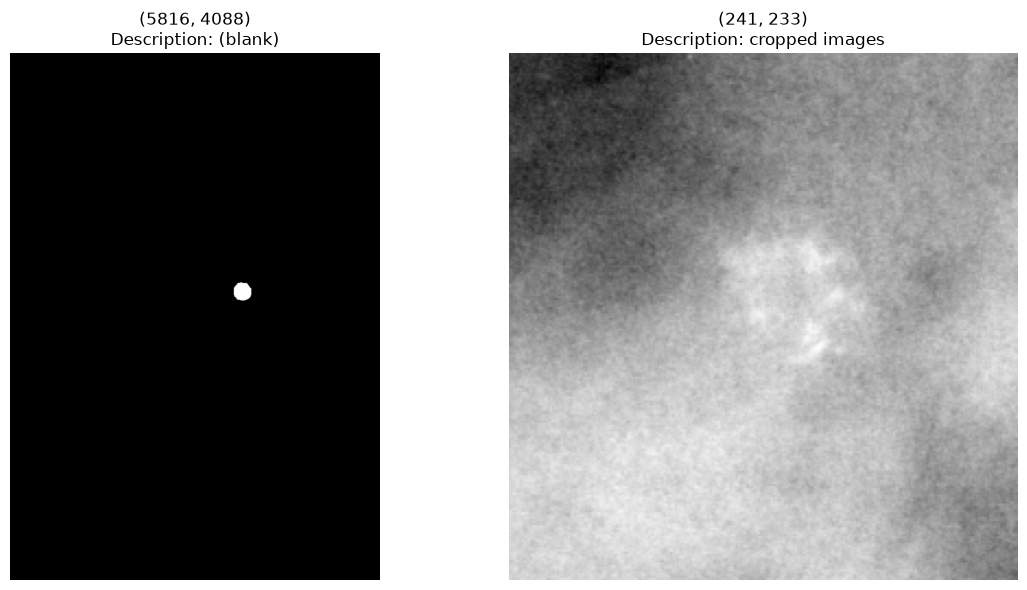

,relative_path,shape,dtype,unique_values,min,max,zero_ratio
0,P_01152_RIGHT_MLO_2.dcm\2017-08-29-45864\1-cro...,"(5816, 4088)",uint8,2,0,255,0.998673
1,P_01152_RIGHT_MLO_2.dcm\2017-08-29-45864\1-cro...,"(241, 233)",uint16,769,42965,65535,0.000000


In [28]:
# KIỂM TRA PIXEL CỦA CẶP DICOM MẪU

import pydicom
import numpy as np
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, len(sample_files), figsize=(12, 6))

if len(sample_files) == 1:
    axes = [axes]

pixel_records = []

for ax, (_, row) in zip(axes, sample_files.iterrows()):
    ds = pydicom.dcmread(
        row["file_path"],
        force=True
    )

    pixels = ds.pixel_array

    pixel_records.append({
        "relative_path": row["relative_path"],
        "shape": pixels.shape,
        "dtype": str(pixels.dtype),
        "unique_values": np.unique(pixels).size,
        "min": int(pixels.min()),
        "max": int(pixels.max()),
        "zero_ratio": float(np.mean(pixels == 0)),
    })

    ax.imshow(pixels, cmap="gray")
    ax.set_title(
        f"{pixels.shape}\n"
        f"Description: {getattr(ds, 'SeriesDescription', '') or '(blank)'}"
    )
    ax.axis("off")

plt.tight_layout()
plt.show()

pixel_summary = pd.DataFrame(pixel_records)
display(pixel_summary)

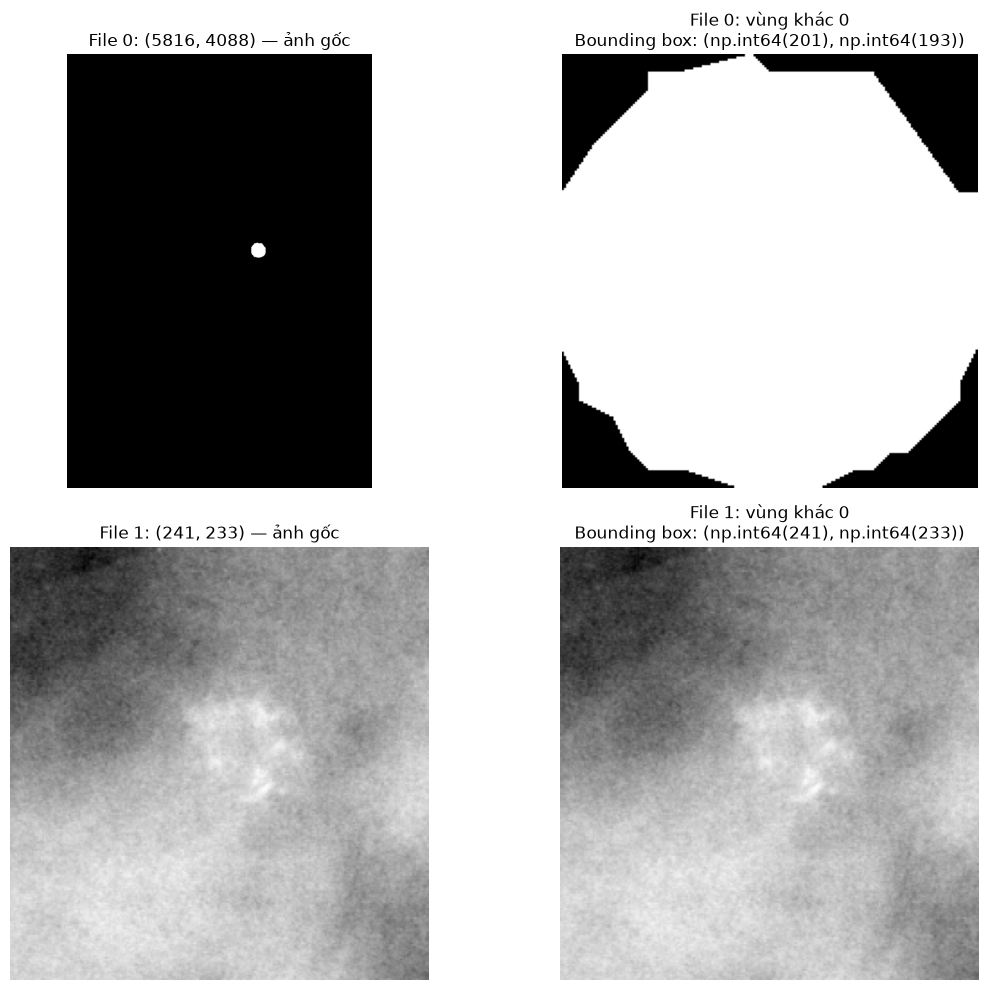

In [30]:
# KIỂM TRA VÙNG PIXEL KHÁC 0 CỦA HAI FILE

import pydicom
import numpy as np
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(12, 10))

for i, (_, row) in enumerate(sample_files.iterrows()):
    ds = pydicom.dcmread(row["file_path"], force=True)
    arr = ds.pixel_array

    # Ảnh gốc
    axes[i, 0].imshow(arr, cmap="gray")
    axes[i, 0].set_title(
        f"File {i}: {arr.shape} — ảnh gốc"
    )

    # Phóng vùng có pixel khác 0
    ys, xs = np.where(arr > 0)

    if len(xs) > 0:
        x0, x1 = xs.min(), xs.max()
        y0, y1 = ys.min(), ys.max()

        axes[i, 1].imshow(
            arr[y0:y1 + 1, x0:x1 + 1],
            cmap="gray"
        )
        axes[i, 1].set_title(
            f"File {i}: vùng khác 0\n"
            f"Bounding box: {(y1-y0+1, x1-x0+1)}"
        )
    else:
        axes[i, 1].set_title(f"File {i}: không có pixel khác 0")

    for ax in axes[i]:
        ax.axis("off")

plt.tight_layout()
plt.show()

In [33]:

# Tìm ca P_01152_RIGHT_MLO_2 trong các cột CSV
TARGET = "P_01152_RIGHT_MLO_2"

for df_name, df in [
    ("calc_test_df", calc_test_df),
    ("calc_train_df", calc_train_df),
    ("mass_test_df", mass_test_df),
    ("mass_train_df", mass_train_df),
]:
    print(f"\n{'=' * 20} {df_name} {'=' * 20}")

    # Tìm trong tất cả cột dạng text, không chỉ patient_id
    text_cols = df.select_dtypes(include=["object", "string"]).columns
    matched = pd.Series(False, index=df.index)

    for col in text_cols:
        matched |= df[col].astype("string").str.contains(
            TARGET, case=False, regex=False, na=False
        )

    result = df.loc[matched]

    print("Số dòng khớp:", len(result))

    if len(result):
        cols_to_show = [
            c for c in [
                "patient_id",
                "left or right breast",
                "image view",
                "abnormality id",
                "image file path",
                "cropped image file path",
                "ROI mask file path",
            ]
            if c in result.columns
        ]
        display(result[cols_to_show])



==================== calc_test_df ====================
Số dòng khớp: 1


,patient_id,left or right breast,image view,abnormality id,image file path,cropped image file path,ROI mask file path
174,P_01152,RIGHT,MLO,2,Calc-Test_P_01152_RIGHT_MLO/1.3.6.1.4.1.9590.1...,Calc-Test_P_01152_RIGHT_MLO_2/1.3.6.1.4.1.9590...,Calc-Test_P_01152_RIGHT_MLO_2/1.3.6.1.4.1.9590...



==================== calc_train_df ====================
Số dòng khớp: 0

==================== mass_test_df ====================
Số dòng khớp: 0

==================== mass_train_df ====================
Số dòng khớp: 0



--- Candidate index 9974 ---
Relative path: P_01152_RIGHT_MLO_2.dcm\2017-08-29-45864\1-cropped images-53079\d893c401-bfb8-4de0-928b-c1ba600a80ad.dcm
File exists: True

--- Candidate index 9975 ---
Relative path: P_01152_RIGHT_MLO_2.dcm\2017-08-29-45864\1-cropped images-53079\eed4841d-c9df-4e07-b6da-b72d88ef8271.dcm
File exists: True

Candidate 0
SeriesDescription: (blank)
Shape: (5816, 4088)
Dtype: uint8
Unique values: 2
Min / max: 0 / 255
Zero ratio: 0.998673
Non-zero bbox (x_min, y_min, x_max, y_max): (2472, 2528, 2664, 2728)
Non-zero pixel count: 31549

Candidate 1
SeriesDescription: cropped images
Shape: (241, 233)
Dtype: uint16
Unique values: 769
Min / max: 42965 / 65535
Zero ratio: 0.0
Non-zero bbox (x_min, y_min, x_max, y_max): (0, 0, 232, 240)
Non-zero pixel count: 56153


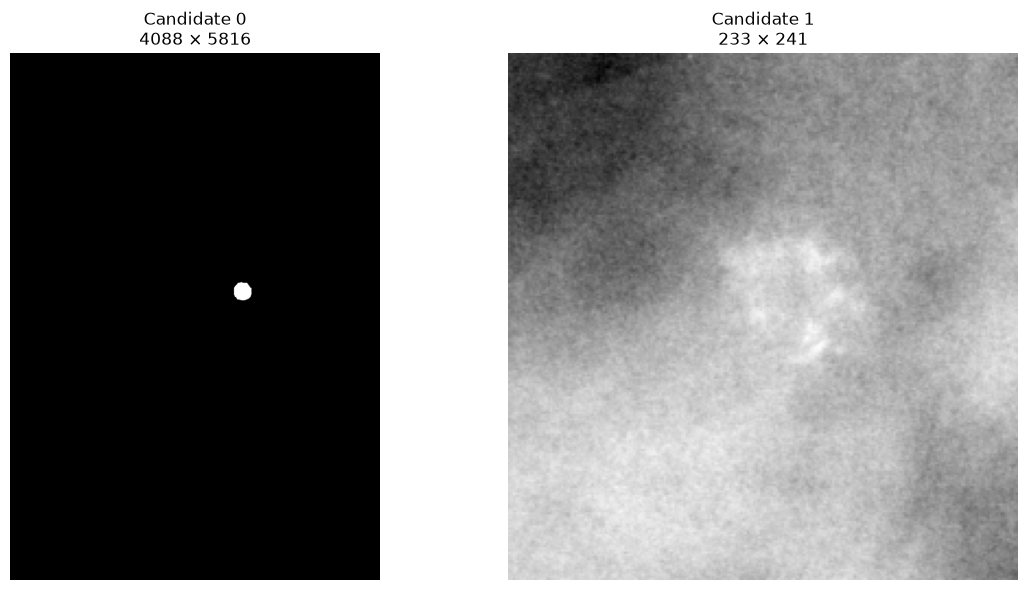

In [ ]:
# Phân tích hai DICOM ứng viên đã chọn

import numpy as np
import pydicom
import matplotlib.pyplot as plt
from pathlib import Path

# Lấy đúng hai dòng theo index đang được ghi nhận trong dicom_index.
# Kiểm tra trước khi đọc để tránh chọn nhầm nếu index thay đổi.
candidate_indices = [9974, 9975]

if not all(i in dicom_index.index for i in candidate_indices):
    raise KeyError(
        "Không tìm thấy index 9974/9975 trong dicom_index. "
        "Không tự chọn file khác; hãy kiểm tra lại hai dòng ứng viên."
    )

pair = dicom_index.loc[candidate_indices].copy()

for idx, row in pair.iterrows():
    print(f"\n--- Candidate index {idx} ---")
    print("Relative path:", row["relative_path"])
    print("File exists:", Path(row["file_path"]).is_file())

if not all(Path(p).is_file() for p in pair["file_path"]):
    raise FileNotFoundError("Có file ứng viên không tồn tại tại file_path đã ghi.")

datasets = [
    pydicom.dcmread(p, force=True)
    for p in pair["file_path"]
]

arrays = [ds.pixel_array for ds in datasets]

for i, (ds, arr) in enumerate(zip(datasets, arrays)):
    print(f"\nCandidate {i}")
    print("SeriesDescription:", getattr(ds, "SeriesDescription", "(blank)"))
    print("Shape:", arr.shape)
    print("Dtype:", arr.dtype)
    print("Unique values:", np.unique(arr).size)
    print("Min / max:", arr.min(), "/", arr.max())
    print("Zero ratio:", round(float(np.mean(arr == 0)), 6))

    # Bounding box của mọi pixel khác 0
    ys, xs = np.where(arr != 0)
    if len(xs):
        print(
            "Non-zero bbox (x_min, y_min, x_max, y_max):",
            (int(xs.min()), int(ys.min()), int(xs.max()), int(ys.max()))
        )
        print("Non-zero pixel count:", len(xs))
    else:
        print("Không có pixel khác 0.")

# Hiển thị từng ảnh riêng, không resize/overlay để tránh gây hiểu nhầm
fig, axes = plt.subplots(1, 2, figsize=(12, 6))

for i, (ax, arr) in enumerate(zip(axes, arrays)):
    ax.imshow(arr, cmap="gray")
    ax.set_title(
        f"Candidate {i}\n"
        f"{arr.shape[1]} × {arr.shape[0]}"
    )
    ax.axis("off")

plt.tight_layout()
plt.show()


In [36]:
# Xác minh DICOM instances của ca P_01152

TARGET_STUDY_UID = (
    "1.3.6.1.4.1.9590.100.1.2."
    "100052171312354035019149694722933145864"
)
TARGET_SERIES_UID = (
    "1.3.6.1.4.1.9590.100.1.2."
    "122021886313853636738943991213171853079"
)

# Lấy các DICOM đã có trong index, không quét file lần nữa
case_dicom = dicom_index[
    (dicom_index["StudyInstanceUID"] == TARGET_STUDY_UID)
    & (dicom_index["SeriesInstanceUID"] == TARGET_SERIES_UID)
].copy()

print("Số DICOM trong series:", len(case_dicom))

display(
    case_dicom[
        [
            "file_path",
            "relative_path",
            "PatientID",
            "StudyInstanceUID",
            "SeriesInstanceUID",
            "SOPInstanceUID",
            "SeriesDescription",
        ]
    ].reset_index(drop=True)
)

Số DICOM trong series: 2


,file_path,relative_path,PatientID,StudyInstanceUID,SeriesInstanceUID,SOPInstanceUID,SeriesDescription
0,C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_d...,P_01152_RIGHT_MLO_2.dcm\2017-08-29-45864\1-cro...,P_01152_RIGHT_MLO_2.dcm,1.3.6.1.4.1.9590.100.1.2.100052171312354035019...,1.3.6.1.4.1.9590.100.1.2.122021886313853636738...,1.3.6.1.4.1.9590.100.1.2.706644448126351071326...,
1,C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_d...,P_01152_RIGHT_MLO_2.dcm\2017-08-29-45864\1-cro...,Calc-Test_P_01152_RIGHT_MLO_2,1.3.6.1.4.1.9590.100.1.2.100052171312354035019...,1.3.6.1.4.1.9590.100.1.2.122021886313853636738...,1.3.6.1.4.1.9590.100.1.2.143025478211711725141...,cropped images


### Kết luận ca P_01152_RIGHT_MLO_2

| Thành phần | Kết quả xác định |
| :--- | :--- |
| **Ca bệnh** | P_01152 \| vú phải (RIGHT) \| tư thế MLO \| tổn thương số 2 |
| **Ảnh mammogram gốc** | Có cặp Study UID / Series UID riêng trong CSV |
| **Ảnh crop** | DICOM có `SeriesDescription` = cropped images, kích thước 241 × 233 |
| **ROI mask** | DICOM còn lại trong cùng series, kích thước 5816 × 4088, pixel chủ yếu bằng 0 |
| **Liên kết crop và mask** | Cùng Study UID và Series UID, nhưng khác SOP Instance UID |

In [ ]:
# Tổng hợp trạng thái các bảng hiện có
# Chỉ đọc DataFrame trong kernel; không sửa hoặc xóa dữ liệu.

tables = {
    "calc_test_df": calc_test_df,
    "calc_train_df": calc_train_df,
    "mass_test_df": mass_test_df,
    "mass_train_df": mass_train_df,
    "metadata_df": metadata_df,
    "dicom_index": dicom_index,
    "csv_path_index": csv_path_index,
    "dicom_candidates": dicom_candidates,
    "series_audit": series_audit,
}

summary_rows = []

for name, df in tables.items():
    try:
        duplicate_rows = int(df.duplicated().sum())
        duplicate_status = "OK"
    except TypeError:
        duplicate_rows = pd.NA
        duplicate_status = "Skipped: unhashable values"

    summary_rows.append({
        "table": name,
        "rows": len(df),
        "columns": len(df.columns),
        "duplicate_rows": duplicate_rows,
        "duplicate_check": duplicate_status,
        "missing_cells": int(df.isna().sum().sum()),
    })

notebook2_summary = pd.DataFrame(summary_rows)
display(notebook2_summary)

,table,rows,columns,duplicate_rows,duplicate_check,missing_cells
0,calc_test_df,326,14,0,OK,67
1,calc_train_df,1546,14,0,OK,396
2,mass_test_df,378,14,0,OK,17
3,mass_train_df,1318,14,0,OK,47
4,metadata_df,6775,23,0,OK,492
5,dicom_index,10239,7,0,OK,0
6,csv_path_index,10704,9,0,OK,0
7,dicom_candidates,17167,11,0,OK,0
8,series_audit,10239,7,<NA>,Skipped: unhashable values,0


In [ ]:
# So sánh patient_id giữa các split trong từng nhóm tổn thương.

split_frames = {
    "calc_train": calc_train_df,
    "calc_test": calc_test_df,
    "mass_train": mass_train_df,
    "mass_test": mass_test_df,
}

for name, df in split_frames.items():
    if "patient_id" not in df.columns:
        raise KeyError(f"{name} không có cột patient_id")

    print(
        f"{name}: {len(df)} dòng, "
        f"{df['patient_id'].nunique(dropna=True)} patient_id duy nhất, "
        f"{df['patient_id'].isna().sum()} patient_id bị thiếu"
    )

calc_train_ids = set(calc_train_df["patient_id"].dropna().astype(str))
calc_test_ids = set(calc_test_df["patient_id"].dropna().astype(str))

mass_train_ids = set(mass_train_df["patient_id"].dropna().astype(str))
mass_test_ids = set(mass_test_df["patient_id"].dropna().astype(str))

calc_overlap = calc_train_ids & calc_test_ids
mass_overlap = mass_train_ids & mass_test_ids

print("\n=== GIAO NHAU TRAIN / TEST ===")
print("Calcification — bệnh nhân xuất hiện ở cả train và test:", len(calc_overlap))
print("Mass — bệnh nhân xuất hiện ở cả train và test:", len(mass_overlap))

print("\n=== GIAO NHAU GIỮA LOẠI TỔN THƯƠNG ===")
print(
    "Calc train ∩ Mass test:",
    len(calc_train_ids & mass_test_ids)
)
print(
    "Mass train ∩ Calc test:",
    len(mass_train_ids & calc_test_ids)
)

calc_train: 1546 dòng, 602 patient_id duy nhất, 0 patient_id bị thiếu
calc_test: 326 dòng, 151 patient_id duy nhất, 0 patient_id bị thiếu
mass_train: 1318 dòng, 691 patient_id duy nhất, 0 patient_id bị thiếu
mass_test: 378 dòng, 201 patient_id duy nhất, 0 patient_id bị thiếu

=== GIAO NHAU TRAIN / TEST ===
Calcification — bệnh nhân xuất hiện ở cả train và test: 0
Mass — bệnh nhân xuất hiện ở cả train và test: 0

=== GIAO NHAU GIỮA LOẠI TỔN THƯƠNG ===
Calc train ∩ Mass test: 18
Mass train ∩ Calc test: 13


- Điểm cần chú ý: 18 và 13 trường hợp giao nhau giữa loại tổn thương cho thấy các split calcification và mass có thể được tạo độc lập.

In [40]:
# kiểm tra leakage khi gộp cả hai loại tổn thương

train_ids_all = (
    set(calc_train_df["patient_id"].dropna().astype(str))
    | set(mass_train_df["patient_id"].dropna().astype(str))
)

test_ids_all = (
    set(calc_test_df["patient_id"].dropna().astype(str))
    | set(mass_test_df["patient_id"].dropna().astype(str))
)

combined_overlap = train_ids_all & test_ids_all

print("Số bệnh nhân duy nhất trong train gộp:", len(train_ids_all))
print("Số bệnh nhân duy nhất trong test gộp:", len(test_ids_all))
print("Số bệnh nhân giao nhau train/test:", len(combined_overlap))

if combined_overlap:
    print("\nDanh sách patient_id giao nhau:")
    display(
        pd.DataFrame({
            "patient_id": sorted(combined_overlap)
        })
    )
else:
    print("Không phát hiện patient_id giao nhau trong hai tập gộp.")

Số bệnh nhân duy nhất trong train gộp: 1248
Số bệnh nhân duy nhất trong test gộp: 349
Số bệnh nhân giao nhau train/test: 31

Danh sách patient_id giao nhau:


,patient_id
0,P_00016
1,P_00041
2,P_00159
3,P_00394
4,P_00495
5,P_00510
6,P_00591
7,P_00601
8,P_00639
9,P_00652


- Có 31 bệnh nhân giao nhau giữa train và test khi gộp hai loại tổn thương, dù mỗi loại riêng lẻ không có giao nhau. 
- Nếu xây dựng một mô hình chung sử dụng cả hai loại, cần chia lại dữ liệu theo patient_id trước khi huấn luyện và đánh giá.

In [41]:
# Audit chi tiết 31 bệnh nhân giao nhau
# lưu bằng chứng leakage và xác định split của từng bệnh nhân
overlap_detail = []

for patient_id in sorted(combined_overlap):
    overlap_detail.append({
        "patient_id": patient_id,
        "calc_train": patient_id in calc_train_ids,
        "calc_test": patient_id in calc_test_ids,
        "mass_train": patient_id in mass_train_ids,
        "mass_test": patient_id in mass_test_ids,
    })

overlap_detail_df = pd.DataFrame(overlap_detail)

print("Số bệnh nhân được audit:", len(overlap_detail_df))
print("\nSố bệnh nhân theo tổ hợp split:")
display(
    overlap_detail_df[
        ["calc_train", "calc_test", "mass_train", "mass_test"]
    ].value_counts(dropna=False).rename("patient_count").reset_index()
)

print("\nDanh sách chi tiết:")
display(overlap_detail_df)

Số bệnh nhân được audit: 31

Số bệnh nhân theo tổ hợp split:


,calc_train,calc_test,mass_train,mass_test,patient_count
0,True,False,False,True,18
1,False,True,True,False,13



Danh sách chi tiết:


,patient_id,calc_train,calc_test,mass_train,mass_test
0,P_00016,True,False,False,True
1,P_00041,False,True,True,False
2,P_00159,True,False,False,True
3,P_00394,True,False,False,True
4,P_00495,False,True,True,False
5,P_00510,True,False,False,True
6,P_00591,True,False,False,True
7,P_00601,True,False,False,True
8,P_00639,True,False,False,True
9,P_00652,True,False,False,True


# 31 trường hợp:
- 18 bệnh nhân thuộc calc_train nhưng mass_test; 
- 13 bệnh nhân thuộc calc_test nhưng mass_train. 
- Không có trường hợp nào giao nhau giữa train/test bên trong từng loại tổn thương, nhưng có giao nhau khi gộp hai loại.

In [42]:
#Tổng hợp liên kết CSV ↔ DICOM theo UID

# Một bản ghi cho mỗi loại đường dẫn và cặp Study/Series UID
csv_uid_pairs = (
    csv_path_index
    .dropna(subset=["study_uid", "series_uid"])
    [["split", "path_type", "study_uid", "series_uid"]]
    .drop_duplicates()
    .copy()
)

# Các cặp UID hiện diện trong DICOM index
dicom_uid_pairs = (
    dicom_index
    .dropna(subset=["StudyInstanceUID", "SeriesInstanceUID"])
    [["StudyInstanceUID", "SeriesInstanceUID"]]
    .drop_duplicates()
    .rename(columns={
        "StudyInstanceUID": "study_uid",
        "SeriesInstanceUID": "series_uid",
    })
)

# Đối chiếu theo cả Study UID và Series UID
csv_uid_pairs["uid_match"] = csv_uid_pairs.set_index(
    ["study_uid", "series_uid"]
).index.isin(
    dicom_uid_pairs.set_index(
        ["study_uid", "series_uid"]
    ).index
)

uid_linkage_summary = (
    csv_uid_pairs
    .groupby(["split", "path_type"], dropna=False)
    .agg(
        unique_uid_pairs=("series_uid", "size"),
        matched_uid_pairs=("uid_match", "sum"),
        unmatched_uid_pairs=("uid_match", lambda s: (~s).sum()),
    )
    .reset_index()
)

display(uid_linkage_summary)

,split,path_type,unique_uid_pairs,matched_uid_pairs,unmatched_uid_pairs
0,calc_test,ROI mask file path,326,326,0
1,calc_test,cropped image file path,326,326,0
2,calc_test,image file path,284,284,0
3,calc_train,ROI mask file path,1546,1546,0
4,calc_train,cropped image file path,1546,1546,0
5,calc_train,image file path,1227,1227,0
6,mass_test,ROI mask file path,378,378,0
7,mass_test,cropped image file path,378,378,0
8,mass_test,image file path,361,361,0
9,mass_train,ROI mask file path,1318,1318,0


- Nếu unmatched_uid_pairs > 0: lập danh sách các cặp UID chưa tìm thấy, không tự động coi là file bị mất.
- Nếu UID khớp: xác nhận được mức series, chưa chắc đã xác nhận đúng ảnh cụ thể.
- Sau đó mới tổng hợp trạng thái liên kết ảnh toàn phần, crop và mask; lưu bảng liên kết cùng báo cáo lỗi.

In [43]:
# Phân loại mức độ liên kết theo số DICOM ứng viên

required_cols = {
    "path_type",
    "study_uid",
    "series_uid",
    "file_path",
    "SeriesDescription",
}

missing_cols = required_cols - set(dicom_candidates.columns)
if missing_cols:
    raise KeyError(f"dicom_candidates thiếu cột: {sorted(missing_cols)}")

# Mỗi path_type + cặp UID là một đơn vị liên kết cần đánh giá
candidate_audit = (
    dicom_candidates
    .groupby(
        ["path_type", "study_uid", "series_uid"],
        dropna=False
    )
    .agg(
        candidate_count=("file_path", "nunique"),
        dicom_descriptions=(
            "SeriesDescription",
            lambda s: sorted({
                str(v).strip()
                for v in s.dropna()
                if str(v).strip()
            })
        ),
    )
    .reset_index()
)

def classify_candidates(n):
    if n == 0:
        return "unmatched"
    if n == 1:
        return "single_candidate"
    return "ambiguous_multiple_candidates"

candidate_audit["linkage_status"] = (
    candidate_audit["candidate_count"].map(classify_candidates)
)

linkage_status_summary = (
    candidate_audit
    .groupby(["path_type", "linkage_status"], dropna=False)
    .size()
    .unstack(fill_value=0)
    .reset_index()
)

print("=== Tổng hợp trạng thái ứng viên ===")
display(linkage_status_summary)

print("\n=== Các trường hợp có nhiều ứng viên ===")
ambiguous_cases = candidate_audit[
    candidate_audit["linkage_status"] == "ambiguous_multiple_candidates"
].copy()

print("Số cặp UID có nhiều ứng viên:", len(ambiguous_cases))
display(ambiguous_cases.head(20))

=== Tổng hợp trạng thái ứng viên ===


linkage_status,path_type,ambiguous_multiple_candidates,single_candidate
0,ROI mask file path,3464,104
1,cropped image file path,3464,104
2,image file path,0,3103



=== Các trường hợp có nhiều ứng viên ===
Số cặp UID có nhiều ứng viên: 6928


,path_type,study_uid,series_uid,candidate_count,dicom_descriptions,linkage_status
0,ROI mask file path,1.3.6.1.4.1.9590.100.1.2.100052171312354035019...,1.3.6.1.4.1.9590.100.1.2.122021886313853636738...,2,[cropped images],ambiguous_multiple_candidates
1,ROI mask file path,1.3.6.1.4.1.9590.100.1.2.100098988611658610916...,1.3.6.1.4.1.9590.100.1.2.238692425413084528531...,2,"[ROI mask images, cropped images]",ambiguous_multiple_candidates
2,ROI mask file path,1.3.6.1.4.1.9590.100.1.2.100174331811273020524...,1.3.6.1.4.1.9590.100.1.2.336461944129250751191...,2,"[ROI mask images, cropped images]",ambiguous_multiple_candidates
3,ROI mask file path,1.3.6.1.4.1.9590.100.1.2.100315322123261388182...,1.3.6.1.4.1.9590.100.1.2.302933455011192630233...,2,"[ROI mask images, cropped images]",ambiguous_multiple_candidates
4,ROI mask file path,1.3.6.1.4.1.9590.100.1.2.100690047611037343129...,1.3.6.1.4.1.9590.100.1.2.208241331295544100956...,2,"[ROI mask images, cropped images]",ambiguous_multiple_candidates
5,ROI mask file path,1.3.6.1.4.1.9590.100.1.2.100755775212934181821...,1.3.6.1.4.1.9590.100.1.2.345522512011144937217...,2,"[ROI mask images, cropped images]",ambiguous_multiple_candidates
6,ROI mask file path,1.3.6.1.4.1.9590.100.1.2.100769249412095527537...,1.3.6.1.4.1.9590.100.1.2.185458895911348090008...,2,"[ROI mask images, cropped images]",ambiguous_multiple_candidates
7,ROI mask file path,1.3.6.1.4.1.9590.100.1.2.101147117911548067036...,1.3.6.1.4.1.9590.100.1.2.256561854511804734619...,2,[cropped images],ambiguous_multiple_candidates
8,ROI mask file path,1.3.6.1.4.1.9590.100.1.2.101435457512184805722...,1.3.6.1.4.1.9590.100.1.2.310970334811442196939...,2,"[ROI mask images, cropped images]",ambiguous_multiple_candidates
9,ROI mask file path,1.3.6.1.4.1.9590.100.1.2.101509568711183261828...,1.3.6.1.4.1.9590.100.1.2.409108935412704052237...,2,"[ROI mask images, cropped images]",ambiguous_multiple_candidates


| Loại đường dẫn | Cặp UID có 1 ứng viên | Cặp UID có 2 ứng viên |
| :--- | :---: | :---: |
| **ROI mask** | 104 | 3.464 |
| **Ảnh crop** | 104 | 3.464 |
| **Ảnh toàn phần** | 3.103 | 0 |

- 3.464 cặp UID của ROI mask và 3.464 cặp UID của ảnh crop không có nghĩa là 6.928 ca khác nhau. Đây là các cặp được tính theo từng loại đường dẫn; cùng một cặp UID có thể xuất hiện ở cả hai loại.

- Đối với các cặp có hai DICOM, mô tả series giúp phân biệt một phần nhưng không phải lúc nào cũng đủ. Ca P_01152_RIGHT_MLO_2 cho thấy một instance có SeriesDescription trống nhưng đặc điểm pixel phù hợp với mask, trong khi instance còn lại được mô tả là cropped images.

In [44]:
# Tạo bảng liên kết và lưu báo cá

# 1. Thư mục đầu ra
PROJECT_ROOT = Path(r"C:\Breast-Cancer-CBIS-DDSM")
OUTPUT_DIR = PROJECT_ROOT / "Data" / "processed"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# 2. Tổng hợp số DICOM ứng viên cho từng loại đường dẫn và cặp UID
candidate_counts = (
    dicom_candidates
    .groupby(
        ["path_type", "study_uid", "series_uid"],
        dropna=False
    )
    .agg(
        candidate_count=("file_path", "nunique"),
        candidate_paths=(
            "relative_path",
            lambda s: sorted(set(s.dropna().astype(str)))
        ),
        candidate_sop_uids=(
            "SOPInstanceUID",
            lambda s: sorted(set(s.dropna().astype(str)))
        ),
        series_descriptions=(
            "SeriesDescription",
            lambda s: sorted({
                str(v).strip()
                for v in s.dropna()
                if str(v).strip()
            })
        ),
    )
    .reset_index()
)

# 3. Gắn thông tin ứng viên vào từng đường dẫn CSV
verified_linkage_table = csv_path_index.merge(
    candidate_counts,
    on=["path_type", "study_uid", "series_uid"],
    how="left",
    validate="many_to_one"
)

verified_linkage_table["candidate_count"] = (
    verified_linkage_table["candidate_count"]
    .fillna(0)
    .astype(int)
)

def linkage_status(n):
    if n == 0:
        return "unmatched"
    if n == 1:
        return "single_instance_candidate"
    return "multiple_instances_role_unverified"

verified_linkage_table["linkage_status"] = (
    verified_linkage_table["candidate_count"].map(linkage_status)
)

# 4. Bảng tổng hợp trạng thái
linkage_summary = (
    verified_linkage_table
    .groupby(["split", "path_type", "linkage_status"])
    .size()
    .rename("path_rows")
    .reset_index()
)

# 5. Danh sách các đường dẫn cần chú ý
linkage_issues = verified_linkage_table[
    verified_linkage_table["linkage_status"] !=
    "single_instance_candidate"
].copy()

# 6. Lưu danh sách bệnh nhân giao nhau
overlap_detail_df.to_csv(
    OUTPUT_DIR / "nb02_patient_split_overlap.csv",
    index=False,
    encoding="utf-8-sig"
)

# 7. Lưu các bảng liên kết và báo cáo
verified_linkage_table.to_csv(
    OUTPUT_DIR / "nb02_csv_dicom_linkage.csv",
    index=False,
    encoding="utf-8-sig"
)

linkage_summary.to_csv(
    OUTPUT_DIR / "nb02_linkage_summary.csv",
    index=False,
    encoding="utf-8-sig"
)

linkage_issues.to_csv(
    OUTPUT_DIR / "nb02_linkage_review.csv",
    index=False,
    encoding="utf-8-sig"
)

notebook2_summary.to_csv(
    OUTPUT_DIR / "nb02_table_quality_summary.csv",
    index=False,
    encoding="utf-8-sig"
)

# 8. Báo cáo văn bản
report_lines = [
    "NOTEBOOK 02 — DATA QUALITY AND LINKAGE",
    "",
    "1. CSV input",
    f"- calc_test_df: {len(calc_test_df)} rows",
    f"- calc_train_df: {len(calc_train_df)} rows",
    f"- mass_test_df: {len(mass_test_df)} rows",
    f"- mass_train_df: {len(mass_train_df)} rows",
    f"- Total lesion CSV rows: "
    f"{len(calc_test_df) + len(calc_train_df) + len(mass_test_df) + len(mass_train_df)}",
    "",
    "2. DICOM index",
    f"- Indexed DICOM files: {len(dicom_index)}",
    f"- CSV path references: {len(csv_path_index)}",
    "",
    "3. Linkage",
    "- All CSV Study UID / Series UID pairs matched the DICOM index "
    "in the previous UID audit.",
    "- Multiple DICOM instances may share a Study UID / Series UID pair.",
    "- Multiple-instance links are not automatically considered verified "
    "at the individual-image-role level.",
    "",
    "4. Train/test leakage",
    f"- Calcification train/test overlap: {len(calc_overlap)} patients",
    f"- Mass train/test overlap: {len(mass_overlap)} patients",
    f"- Combined train/test overlap: {len(combined_overlap)} patients",
    "- The combined overlap must be addressed if building a unified model.",
    "",
    "5. Limitations",
    "- UID matching does not by itself prove exact image-role matching.",
    "- Full pixel-level crop/mask correspondence has not been verified "
    "for every case.",
    "- This audit does not establish that every DICOM pixel array is valid.",
    "",
    "6. Output tables",
    "- nb02_csv_dicom_linkage.csv",
    "- nb02_linkage_summary.csv",
    "- nb02_linkage_review.csv",
    "- nb02_patient_split_overlap.csv",
    "- nb02_table_quality_summary.csv",
]

report_path = OUTPUT_DIR / "nb02_data_quality_report.txt"
report_path.write_text("\n".join(report_lines), encoding="utf-8")

print("Đã tạo các bảng và báo cáo tại:")
print(OUTPUT_DIR)

print("\nTổng hợp trạng thái liên kết:")
display(linkage_summary)

print("\nSố dòng cần xem xét thêm:", len(linkage_issues))
print("Báo cáo:", report_path)

Đã tạo các bảng và báo cáo tại:
C:\Breast-Cancer-CBIS-DDSM\Data\processed

Tổng hợp trạng thái liên kết:


,split,path_type,linkage_status,path_rows
0,calc_test,ROI mask file path,multiple_instances_role_unverified,326
1,calc_test,cropped image file path,multiple_instances_role_unverified,326
2,calc_test,image file path,single_instance_candidate,326
3,calc_train,ROI mask file path,multiple_instances_role_unverified,1545
4,calc_train,ROI mask file path,single_instance_candidate,1
5,calc_train,cropped image file path,multiple_instances_role_unverified,1545
6,calc_train,cropped image file path,single_instance_candidate,1
7,calc_train,image file path,single_instance_candidate,1546
8,mass_test,ROI mask file path,multiple_instances_role_unverified,367
9,mass_test,ROI mask file path,single_instance_candidate,11



Số dòng cần xem xét thêm: 6928
Báo cáo: C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb02_data_quality_report.txt


In [45]:
# KIỂM TRA CÁC BẢNG ĐÃ CÓ
# Mục tiêu: chuẩn bị phân biệt full image / crop / ROI mask

required_tables = [
    "dicom_index",
    "dicom_candidates",
    "csv_path_index",
]

for table_name in required_tables:
    if table_name not in globals():
        print(f"[MISSING] {table_name}")
        continue

    table = globals()[table_name]

    print(f"\n{'=' * 65}")
    print(f"BẢNG: {table_name}")
    print(f"Kích thước: {table.shape[0]:,} dòng × {table.shape[1]} cột")
    print("Các cột:")
    print(list(table.columns))

print("\n[INFO] Chỉ kiểm tra biến trong kernel, không quét file DICOM.")



BẢNG: dicom_index
Kích thước: 10,239 dòng × 7 cột
Các cột:
['file_path', 'relative_path', 'PatientID', 'StudyInstanceUID', 'SeriesInstanceUID', 'SOPInstanceUID', 'SeriesDescription']

BẢNG: dicom_candidates
Kích thước: 17,167 dòng × 11 cột
Các cột:
['path_type', 'study_uid', 'series_uid', 'file_path', 'relative_path', 'PatientID', 'StudyInstanceUID', 'SeriesInstanceUID', 'SOPInstanceUID', 'SeriesDescription', '_merge']

BẢNG: csv_path_index
Kích thước: 10,704 dòng × 9 cột
Các cột:
['split', 'csv_row', 'path_type', 'csv_path', 'case_folder', 'study_uid', 'series_uid', 'alias_filename', 'path_components']

[INFO] Chỉ kiểm tra biến trong kernel, không quét file DICOM.


In [46]:
# TẠO BẢNG RÀ SOÁT INSTANCE

# 1. Kiểm tra các cột bắt buộc
required_candidate_cols = [
    "path_type",
    "study_uid",
    "series_uid",
    "file_path",
    "relative_path",
    "SOPInstanceUID",
    "SeriesDescription",
]

missing_cols = [
    col for col in required_candidate_cols
    if col not in dicom_candidates.columns
]

if missing_cols:
    raise ValueError(f"Thiếu cột trong dicom_candidates: {missing_cols}")

# 2. Giữ mỗi DICOM instance duy nhất trong từng cặp UID và vai trò CSV.
# Không dùng alias_filename để xác định danh tính DICOM.
instance_records = dicom_candidates[
    required_candidate_cols
].drop_duplicates(
    subset=[
        "path_type",
        "study_uid",
        "series_uid",
        "SOPInstanceUID",
        "file_path",
    ]
).copy()

# 3. Gom thông tin theo vai trò CSV và cặp Study/Series UID.
def unique_nonempty(series):
    values = series.dropna().astype(str).str.strip()
    values = sorted(set(v for v in values if v))
    return values

instance_role_review = (
    instance_records
    .groupby(
        ["path_type", "study_uid", "series_uid"],
        dropna=False
    )
    .agg(
        candidate_count=("SOPInstanceUID", "nunique"),
        sop_instance_uids=("SOPInstanceUID", unique_nonempty),
        series_descriptions=("SeriesDescription", unique_nonempty),
        candidate_paths=("file_path", unique_nonempty),
    )
    .reset_index()
)

# 4. Gắn trạng thái rà soát ban đầu.
# Đây là trạng thái theo số ứng viên, chưa phải xác minh vai trò ảnh.
instance_role_review["review_status"] = (
    instance_role_review["candidate_count"]
    .map({
        0: "unmatched",
        1: "single_instance_candidate",
    })
    .fillna("multiple_instances_role_unverified")
)

print("Số nhóm UID cần rà soát:", len(instance_role_review))
print("\nPhân bố trạng thái:")
display(
    instance_role_review["review_status"]
    .value_counts(dropna=False)
    .rename_axis("review_status")
    .reset_index(name="group_count")
)

print("\nPhân bố số ứng viên theo vai trò CSV:")
display(
    instance_role_review
    .groupby(["path_type", "candidate_count"], dropna=False)
    .size()
    .reset_index(name="group_count")
    .sort_values(["path_type", "candidate_count"])
)

print("\nMột số nhóm có nhiều instance:")
display(
    instance_role_review
    .query("candidate_count > 1")
    .head(10)
)

print("\n[OK] Đã tạo instance_role_review.")
print("[INFO] Chưa tự động xác nhận instance nào là crop hay ROI mask.")


Số nhóm UID cần rà soát: 10239

Phân bố trạng thái:


,review_status,group_count
0,multiple_instances_role_unverified,6928
1,single_instance_candidate,3311



Phân bố số ứng viên theo vai trò CSV:


,path_type,candidate_count,group_count
0,ROI mask file path,1,104
1,ROI mask file path,2,3464
2,cropped image file path,1,104
3,cropped image file path,2,3464
4,image file path,1,3103



Một số nhóm có nhiều instance:


,path_type,study_uid,series_uid,candidate_count,sop_instance_uids,series_descriptions,candidate_paths,review_status
0,ROI mask file path,1.3.6.1.4.1.9590.100.1.2.100052171312354035019...,1.3.6.1.4.1.9590.100.1.2.122021886313853636738...,2,[1.3.6.1.4.1.9590.100.1.2.14302547821171172514...,[cropped images],[C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_...,multiple_instances_role_unverified
1,ROI mask file path,1.3.6.1.4.1.9590.100.1.2.100098988611658610916...,1.3.6.1.4.1.9590.100.1.2.238692425413084528531...,2,[1.3.6.1.4.1.9590.100.1.2.12621728301006500234...,"[ROI mask images, cropped images]",[C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_...,multiple_instances_role_unverified
2,ROI mask file path,1.3.6.1.4.1.9590.100.1.2.100174331811273020524...,1.3.6.1.4.1.9590.100.1.2.336461944129250751191...,2,[1.3.6.1.4.1.9590.100.1.2.20588133731213196311...,"[ROI mask images, cropped images]",[C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_...,multiple_instances_role_unverified
3,ROI mask file path,1.3.6.1.4.1.9590.100.1.2.100315322123261388182...,1.3.6.1.4.1.9590.100.1.2.302933455011192630233...,2,[1.3.6.1.4.1.9590.100.1.2.39336598061126140503...,"[ROI mask images, cropped images]",[C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_...,multiple_instances_role_unverified
4,ROI mask file path,1.3.6.1.4.1.9590.100.1.2.100690047611037343129...,1.3.6.1.4.1.9590.100.1.2.208241331295544100956...,2,[1.3.6.1.4.1.9590.100.1.2.38498004361306064451...,"[ROI mask images, cropped images]",[C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_...,multiple_instances_role_unverified
5,ROI mask file path,1.3.6.1.4.1.9590.100.1.2.100755775212934181821...,1.3.6.1.4.1.9590.100.1.2.345522512011144937217...,2,[1.3.6.1.4.1.9590.100.1.2.29858990711240701072...,"[ROI mask images, cropped images]",[C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_...,multiple_instances_role_unverified
6,ROI mask file path,1.3.6.1.4.1.9590.100.1.2.100769249412095527537...,1.3.6.1.4.1.9590.100.1.2.185458895911348090008...,2,[1.3.6.1.4.1.9590.100.1.2.11066253981090472582...,"[ROI mask images, cropped images]",[C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_...,multiple_instances_role_unverified
7,ROI mask file path,1.3.6.1.4.1.9590.100.1.2.101147117911548067036...,1.3.6.1.4.1.9590.100.1.2.256561854511804734619...,2,[1.3.6.1.4.1.9590.100.1.2.15990654561124537620...,[cropped images],[C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_...,multiple_instances_role_unverified
8,ROI mask file path,1.3.6.1.4.1.9590.100.1.2.101435457512184805722...,1.3.6.1.4.1.9590.100.1.2.310970334811442196939...,2,[1.3.6.1.4.1.9590.100.1.2.15177339651319050893...,"[ROI mask images, cropped images]",[C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_...,multiple_instances_role_unverified
9,ROI mask file path,1.3.6.1.4.1.9590.100.1.2.101509568711183261828...,1.3.6.1.4.1.9590.100.1.2.409108935412704052237...,2,[1.3.6.1.4.1.9590.100.1.2.16040711641247418203...,"[ROI mask images, cropped images]",[C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_...,multiple_instances_role_unverified



[OK] Đã tạo instance_role_review.
[INFO] Chưa tự động xác nhận instance nào là crop hay ROI mask.


In [47]:
# KIỂM TRA MỘT CA MẪU
# Chỉ đọc DICOM của P_01152_RIGHT_MLO_2

from pathlib import Path
import numpy as np
import pandas as pd
import pydicom

# 1. Tìm các instance thuộc ca mẫu trong index đã có
sample_rows = dicom_index[
    dicom_index["relative_path"].astype(str).str.contains(
        "P_01152_RIGHT_MLO_2.dcm",
        case=False,
        regex=False
    )
].copy()

if sample_rows.empty:
    raise ValueError(
        "Không tìm thấy ca mẫu trong dicom_index. "
        "Không tự động quét lại dataset."
    )

print("Số instance tìm được:", len(sample_rows))
display(
    sample_rows[
        [
            "relative_path",
            "PatientID",
            "StudyInstanceUID",
            "SeriesInstanceUID",
            "SOPInstanceUID",
            "SeriesDescription",
        ]
    ]
)

# 2. Đọc metadata và pixel của riêng các instance đã tìm thấy
pixel_results = []

for _, row in sample_rows.iterrows():
    path = Path(row["file_path"])

    if not path.is_file():
        print(f"[MISSING FILE] {path}")
        continue

    ds = pydicom.dcmread(str(path))

    result = {
        "relative_path": row["relative_path"],
        "SOPInstanceUID": str(
            getattr(ds, "SOPInstanceUID", "")
        ),
        "SeriesDescription": str(
            getattr(ds, "SeriesDescription", "")
        ),
        "Rows": getattr(ds, "Rows", None),
        "Columns": getattr(ds, "Columns", None),
        "SamplesPerPixel": getattr(ds, "SamplesPerPixel", None),
        "PhotometricInterpretation": getattr(
            ds, "PhotometricInterpretation", None
        ),
        "BitsAllocated": getattr(ds, "BitsAllocated", None),
        "BitsStored": getattr(ds, "BitsStored", None),
    }

    try:
        arr = ds.pixel_array
        result["pixel_dtype"] = str(arr.dtype)
        result["pixel_min"] = int(arr.min())
        result["pixel_max"] = int(arr.max())
        result["unique_pixel_values"] = int(np.unique(arr).size)
        result["zero_ratio"] = float(np.mean(arr == 0))

        # Bounding box của toàn bộ pixel khác 0, chỉ để mô tả.
        # Không coi đây là bounding box tổn thương nếu chưa xác minh mask.
        nonzero = np.argwhere(arr != 0)

        if nonzero.size:
            result["nonzero_bbox_yxyx"] = (
                int(nonzero[:, 0].min()),
                int(nonzero[:, 1].min()),
                int(nonzero[:, 0].max()) + 1,
                int(nonzero[:, 1].max()) + 1,
            )
        else:
            result["nonzero_bbox_yxyx"] = None

    except Exception as exc:
        result["pixel_error"] = str(exc)

    pixel_results.append(result)

sample_pixel_audit = pd.DataFrame(pixel_results)

print("\nKẾT QUẢ KIỂM TRA CA MẪU")
display(sample_pixel_audit)

print(
    "\n[INFO] Chỉ kiểm tra ca mẫu; chưa gán vai trò "
    "cho toàn bộ DICOM instance."
)


Số instance tìm được: 2


,relative_path,PatientID,StudyInstanceUID,SeriesInstanceUID,SOPInstanceUID,SeriesDescription
9974,P_01152_RIGHT_MLO_2.dcm\2017-08-29-45864\1-cro...,P_01152_RIGHT_MLO_2.dcm,1.3.6.1.4.1.9590.100.1.2.100052171312354035019...,1.3.6.1.4.1.9590.100.1.2.122021886313853636738...,1.3.6.1.4.1.9590.100.1.2.706644448126351071326...,
9975,P_01152_RIGHT_MLO_2.dcm\2017-08-29-45864\1-cro...,Calc-Test_P_01152_RIGHT_MLO_2,1.3.6.1.4.1.9590.100.1.2.100052171312354035019...,1.3.6.1.4.1.9590.100.1.2.122021886313853636738...,1.3.6.1.4.1.9590.100.1.2.143025478211711725141...,cropped images



KẾT QUẢ KIỂM TRA CA MẪU


,relative_path,SOPInstanceUID,SeriesDescription,Rows,Columns,SamplesPerPixel,PhotometricInterpretation,BitsAllocated,BitsStored,pixel_dtype,pixel_min,pixel_max,unique_pixel_values,zero_ratio,nonzero_bbox_yxyx
0,P_01152_RIGHT_MLO_2.dcm\2017-08-29-45864\1-cro...,1.3.6.1.4.1.9590.100.1.2.706644448126351071326...,,5816,4088,1,MONOCHROME2,8,8,uint8,0,255,2,0.998673,"(2528, 2472, 2729, 2665)"
1,P_01152_RIGHT_MLO_2.dcm\2017-08-29-45864\1-cro...,1.3.6.1.4.1.9590.100.1.2.143025478211711725141...,cropped images,241,233,1,MONOCHROME2,16,16,uint16,42965,65535,769,0.000000,"(0, 0, 241, 233)"



[INFO] Chỉ kiểm tra ca mẫu; chưa gán vai trò cho toàn bộ DICOM instance.


- instance thứ hai là ảnh crop với độ tin cậy cao, vì SeriesDescription = cropped images, kích thước chỉ 241 x 233, và có 769 giá trị pixel khác nhau.
- Instance thứ nhất có đặc điểm rất phù hợp với ROI mask: ảnh 5816 x 4088, chỉ có hai giá trị pixel là 0 và 255, và hơn 99,8% pixel bằng 0.

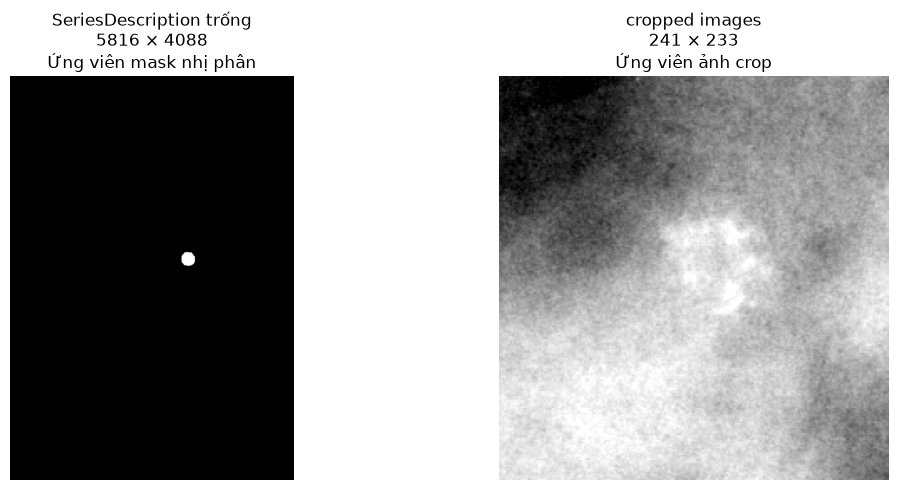

In [48]:
# KIỂM TRA TRỰC QUAN CA MẪU
# Chỉ hiển thị 2 DICOM instance đã đọc ở bước trước.

import matplotlib.pyplot as plt
import numpy as np
import pydicom
from pathlib import Path

if len(sample_rows) != 2:
    raise ValueError(
        f"Cần đúng 2 instance trong ca mẫu; hiện có {len(sample_rows)}."
    )

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, (_, row) in zip(axes, sample_rows.iterrows()):
    ds = pydicom.dcmread(str(row["file_path"]))
    arr = ds.pixel_array

    desc = str(getattr(ds, "SeriesDescription", "")).strip()
    if not desc:
        desc = "SeriesDescription trống"

    if arr.ndim == 2 and np.unique(arr).size <= 2:
        # Ảnh nhị phân: hiển thị nguyên trạng
        ax.imshow(arr, cmap="gray", vmin=0, vmax=255)
        display_type = "Ứng viên mask nhị phân"
    else:
        # Ảnh crop: điều chỉnh tương phản chỉ để quan sát
        lo, hi = np.percentile(arr, [1, 99])
        if hi <= lo:
            lo, hi = float(arr.min()), float(arr.max())

        ax.imshow(arr, cmap="gray", vmin=lo, vmax=hi)
        display_type = "Ứng viên ảnh crop"

    ax.set_title(
        f"{desc}\n{arr.shape[0]} × {arr.shape[1]}\n{display_type}"
    )
    ax.axis("off")

plt.tight_layout()
plt.show()


- proposed_role: vai trò dự đoán từ metadata và đặc trưng ảnh.

- confidence_reason: lý do gán nhãn, để biết quy tắc nào đã được dùng.

- review_status: trường hợp nào còn mơ hồ cần kiểm tra thêm.

In [49]:
# Gán vai trò DICOM

from pathlib import Path
import numpy as np
import pandas as pd
import pydicom

# 1. Kiểm tra đầu vào
required_cols = {
    "study_uid", "series_uid", "SOPInstanceUID",
    "file_path", "SeriesDescription"
}

missing_cols = required_cols - set(dicom_candidates.columns)
if missing_cols:
    raise ValueError(f"Thiếu cột trong dicom_candidates: {sorted(missing_cols)}")

# 2. Tạo danh sách instance duy nhất
instances = (
    dicom_candidates[
        ["study_uid", "series_uid", "SOPInstanceUID",
         "file_path", "SeriesDescription"]
    ]
    .drop_duplicates()
    .copy()
)

instances["SeriesDescription"] = (
    instances["SeriesDescription"]
    .fillna("")
    .astype(str)
    .str.strip()
)

instances["proposed_role"] = "unverified"
instances["confidence_reason"] = "Chưa đủ bằng chứng"
instances["review_status"] = "needs_review"

# Full-image path được đánh dấu theo ngữ cảnh đường dẫn CSV.
# Không suy ra vai trò chỉ từ kích thước ảnh.
full_paths = set(
    dicom_candidates.loc[
        dicom_candidates["path_type"].astype(str).str.contains(
            "image file path", case=False, regex=False
        ),
        "file_path"
    ].dropna().astype(str)
)

mask_text = instances["SeriesDescription"].str.contains(
    "ROI mask", case=False, regex=False
)
crop_text = instances["SeriesDescription"].str.contains(
    "cropped", case=False, regex=False
)

instances.loc[mask_text, "proposed_role"] = "roi_mask_candidate"
instances.loc[mask_text, "confidence_reason"] = "SeriesDescription chứa ROI mask"
instances.loc[mask_text, "review_status"] = "description_supported"

instances.loc[crop_text, "proposed_role"] = "crop_candidate"
instances.loc[crop_text, "confidence_reason"] = "SeriesDescription chứa cropped"
instances.loc[crop_text, "review_status"] = "description_supported"

# 3. Chỉ phân tích pixel cho instance chưa rõ vai trò
#    và không thuộc danh sách đường dẫn full-image.
unclear_mask = instances["proposed_role"].eq("unverified")
unclear_paths = instances.loc[unclear_mask, "file_path"].astype(str)

pixel_audit = []

for file_path in unclear_paths:
    record = {
        "file_path": file_path,
        "pixel_unique_values": np.nan,
        "pixel_zero_ratio": np.nan,
        "pixel_shape": None,
        "pixel_error": None,
    }

    try:
        ds = pydicom.dcmread(file_path)
        arr = ds.pixel_array

        if arr.ndim == 2 and arr.size:
            record["pixel_unique_values"] = int(np.unique(arr).size)
            record["pixel_zero_ratio"] = float(np.mean(arr == 0))
            record["pixel_shape"] = tuple(arr.shape)
        else:
            record["pixel_error"] = f"Pixel array không phải ảnh 2D: {arr.shape}"

    except Exception as exc:
        record["pixel_error"] = f"{type(exc).__name__}: {exc}"

    pixel_audit.append(record)

pixel_audit_df = pd.DataFrame(pixel_audit)

if not pixel_audit_df.empty:
    instances = instances.merge(
        pixel_audit_df,
        on="file_path",
        how="left"
    )
else:
    instances["pixel_unique_values"] = np.nan
    instances["pixel_zero_ratio"] = np.nan
    instances["pixel_shape"] = None
    instances["pixel_error"] = None

# 4. Gán ứng viên mask khi đặc trưng pixel phù hợp.
#    Đây là heuristic, không phải xác nhận tuyệt đối.
binary_sparse = (
    instances["pixel_unique_values"].le(2)
    & instances["pixel_zero_ratio"].ge(0.95)
)

can_infer_mask = (
    instances["proposed_role"].eq("unverified")
    & binary_sparse
)

instances.loc[can_infer_mask, "proposed_role"] = "roi_mask_candidate"
instances.loc[can_infer_mask, "confidence_reason"] = (
    "Pixel nhị phân/thưa; suy luận từ đặc trưng pixel"
)
instances.loc[can_infer_mask, "review_status"] = "inferred_needs_validation"

# Các ảnh chưa rõ nhưng có nhiều mức pixel được giữ lại,
# không tự động gán crop chỉ vì chúng không phải mask nhị phân.
pixel_error = instances["pixel_error"].notna()
instances.loc[pixel_error, "review_status"] = "pixel_read_failed"

# 5. Xuất bảng kết quả
out_dir = Path(r"C:\Breast-Cancer-CBIS-DDSM\Data\processed")
out_dir.mkdir(parents=True, exist_ok=True)

role_output = out_dir / "nb02_instance_role_proposals.csv"
review_output = out_dir / "nb02_instance_role_review.csv"

instances.to_csv(role_output, index=False, encoding="utf-8-sig")

instances.loc[
    instances["review_status"].ne("description_supported")
].to_csv(review_output, index=False, encoding="utf-8-sig")

print("=== KẾT QUẢ GÁN VAI TRÒ ĐỀ XUẤT ===")
print("Số instance duy nhất:", len(instances))
print("\nVai trò đề xuất:")
print(instances["proposed_role"].value_counts(dropna=False))

print("\nTrạng thái kiểm tra:")
print(instances["review_status"].value_counts(dropna=False))

print("\nLý do gán:")
print(instances["confidence_reason"].value_counts(dropna=False))

print("\nSố instance đọc pixel thất bại:",
      int(instances["pixel_error"].notna().sum()))

print("\nĐã lưu:")
print(role_output)
print(review_output)


=== KẾT QUẢ GÁN VAI TRÒ ĐỀ XUẤT ===
Số instance duy nhất: 10239

Vai trò đề xuất:
proposed_role
crop_candidate        3568
roi_mask_candidate    3553
unverified            3118
Name: count, dtype: int64

Trạng thái kiểm tra:
review_status
description_supported        6816
needs_review                 3118
inferred_needs_validation     305
Name: count, dtype: int64

Lý do gán:
confidence_reason
SeriesDescription chứa cropped                      3568
SeriesDescription chứa ROI mask                     3248
Chưa đủ bằng chứng                                  3118
Pixel nhị phân/thưa; suy luận từ đặc trưng pixel     305
Name: count, dtype: int64

Số instance đọc pixel thất bại: 0

Đã lưu:
C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb02_instance_role_proposals.csv
C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb02_instance_role_review.csv


In [50]:
# ĐỐI CHIẾU ROLE VỚI PATH TYPE

path_type_map = (
    dicom_candidates
    .groupby("file_path")["path_type"]
    .agg(lambda x: sorted(set(x.dropna().astype(str))))
    .reset_index(name="path_types")
)

role_path_audit = instances.merge(
    path_type_map,
    on="file_path",
    how="left"
)

role_path_audit["path_types_text"] = (
    role_path_audit["path_types"].astype(str)
)

print("=== PATH TYPE TRONG DICOM CANDIDATES ===")
print(dicom_candidates["path_type"].value_counts(dropna=False))

print("\n=== ROLE × PATH TYPE ===")
print(
    role_path_audit
    .groupby(["proposed_role", "path_types_text"], dropna=False)
    .size()
    .rename("instance_count")
    .reset_index()
    .to_string(index=False)
)

=== PATH TYPE TRONG DICOM CANDIDATES ===
path_type
cropped image file path    7032
ROI mask file path         7032
image file path            3103
Name: count, dtype: int64

=== ROLE × PATH TYPE ===
     proposed_role                                   path_types_text  instance_count
    crop_candidate ['ROI mask file path', 'cropped image file path']            3464
    crop_candidate                            ['ROI mask file path']               1
    crop_candidate                       ['cropped image file path']             103
roi_mask_candidate ['ROI mask file path', 'cropped image file path']            3449
roi_mask_candidate                            ['ROI mask file path']             103
roi_mask_candidate                       ['cropped image file path']               1
        unverified ['ROI mask file path', 'cropped image file path']              15
        unverified                               ['image file path']            3103


| Nhóm | Số instance | Nhận xét |
| :--- | :---: | :--- |
| **Crop + ROI cùng UID pair** | 3.464 crop, 3.449 mask | Phần lớn đã được nhận diện bằng mô tả hoặc pixel |
| **Chỉ ROI path** | 103 mask | Có thể đối chiếu theo mô tả/pixel |
| **Chỉ crop path** | 103 crop | Có thể đối chiếu theo mô tả/pixel |
| **Crop + ROI chưa rõ** | 15 | Cần xem xét riêng |
| **Chỉ image file path** | 3.103 | Nhóm ứng viên ảnh gốc |

Điểm quan trọng: 3.103 instance unverified thuộc image file path, không phải 3.103 ảnh lỗi. Chúng chưa được gán nhãn vì cell trước cố ý không suy đoán vai trò ảnh gốc từ kích thước pixel

Ngoài ra, 15 instance chưa rõ thuộc nhóm crop/ROI cần kiểm tra thêm. Đây mới là nhóm mơ hồ thực sự trong phần liên kết crop và mask.

Có thể gán full_image_candidate cho 3.103 instance dựa trên việc chúng được liên kết với image file path trong CSV

In [51]:
# FINALIZE PROPOSED ROLE TABLE

role_path_audit["proposed_role_final"] = (
    role_path_audit["proposed_role"]
)

is_full_image_path = role_path_audit["path_types"].apply(
    lambda x: (
        isinstance(x, list)
        and "image file path" in x
    )
)

role_path_audit.loc[
    is_full_image_path,
    "proposed_role_final"
] = "full_image_candidate"

role_path_audit["final_review_status"] = (
    role_path_audit["review_status"]
)

role_path_audit.loc[
    is_full_image_path,
    "final_review_status"
] = "path_context_supported"

# Lưu bảng tổng hợp cuối
final_role_path = (
    out_dir / "nb02_instance_role_final.csv"
)

role_path_audit.to_csv(
    final_role_path,
    index=False,
    encoding="utf-8-sig"
)

print("=== FINAL PROPOSED ROLE ===")
print(
    role_path_audit["proposed_role_final"]
    .value_counts(dropna=False)
)

print("\n=== FINAL REVIEW STATUS ===")
print(
    role_path_audit["final_review_status"]
    .value_counts(dropna=False)
)

print("\nĐã lưu:", final_role_path)

=== FINAL PROPOSED ROLE ===
proposed_role_final
crop_candidate          3568
roi_mask_candidate      3553
full_image_candidate    3103
unverified                15
Name: count, dtype: int64

=== FINAL REVIEW STATUS ===
final_review_status
description_supported        6816
path_context_supported       3103
inferred_needs_validation     305
needs_review                   15
Name: count, dtype: int64

Đã lưu: C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb02_instance_role_final.csv


### Kết quả phân loại đề xuất

| Phân loại | Số lượng | Tỷ lệ |
| :--- | :---: | :---: |
| **Crop candidate** | 3,568 | 34.8% |
| **ROI mask candidate** | 3,553 | 34.7% |
| **Full image candidate** | 3,103 | 30.3% |
| **Unverified** | 15 | 0.1% |

#### Ghi chú chi tiết:
* **6.816 instance** được hỗ trợ bởi `SeriesDescription`.
* **3.103 instance** được hỗ trợ bởi ngữ cảnh `image file path`.
* **305 mask** được suy luận từ pixel và vẫn cần xác thực.
* **15 instance** còn mơ hồ.
* **Tổng cộng**: 10.239 instance, không thiếu dòng nào trong bảng phân loại.

In [52]:
# Kiểm tra 15 instance chưa xác định

unverified_15 = role_path_audit.loc[
    role_path_audit["proposed_role_final"].eq("unverified")
].copy()

review_cols = [
    "study_uid",
    "series_uid",
    "SOPInstanceUID",
    "SeriesDescription",
    "path_types",
    "file_path",
    "pixel_shape",
    "pixel_unique_values",
    "pixel_zero_ratio",
    "pixel_error",
]

review_cols = [
    c for c in review_cols
    if c in unverified_15.columns
]

print("Số instance cần xem:", len(unverified_15))
display(unverified_15[review_cols].reset_index(drop=True))

Số instance cần xem: 15


,study_uid,series_uid,SOPInstanceUID,SeriesDescription,path_types,file_path,pixel_shape,pixel_unique_values,pixel_zero_ratio,pixel_error
0,1.3.6.1.4.1.9590.100.1.2.218805611173865812489...,1.3.6.1.4.1.9590.100.1.2.149402512911776559841...,1.3.6.1.4.1.9590.100.1.2.329740561711678941130...,,"[ROI mask file path, cropped image file path]",C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_d...,"(4711, 2296)",2.0,0.949009,None
1,1.3.6.1.4.1.9590.100.1.2.281940003711320131504...,1.3.6.1.4.1.9590.100.1.2.193217889712403095817...,1.3.6.1.4.1.9590.100.1.2.408961290311201590222...,,"[ROI mask file path, cropped image file path]",C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_d...,"(6032, 4056)",2.0,0.910636,None
2,1.3.6.1.4.1.9590.100.1.2.234713698713596374108...,1.3.6.1.4.1.9590.100.1.2.569294877107624737052...,1.3.6.1.4.1.9590.100.1.2.936217907132591500107...,,"[ROI mask file path, cropped image file path]",C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_d...,"(5864, 4152)",2.0,0.922583,None
3,1.3.6.1.4.1.9590.100.1.2.131970121110134682935...,1.3.6.1.4.1.9590.100.1.2.128665574611310372442...,1.3.6.1.4.1.9590.100.1.2.123766131810688157535...,,"[ROI mask file path, cropped image file path]",C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_d...,"(6271, 3226)",2.0,0.912036,None
4,1.3.6.1.4.1.9590.100.1.2.321388723112719899828...,1.3.6.1.4.1.9590.100.1.2.181066157413216342909...,1.3.6.1.4.1.9590.100.1.2.263228875512471099600...,,"[ROI mask file path, cropped image file path]",C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_d...,"(5401, 3151)",2.0,0.912327,None
5,1.3.6.1.4.1.9590.100.1.2.292347823813656777241...,1.3.6.1.4.1.9590.100.1.2.124138223126205928393...,1.3.6.1.4.1.9590.100.1.2.285888766613305870606...,,"[ROI mask file path, cropped image file path]",C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_d...,"(6032, 3176)",2.0,0.948244,None
6,1.3.6.1.4.1.9590.100.1.2.205557226612176425517...,1.3.6.1.4.1.9590.100.1.2.120975940711859679428...,1.3.6.1.4.1.9590.100.1.2.257503157312597780503...,,"[ROI mask file path, cropped image file path]",C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_d...,"(4576, 1831)",2.0,0.881791,None
7,1.3.6.1.4.1.9590.100.1.2.900319915120436561383...,1.3.6.1.4.1.9590.100.1.2.324179905412685245822...,1.3.6.1.4.1.9590.100.1.2.525778161298548343348...,,"[ROI mask file path, cropped image file path]",C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_d...,"(5176, 2716)",2.0,0.914841,None
8,1.3.6.1.4.1.9590.100.1.2.392834110511155019101...,1.3.6.1.4.1.9590.100.1.2.356317562712233410604...,1.3.6.1.4.1.9590.100.1.2.325810598112616536907...,,"[ROI mask file path, cropped image file path]",C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_d...,"(5386, 2791)",2.0,0.890010,None
9,1.3.6.1.4.1.9590.100.1.2.393112700913149407114...,1.3.6.1.4.1.9590.100.1.2.715007851113764873217...,1.3.6.1.4.1.9590.100.1.2.106486586611351562204...,,"[ROI mask file path, cropped image file path]",C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_d...,"(5221, 2896)",2.0,0.904152,None


- cả 15 đều có hai vai trò đường dẫn ROI mask file path và cropped image file path, nhưng SeriesDescription bị trống.

Tất cả đều có:
- Ảnh 2D.
- Chỉ có 2 giá trị pixel.
- Tỷ lệ pixel bằng 0 từ khoảng 84,4% đến 94,9%.

Có thể là mask nhị phân, dù chưa đủ để xác nhận tuyệt đối. Lý do cell trước chưa tự gán là ngưỡng zero_ratio >= 0.95 hơi chặt; các mask này đều nằm dưới ngưỡng đó.

In [54]:
# Kiểm tra 15 trường hợp và các instance cùng Series

import pydicom

ambiguous_keys = (
    unverified_15[["study_uid", "series_uid"]]
    .drop_duplicates()
)

# Lấy tất cả instance thuộc đúng 15 Study/Series này
siblings = dicom_index.merge(
    ambiguous_keys,
    left_on=["StudyInstanceUID", "SeriesInstanceUID"],
    right_on=["study_uid", "series_uid"],
    how="inner"
).drop_duplicates(subset=["SOPInstanceUID", "file_path"])

audit_rows = []

for _, row in siblings.iterrows():
    result = {
        "study_uid": row["StudyInstanceUID"],
        "series_uid": row["SeriesInstanceUID"],
        "SOPInstanceUID": row["SOPInstanceUID"],
        "SeriesDescription": row["SeriesDescription"],
        "relative_path": row["relative_path"],
        "rows": np.nan,
        "cols": np.nan,
        "pixel_values": None,
        "pixel_counts": None,
        "zero_ratio": np.nan,
        "minority_ratio": np.nan,
        "minority_bbox_yxyx": None,
        "error": None,
    }

    try:
        ds = pydicom.dcmread(str(row["file_path"]))
        arr = ds.pixel_array

        result["rows"], result["cols"] = arr.shape[:2]

        values, counts = np.unique(arr, return_counts=True)
        result["pixel_values"] = values.tolist()
        result["pixel_counts"] = counts.tolist()
        result["zero_ratio"] = float(np.mean(arr == 0))

        if len(values) == 2 and arr.ndim == 2:
            minority_idx = int(np.argmin(counts))
            minority_value = values[minority_idx]
            minority_mask = arr == minority_value

            result["minority_ratio"] = float(minority_mask.mean())

            ys, xs = np.where(minority_mask)
            if len(ys):
                result["minority_bbox_yxyx"] = (
                    int(ys.min()),
                    int(xs.min()),
                    int(ys.max()) + 1,
                    int(xs.max()) + 1
                )

    except Exception as exc:
        result["error"] = f"{type(exc).__name__}: {exc}"

    audit_rows.append(result)

ambiguous_series_audit = pd.DataFrame(audit_rows)

print("Số instance trong 15 Study/Series:", len(ambiguous_series_audit))
print("Số Study/Series duy nhất:", len(ambiguous_keys))

display(
    ambiguous_series_audit[
        [
            "SeriesDescription",
            "rows", "cols",
            "pixel_values", "pixel_counts",
            "zero_ratio", "minority_ratio",
            "minority_bbox_yxyx",
            "relative_path", "error"
        ]
    ]
)

Số instance trong 15 Study/Series: 30
Số Study/Series duy nhất: 15


,SeriesDescription,rows,cols,pixel_values,pixel_counts,zero_ratio,minority_ratio,minority_bbox_yxyx,relative_path,error
0,cropped images,1729,1945,"[0, 24, 47, 71, 95, 118, 142, 166, 191, 214, 2...","[971068, 556, 531, 498, 503, 524, 486, 534, 50...",0.288759,NaN,None,Calc-Test_P_00485_LEFT_MLO_1\2017-08-29-40412\...,None
1,,5864,4152,"[0, 255]","[22462443, 1884885]",0.922583,0.077417,"(3688, 2000, 5377, 3905)",Calc-Test_P_00485_LEFT_MLO_1\2017-08-29-40412\...,None
2,cropped images,1529,1329,"[0, 17, 43, 68, 94, 119, 145, 171, 196, 222, 2...","[545, 14, 12, 13, 16, 12, 15, 8, 12, 11, 18, 1...",0.000268,NaN,None,Calc-Test_P_00811_LEFT_CC_1\2017-08-29-82092\1...,None
3,,5401,3151,"[0, 255]","[15526490, 1492061]",0.912327,0.087673,"(2260, 1541, 3749, 2830)",Calc-Test_P_00811_LEFT_CC_1\2017-08-29-82092\1...,None
4,,4576,1831,"[0, 255]","[7388227, 990429]",0.881791,0.118209,"(1656, 76, 3089, 957)",Calc-Test_P_01743_RIGHT_CC_1\2017-08-29-73248\...,None
5,cropped images,1473,921,"[0, 14, 36, 58, 80, 101, 123, 145, 167, 188, 2...","[102094, 186, 195, 210, 226, 185, 235, 232, 19...",0.075255,NaN,None,Calc-Test_P_01743_RIGHT_CC_1\2017-08-29-73248\...,None
6,,5176,2716,"[0, 255]","[12860851, 1197165]",0.914841,0.085159,"(1876, 124, 3605, 989)",Calc-Test_P_01743_RIGHT_MLO_1\2017-08-29-26536...,None
7,cropped images,1769,905,"[0, 15, 37, 59, 81, 104, 126, 148, 170, 192, 2...","[54629, 162, 153, 148, 151, 142, 153, 157, 165...",0.034123,NaN,None,Calc-Test_P_01743_RIGHT_MLO_1\2017-08-29-26536...,None
8,cropped images,1361,2289,"[0, 22, 53, 84, 115, 146, 177, 207, 238, 269, ...","[736395, 711, 694, 712, 715, 735, 694, 701, 74...",0.236378,NaN,None,Calc-Test_P_02275_LEFT_CC_1\2017-08-29-76585\1...,None
9,,6421,3691,"[0, 255]","[21644426, 2055485]",0.913270,0.086730,"(4407, 386, 5728, 2635)",Calc-Test_P_02275_LEFT_CC_1\2017-08-29-76585\1...,None


### Cả 15 Study/Series đều có đúng 2 DICOM instances, tổng cộng 30 instance:
- Một ảnh có SeriesDescription = cropped images, kích thước khoảng 953–2.241 px mỗi chiều và có nhiều mức pixel: phù hợp với crop candidate.
- Một ảnh có đúng hai mức pixel [0, 255], kích thước khoảng 4.576–6.421 px mỗi chiều: phù hợp với ROI mask candidate.

Gán tự động 15 trường hợp theo quy tắc cặp, thay vì chỉ dựa vào ngưỡng tỷ lệ pixel:
1. Instance có SeriesDescription = cropped images → crop_candidate.
2. Instance còn lại có đúng hai mức pixel [0, 255] → roi_mask_candidate.
3. Chỉ gán khi hai instance cùng Study UID + Series UID và cặp đó có đúng hai instance.

In [55]:
# Cập nhật 15 trường hợp

audit = ambiguous_series_audit.copy()

# Điều kiện xác nhận theo cặp
pair_stats = (
    audit.groupby(["study_uid", "series_uid"])
    .agg(
        instance_count=("SOPInstanceUID", "nunique"),
        has_crop_description=(
            "SeriesDescription",
            lambda s: s.fillna("").str.contains(
                "cropped images", case=False
            ).any()
        )
    )
    .reset_index()
)

valid_pairs = pair_stats[
    (pair_stats["instance_count"] == 2)
    & pair_stats["has_crop_description"]
][["study_uid", "series_uid"]]

valid_instances = audit.merge(
    valid_pairs,
    on=["study_uid", "series_uid"],
    how="inner"
)

# Phân loại crop theo mô tả
crop_rows = valid_instances[
    valid_instances["SeriesDescription"]
    .fillna("")
    .str.contains("cropped images", case=False)
]

# Phân loại mask theo hai mức pixel 0 và 255
mask_rows = valid_instances[
    valid_instances["pixel_values"].apply(
        lambda x: isinstance(x, list) and x == [0, 255]
    )
]

crop_ids = set(crop_rows["SOPInstanceUID"])
mask_ids = set(mask_rows["SOPInstanceUID"])

# Đảm bảo không có SOP UID bị phân loại đồng thời
if crop_ids & mask_ids:
    raise ValueError("Có SOPInstanceUID bị trùng vai trò!")

if len(crop_ids) + len(mask_ids) != len(valid_instances):
    raise ValueError(
        "Một số instance chưa được phân loại an toàn. "
        "Không cập nhật tự động."
    )

# Cập nhật bảng vai trò
role_path_audit.loc[
    role_path_audit["SOPInstanceUID"].isin(crop_ids),
    "proposed_role_final"
] = "crop_candidate"

role_path_audit.loc[
    role_path_audit["SOPInstanceUID"].isin(mask_ids),
    "proposed_role_final"
] = "roi_mask_candidate"

role_path_audit.loc[
    role_path_audit["SOPInstanceUID"].isin(crop_ids | mask_ids),
    "final_review_status"
] = "pair_pattern_supported"

# Lưu bảng cập nhật
final_role_path = (
    out_dir / "nb02_instance_role_final.csv"
)

role_path_audit.to_csv(
    final_role_path,
    index=False,
    encoding="utf-8-sig"
)

print("Số Study/Series được xử lý:", len(valid_pairs))
print("Số crop được phân loại:", len(crop_ids))
print("Số ROI mask được phân loại:", len(mask_ids))

print("\n=== FINAL ROLE COUNTS ===")
print(role_path_audit["proposed_role_final"].value_counts())

print("\n=== FINAL REVIEW STATUS ===")
print(role_path_audit["final_review_status"].value_counts())

print("\nĐã lưu:", final_role_path)

Số Study/Series được xử lý: 15
Số crop được phân loại: 15
Số ROI mask được phân loại: 15

=== FINAL ROLE COUNTS ===
proposed_role_final
crop_candidate          3568
roi_mask_candidate      3568
full_image_candidate    3103
Name: count, dtype: int64

=== FINAL REVIEW STATUS ===
final_review_status
description_supported        6801
path_context_supported       3103
inferred_needs_validation     305
pair_pattern_supported         30
Name: count, dtype: int64

Đã lưu: C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb02_instance_role_final.csv


### 1. Kết quả phân loại cuối cùng

| Vai trò | Số lượng |
| :--- | :---: |
| **Crop candidate** | 3.568 |
| **ROI mask candidate** | 3.568 |
| **Full image candidate** | 3.103 |
| **Tổng** | **10.239** |

#### Ba trạng thái kiểm chứng:
* **6.801 instance** được hỗ trợ bởi mô tả DICOM.
* **3.103 instance** được hỗ trợ bởi ngữ cảnh đường dẫn CSV.
* **305 mask** được suy luận từ pixel và vẫn cần xác thực.
* **30 instance** được hỗ trợ bởi cấu trúc cặp crop–mask.

Mask có ánh xạ được lên ảnh gốc không?

Đây là câu hỏi quyết định khả năng tạo bounding box cho bài toán detection.
Mình sẽ lấy lại ca mẫu `P_01152_RIGHT_MLO_2` đã kiểm tra trước đó. Ta cần so sánh:
1. Ảnh X-quang toàn phần (full image).
2. ROI mask.
3. Ảnh crop tương ứng.

Đặc biệt, phải xác định mask có cùng kích thước và cùng hệ tọa độ với ảnh gốc hay không. Nếu khác Study/Series UID thì không được mặc định chúng cùng tọa độ.

In [58]:
# Kiểm tra tên cột và các giá trị thực tế của ca P_01152

print("Các cột trong calc_test_df:")
print(calc_test_df.columns.tolist())

patient_check = calc_test_df[
    calc_test_df["patient_id"].astype(str).str.strip() == "P_01152"
].copy()

print("\nSố dòng của P_01152:", len(patient_check))

display(patient_check[
    [
        col for col in [
            "patient_id",
            "left or right breast",
            "image view",
            "abnormality id",
            "image file path",
            "cropped image file path",
            "ROI mask file path"
        ]
        if col in patient_check.columns
    ]
])

Các cột trong calc_test_df:
['patient_id', 'breast density', 'left or right breast', 'image view', 'abnormality id', 'abnormality type', 'calc type', 'calc distribution', 'assessment', 'pathology', 'subtlety', 'image file path', 'cropped image file path', 'ROI mask file path']

Số dòng của P_01152: 2


,patient_id,left or right breast,image view,abnormality id,image file path,cropped image file path,ROI mask file path
173,P_01152,RIGHT,CC,2,Calc-Test_P_01152_RIGHT_CC/1.3.6.1.4.1.9590.10...,Calc-Test_P_01152_RIGHT_CC_2/1.3.6.1.4.1.9590....,Calc-Test_P_01152_RIGHT_CC_2/1.3.6.1.4.1.9590....
174,P_01152,RIGHT,MLO,2,Calc-Test_P_01152_RIGHT_MLO/1.3.6.1.4.1.9590.1...,Calc-Test_P_01152_RIGHT_MLO_2/1.3.6.1.4.1.9590...,Calc-Test_P_01152_RIGHT_MLO_2/1.3.6.1.4.1.9590...


In [59]:
sample_patient = "P_01152"
sample_breast = "RIGHT"
sample_view = "MLO"
sample_abnormality = 2

sample_csv = calc_test_df[
    (calc_test_df["patient_id"].astype(str).str.strip() == sample_patient)
    & (
        calc_test_df["left or right breast"]
        .astype(str).str.strip().str.upper() == sample_breast
    )
    & (
        calc_test_df["image view"]
        .astype(str).str.strip().str.upper() == sample_view
    )
    & (
        pd.to_numeric(
            calc_test_df["abnormality id"], errors="coerce"
        ) == sample_abnormality
    )
].copy()

if len(sample_csv) != 1:
    print("Số dòng tìm được:", len(sample_csv))
    display(sample_csv)
    raise ValueError("Cần xác định đúng một dòng CSV mẫu.")

display(sample_csv.T)

,174
patient_id,P_01152
breast density,2
left or right breast,RIGHT
image view,MLO
abnormality id,2
abnormality type,calcification
calc type,AMORPHOUS
calc distribution,CLUSTERED
assessment,4
pathology,BENIGN


In [61]:
# Đối chiếu bằng Study UID và Series UID

import os
import pandas as pd

path_type_map = {
    "image file path": "image file path",
    "cropped image file path": "cropped image file path",
    "ROI mask file path": "ROI mask file path"
}

sample_link_results = []

for csv_column, expected_path_type in path_type_map.items():

    csv_path = str(sample_csv.iloc[0][csv_column]).replace("\\", "/")

    print(f"\n{'=' * 80}")
    print("CSV PATH TYPE:", expected_path_type)
    print("CSV PATH:", csv_path)

    # Tìm đường dẫn trong csv_path_index
    path_match = csv_path_index[
        (csv_path_index["path_type"].astype(str) == expected_path_type)
        & (
            csv_path_index["csv_path"]
            .astype(str)
            .str.replace("\\", "/", regex=False)
            == csv_path
        )
    ].copy()

    print("Số bản ghi khớp trong csv_path_index:", len(path_match))

    if len(path_match) != 1:
        display(path_match)
        print("Chưa thể xác định duy nhất đường dẫn này.")
        continue

    study_uid = path_match.iloc[0]["study_uid"]
    series_uid = path_match.iloc[0]["series_uid"]

    print("StudyInstanceUID:", study_uid)
    print("SeriesInstanceUID:", series_uid)

    # Tìm DICOM thật bằng UID
    dicom_match = dicom_index[
        (dicom_index["StudyInstanceUID"].astype(str) == str(study_uid))
        & (dicom_index["SeriesInstanceUID"].astype(str) == str(series_uid))
    ].copy()

    print("Số DICOM khớp theo UID:", len(dicom_match))

    if len(dicom_match) > 0:
        display(
            dicom_match[
                [
                    "file_path",
                    "relative_path",
                    "PatientID",
                    "StudyInstanceUID",
                    "SeriesInstanceUID",
                    "SOPInstanceUID",
                    "SeriesDescription"
                ]
            ]
        )

    sample_link_results.append({
        "csv_column": csv_column,
        "study_uid": study_uid,
        "series_uid": series_uid,
        "dicom_count": len(dicom_match)
    })

sample_link_summary = pd.DataFrame(sample_link_results)

print("\nTỔNG HỢP LIÊN KẾT:")
display(sample_link_summary)


CSV PATH TYPE: image file path
CSV PATH: Calc-Test_P_01152_RIGHT_MLO/1.3.6.1.4.1.9590.100.1.2.224940358711959912716061746282663742362/1.3.6.1.4.1.9590.100.1.2.194868667012564968127301658993026023368/000000.dcm
Số bản ghi khớp trong csv_path_index: 1
StudyInstanceUID: 1.3.6.1.4.1.9590.100.1.2.224940358711959912716061746282663742362
SeriesInstanceUID: 1.3.6.1.4.1.9590.100.1.2.194868667012564968127301658993026023368
Số DICOM khớp theo UID: 1


,file_path,relative_path,PatientID,StudyInstanceUID,SeriesInstanceUID,SOPInstanceUID,SeriesDescription
9973,C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_d...,P_01152_RIGHT_MLO.dcm\1-23368\2bcda2fe-391a-43...,P_01152_RIGHT_MLO.dcm,1.3.6.1.4.1.9590.100.1.2.224940358711959912716...,1.3.6.1.4.1.9590.100.1.2.194868667012564968127...,1.3.6.1.4.1.9590.100.1.2.116202197912488310331...,



CSV PATH TYPE: cropped image file path
CSV PATH: Calc-Test_P_01152_RIGHT_MLO_2/1.3.6.1.4.1.9590.100.1.2.100052171312354035019149694722933145864/1.3.6.1.4.1.9590.100.1.2.122021886313853636738943991213171853079/000001.dcm

Số bản ghi khớp trong csv_path_index: 1
StudyInstanceUID: 1.3.6.1.4.1.9590.100.1.2.100052171312354035019149694722933145864
SeriesInstanceUID: 1.3.6.1.4.1.9590.100.1.2.122021886313853636738943991213171853079
Số DICOM khớp theo UID: 2


,file_path,relative_path,PatientID,StudyInstanceUID,SeriesInstanceUID,SOPInstanceUID,SeriesDescription
9974,C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_d...,P_01152_RIGHT_MLO_2.dcm\2017-08-29-45864\1-cro...,P_01152_RIGHT_MLO_2.dcm,1.3.6.1.4.1.9590.100.1.2.100052171312354035019...,1.3.6.1.4.1.9590.100.1.2.122021886313853636738...,1.3.6.1.4.1.9590.100.1.2.706644448126351071326...,
9975,C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_d...,P_01152_RIGHT_MLO_2.dcm\2017-08-29-45864\1-cro...,Calc-Test_P_01152_RIGHT_MLO_2,1.3.6.1.4.1.9590.100.1.2.100052171312354035019...,1.3.6.1.4.1.9590.100.1.2.122021886313853636738...,1.3.6.1.4.1.9590.100.1.2.143025478211711725141...,cropped images



CSV PATH TYPE: ROI mask file path
CSV PATH: Calc-Test_P_01152_RIGHT_MLO_2/1.3.6.1.4.1.9590.100.1.2.100052171312354035019149694722933145864/1.3.6.1.4.1.9590.100.1.2.122021886313853636738943991213171853079/000000.dcm
Số bản ghi khớp trong csv_path_index: 1
StudyInstanceUID: 1.3.6.1.4.1.9590.100.1.2.100052171312354035019149694722933145864
SeriesInstanceUID: 1.3.6.1.4.1.9590.100.1.2.122021886313853636738943991213171853079
Số DICOM khớp theo UID: 2


,file_path,relative_path,PatientID,StudyInstanceUID,SeriesInstanceUID,SOPInstanceUID,SeriesDescription
9974,C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_d...,P_01152_RIGHT_MLO_2.dcm\2017-08-29-45864\1-cro...,P_01152_RIGHT_MLO_2.dcm,1.3.6.1.4.1.9590.100.1.2.100052171312354035019...,1.3.6.1.4.1.9590.100.1.2.122021886313853636738...,1.3.6.1.4.1.9590.100.1.2.706644448126351071326...,
9975,C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_d...,P_01152_RIGHT_MLO_2.dcm\2017-08-29-45864\1-cro...,Calc-Test_P_01152_RIGHT_MLO_2,1.3.6.1.4.1.9590.100.1.2.100052171312354035019...,1.3.6.1.4.1.9590.100.1.2.122021886313853636738...,1.3.6.1.4.1.9590.100.1.2.143025478211711725141...,cropped images



TỔNG HỢP LIÊN KẾT:


,csv_column,study_uid,series_uid,dicom_count
0,image file path,1.3.6.1.4.1.9590.100.1.2.224940358711959912716...,1.3.6.1.4.1.9590.100.1.2.194868667012564968127...,1
1,cropped image file path,1.3.6.1.4.1.9590.100.1.2.100052171312354035019...,1.3.6.1.4.1.9590.100.1.2.122021886313853636738...,2
2,ROI mask file path,1.3.6.1.4.1.9590.100.1.2.100052171312354035019...,1.3.6.1.4.1.9590.100.1.2.122021886313853636738...,2


| Thành phần | Study/Series UID | Số DICOM |
| :--- | :--- | :---: |
| **Full image** | UID riêng của ảnh toàn phần | 1 |
| **Crop** | UID chung với ROI mask | 2 |
| **ROI mask** | UID chung với crop | 2 |

**Điểm quan trọng:** Crop và mask nằm trong cùng một Study/Series, nên không thể lấy DICOM đầu tiên trả về rồi mặc định đó là crop. Ta phải phân biệt bằng `SOPInstanceUID` và thông tin ảnh.

In [62]:
# Xác định chính xác ba file DICOM

# Lấy UID từ kết quả liên kết đã xác định
full_row = sample_link_summary[
    sample_link_summary["csv_column"] == "image file path"
].iloc[0]

crop_row = sample_link_summary[
    sample_link_summary["csv_column"] == "cropped image file path"
].iloc[0]

full_candidates = dicom_index[
    (dicom_index["StudyInstanceUID"] == full_row["study_uid"])
    & (dicom_index["SeriesInstanceUID"] == full_row["series_uid"])
].copy()

crop_mask_candidates = dicom_index[
    (dicom_index["StudyInstanceUID"] == crop_row["study_uid"])
    & (dicom_index["SeriesInstanceUID"] == crop_row["series_uid"])
].copy()

# Full image: phải có đúng một instance
if len(full_candidates) != 1:
    raise ValueError("Full image không có đúng một DICOM instance.")

full_dicom = full_candidates.iloc[0]

# Crop: dùng SeriesDescription để xác định ứng viên
crop_match = crop_mask_candidates[
    crop_mask_candidates["SeriesDescription"]
    .astype(str).str.strip().str.lower() == "cropped images"
]

if len(crop_match) != 1:
    display(crop_mask_candidates)
    raise ValueError("Không xác định duy nhất được crop bằng SeriesDescription.")

crop_dicom = crop_match.iloc[0]

# Mask: instance còn lại trong cùng Study/Series
mask_candidates = crop_mask_candidates[
    crop_mask_candidates["SOPInstanceUID"] != crop_dicom["SOPInstanceUID"]
]

if len(mask_candidates) != 1:
    display(crop_mask_candidates)
    raise ValueError("Không xác định duy nhất được ROI mask.")

mask_dicom = mask_candidates.iloc[0]

# Tổng hợp
sample_dicom_paths = pd.DataFrame([
    {
        "role": "full_image",
        "file_path": full_dicom["file_path"],
        "SOPInstanceUID": full_dicom["SOPInstanceUID"],
        "SeriesDescription": full_dicom["SeriesDescription"]
    },
    {
        "role": "crop",
        "file_path": crop_dicom["file_path"],
        "SOPInstanceUID": crop_dicom["SOPInstanceUID"],
        "SeriesDescription": crop_dicom["SeriesDescription"]
    },
    {
        "role": "roi_mask_candidate",
        "file_path": mask_dicom["file_path"],
        "SOPInstanceUID": mask_dicom["SOPInstanceUID"],
        "SeriesDescription": mask_dicom["SeriesDescription"]
    }
])

display(sample_dicom_paths)

,role,file_path,SOPInstanceUID,SeriesDescription
0,full_image,C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_d...,1.3.6.1.4.1.9590.100.1.2.116202197912488310331...,
1,crop,C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_d...,1.3.6.1.4.1.9590.100.1.2.143025478211711725141...,cropped images
2,roi_mask_candidate,C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_d...,1.3.6.1.4.1.9590.100.1.2.706644448126351071326...,


| Vai trò | Index trong `dicom_index` | Cơ sở xác định |
| :--- | :---: | :--- |
| **Full image** | 9973 | `Study/Series UID` riêng |
| **Crop** | 9975 | `SeriesDescription` = cropped images |
| **ROI mask candidate** | 9974 | Instance còn lại trong cùng Series với crop |

In [63]:
# Đọc metadata và pixel của ba ảnh

import pydicom
import numpy as np
import pandas as pd

dicom_objects = {
    "full_image": pydicom.dcmread(str(full_dicom["file_path"])),
    "crop": pydicom.dcmread(str(crop_dicom["file_path"])),
    "roi_mask_candidate": pydicom.dcmread(str(mask_dicom["file_path"]))
}

pixel_arrays = {
    role: ds.pixel_array
    for role, ds in dicom_objects.items()
}

inspection_rows = []

for role, ds in dicom_objects.items():
    arr = pixel_arrays[role]

    unique_values, counts = np.unique(
        arr, return_counts=True
    )

    nonzero = np.argwhere(arr != 0)

    if len(nonzero) > 0:
        y_min, x_min = nonzero.min(axis=0)
        y_max, x_max = nonzero.max(axis=0)
        bbox = (int(y_min), int(x_min), int(y_max), int(x_max))
    else:
        bbox = None

    inspection_rows.append({
        "role": role,
        "rows": arr.shape[0],
        "columns": arr.shape[1],
        "shape": str(arr.shape),
        "dtype": str(arr.dtype),
        "bits_allocated": getattr(ds, "BitsAllocated", None),
        "photometric_interpretation": getattr(
            ds, "PhotometricInterpretation", None
        ),
        "unique_value_count": len(unique_values),
        "unique_values_sample": str(unique_values[:10].tolist()),
        "zero_ratio": float(np.mean(arr == 0)),
        "nonzero_pixel_count": int(np.count_nonzero(arr)),
        "nonzero_bbox_yxyx": bbox
    })

pixel_inspection_df = pd.DataFrame(inspection_rows)

display(pixel_inspection_df)

,role,rows,columns,shape,dtype,bits_allocated,photometric_interpretation,unique_value_count,unique_values_sample,zero_ratio,nonzero_pixel_count,nonzero_bbox_yxyx
0,full_image,5816,4088,"(5816, 4088)",uint16,16,MONOCHROME2,2977,"[0, 22, 44, 66, 88, 110, 132, 154, 177, 199]",0.503935,11794353,"(0, 0, 5815, 4087)"
1,crop,241,233,"(241, 233)",uint16,16,MONOCHROME2,769,"[42965, 43237, 43454, 43617, 43644, 43700, 437...",0.000000,56153,"(0, 0, 240, 232)"
2,roi_mask_candidate,5816,4088,"(5816, 4088)",uint8,8,MONOCHROME2,2,"[0, 255]",0.998673,31549,"(2528, 2472, 2728, 2664)"


| Thành phần | Kích thước | Kiểu pixel | Nhận xét |
| :--- | :---: | :---: | :--- |
| **Full image** | 5816 × 4088 | `uint16` | Ảnh X-quang toàn phần |
| **Crop** | 241 × 233 | `uint16` | Ảnh vùng tổn thương |
| **ROI mask** | 5816 × 4088 | `uint8` | Mask nhị phân {0, 255} |

### Các điểm quan trọng:

* **Full image** và **ROI mask** có cùng kích thước **5816 × 4088**.
* **Mask** chỉ có hai giá trị `0` và `255`, phù hợp với cấu trúc ảnh nhị phân.
* **Mask** có **31.549** pixel khác 0, chiếm khoảng **0,1327%** tổng số pixel.
* **Bounding box** của vùng mask: `(y_min=2528, x_min=2472, y_max=2728, x_max=2664)`.
* **Crop** chỉ có kích thước **241 × 233**, nên không thể lấy tọa độ của crop làm tọa độ trên full image nếu chưa xác định phép ánh xạ.

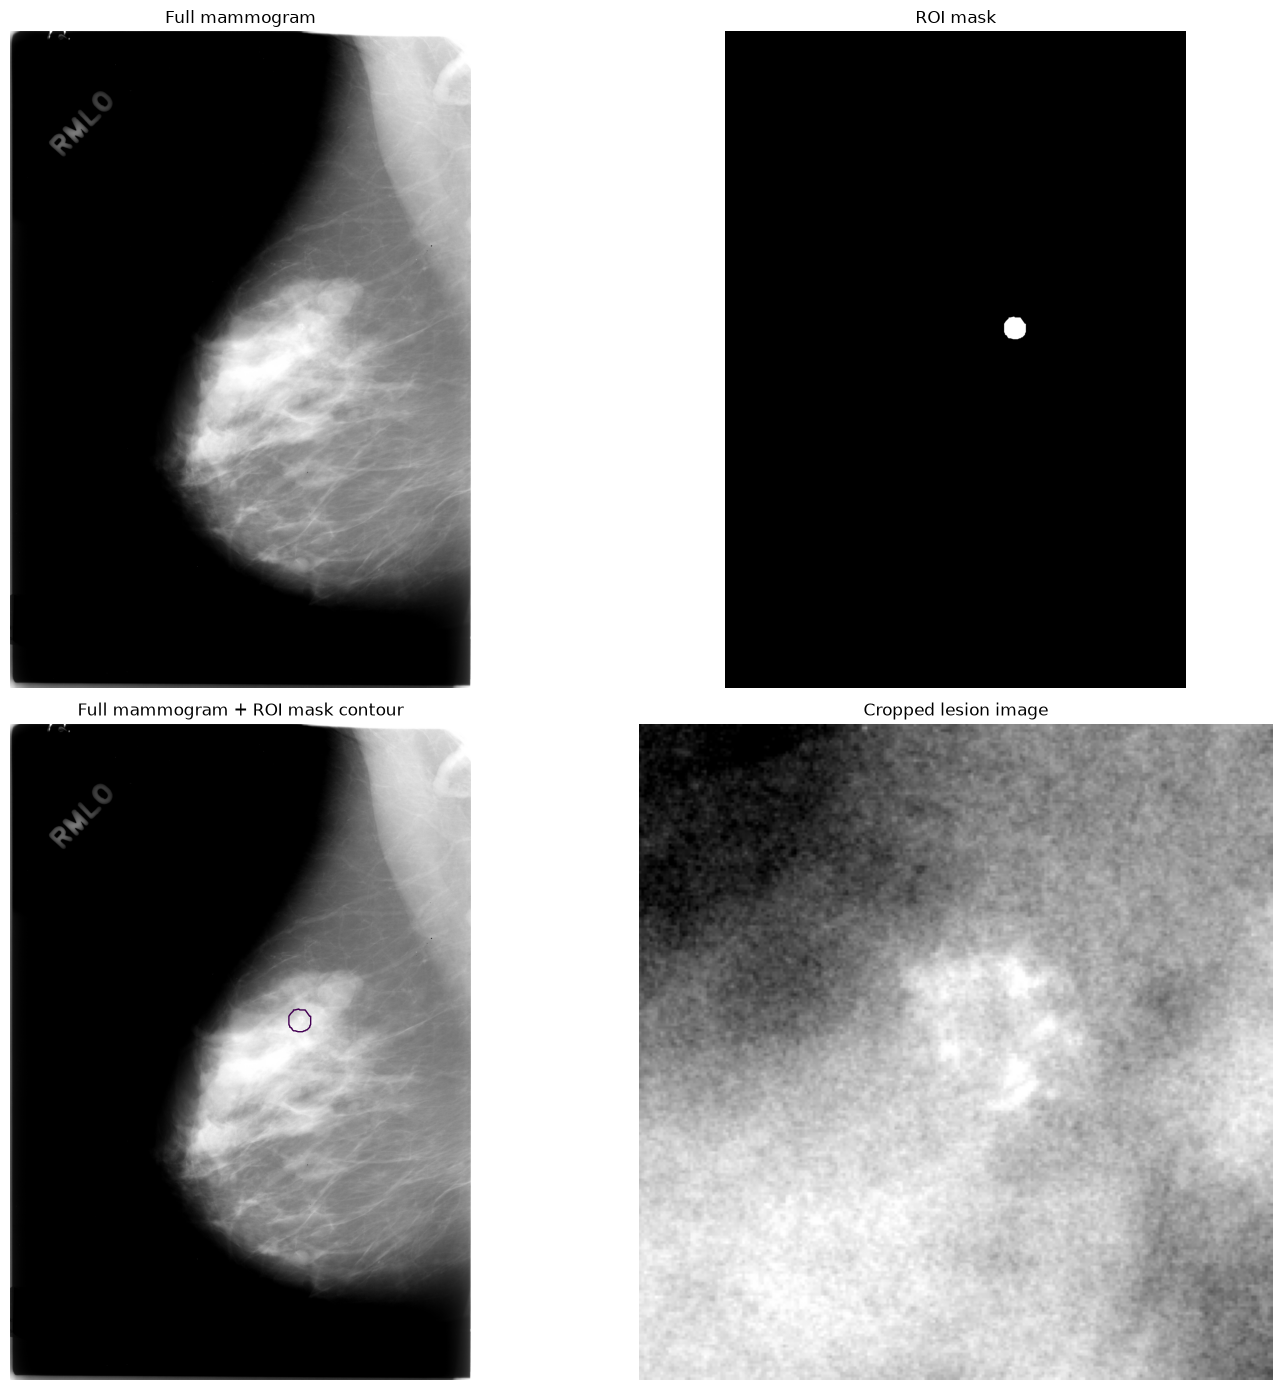

In [64]:
# Hiển thị full image, ROI mask và overlay

import matplotlib.pyplot as plt
import numpy as np

full_img = pixel_arrays["full_image"]
crop_img = pixel_arrays["crop"]
mask_img = pixel_arrays["roi_mask_candidate"]

# Mask nhị phân
mask_binary = mask_img > 0

# Giới hạn tương phản ảnh full và crop để dễ quan sát
full_vmin, full_vmax = np.percentile(full_img, [1, 99.5])
crop_vmin, crop_vmax = np.percentile(crop_img, [1, 99.5])

fig, axes = plt.subplots(2, 2, figsize=(16, 14))

# 1. Full image
axes[0, 0].imshow(
    full_img,
    cmap="gray",
    vmin=full_vmin,
    vmax=full_vmax
)
axes[0, 0].set_title("Full mammogram")
axes[0, 0].axis("off")

# 2. ROI mask
axes[0, 1].imshow(mask_binary, cmap="gray")
axes[0, 1].set_title("ROI mask")
axes[0, 1].axis("off")

# 3. Overlay mask contour on full image
axes[1, 0].imshow(
    full_img,
    cmap="gray",
    vmin=full_vmin,
    vmax=full_vmax
)

axes[1, 0].contour(
    mask_binary.astype(np.uint8),
    levels=[0.5],
    linewidths=1
)

axes[1, 0].set_title("Full mammogram + ROI mask contour")
axes[1, 0].axis("off")

# 4. Cropped image
axes[1, 1].imshow(
    crop_img,
    cmap="gray",
    vmin=crop_vmin,
    vmax=crop_vmax
)
axes[1, 1].set_title("Cropped lesion image")
axes[1, 1].axis("off")

plt.tight_layout()
plt.show()

### Kết luận kiểm chứng ca mẫu

1. **Full image** và **ROI mask** có cùng kích thước **5816 × 4088**.
2. **ROI mask** là ảnh nhị phân `{0, 255}`.
3. Vùng mask xác định được **Bounding Box**:
   - `x_min` = 2472
   - `y_min` = 2528
   - `x_max` = 2664
   - `y_max` = 2728
4. Khi chồng mask lên full image, vùng được đánh dấu khớp với vị trí tổn thương quan sát được.
5. **Crop** là ảnh riêng có kích thước **241 × 233**, không cần dùng crop để suy ra tọa độ trên ảnh toàn phần trong trường hợp này.

Ta có cơ sở thực nghiệm để xây dựng bounding-box ground truth từ ROI mask, thay vì chỉ sử dụng ảnh crop để phân loại.

In [65]:
# Chọn ca calcification thứ hai

required_path_cols = [
    "image file path",
    "cropped image file path",
    "ROI mask file path"
]

calc_candidates = calc_test_df[
    (calc_test_df["patient_id"].astype(str) != "P_01152")
    & calc_test_df[required_path_cols].notna().all(axis=1)
].copy()

# Ưu tiên ca có đủ thông tin định danh
calc_candidates = calc_candidates.sort_values(
    ["patient_id", "left or right breast", "image view", "abnormality id"]
)

print("Số ca ứng viên:", len(calc_candidates))

display(
    calc_candidates[
        [
            "patient_id",
            "left or right breast",
            "image view",
            "abnormality id",
            "abnormality type",
            "pathology"
        ]
    ].head(10)
)

Số ca ứng viên: 324


,patient_id,left or right breast,image view,abnormality id,abnormality type,pathology
0,P_00038,LEFT,CC,1,calcification,BENIGN
1,P_00038,LEFT,MLO,1,calcification,BENIGN
2,P_00038,RIGHT,CC,1,calcification,BENIGN_WITHOUT_CALLBACK
3,P_00038,RIGHT,CC,2,calcification,BENIGN_WITHOUT_CALLBACK
4,P_00038,RIGHT,MLO,1,calcification,BENIGN_WITHOUT_CALLBACK
5,P_00038,RIGHT,MLO,2,calcification,BENIGN_WITHOUT_CALLBACK
6,P_00041,LEFT,CC,2,calcification,BENIGN_WITHOUT_CALLBACK
7,P_00041,LEFT,MLO,2,calcification,BENIGN_WITHOUT_CALLBACK
8,P_00077,LEFT,CC,1,calcification,BENIGN_WITHOUT_CALLBACK
9,P_00077,LEFT,MLO,1,calcification,BENIGN_WITHOUT_CALLBACK


*Chọn ca P_00038 — LEFT — CC — Abnormality 1 làm ca calcification thứ hai*

Lý do:
- Khác bệnh nhân P_01152.
- Có đủ ba đường dẫn ảnh.
- Là ca calcification, pathology BENIGN.
- Có thể dùng để kiểm tra quy trình trên một bệnh nhân khác.

In [67]:
# Trích xuất thông tin ca P_00038

sample2_patient = "P_00038"
sample2_breast = "LEFT"
sample2_view = "CC"
sample2_abnormality = 1

sample2_csv = calc_test_df[
    (calc_test_df["patient_id"].astype(str).str.strip() == sample2_patient)
    & (
        calc_test_df["left or right breast"]
        .astype(str).str.strip().str.upper() == sample2_breast
    )
    & (
        calc_test_df["image view"]
        .astype(str).str.strip().str.upper() == sample2_view
    )
    & (
        pd.to_numeric(
            calc_test_df["abnormality id"], errors="coerce"
        ) == sample2_abnormality
    )
].copy()

if len(sample2_csv) != 1:
    print("Số dòng tìm được:", len(sample2_csv))
    display(sample2_csv)
    raise ValueError("Ca mẫu thứ hai chưa được xác định duy nhất.")

display(sample2_csv.T)

,0
patient_id,P_00038
breast density,2
left or right breast,LEFT
image view,CC
abnormality id,1
abnormality type,calcification
calc type,PUNCTATE-PLEOMORPHIC
calc distribution,CLUSTERED
assessment,4
pathology,BENIGN


In [ ]:
# Kiểm tra đường dẫn crop và ROI

for column in ["image file path", "cropped image file path", "ROI mask file path"]:
    raw_path = sample2_row[column]
    normalized_path = str(raw_path).replace("\\", "/").strip()
    case_folder = normalized_path.split("/")[0]

    print(f"\n{'=' * 70}")
    print("COLUMN:", column)
    print("RAW VALUE:", repr(raw_path))
    print("NORMALIZED:", repr(normalized_path))
    print("CASE FOLDER:", repr(case_folder))

    same_type = csv_path_index[
        csv_path_index["path_type"].astype(str).str.strip() == column
    ].copy()

    print("Số dòng cùng path_type:", len(same_type))

    # Tìm theo tên thư mục ca bệnh, không yêu cầu khớp toàn bộ đường dẫn
    folder_matches = same_type[
        same_type["case_folder"].astype(str).str.strip() == case_folder
    ]

    print("Số dòng cùng case_folder:", len(folder_matches))

    if not folder_matches.empty:
        display(
            folder_matches[
                ["path_type", "csv_path", "case_folder",
                 "study_uid", "series_uid", "alias_filename"]
            ]
        )
    else:
        print("Không tìm thấy case_folder tương ứng.")
        display(
            same_type[
                same_type["case_folder"].astype(str).str.contains(
                    "P_00038_LEFT_CC", case=False, na=False
                )
            ][
                ["path_type", "csv_path", "case_folder",
                 "study_uid", "series_uid", "alias_filename"]
            ].head(10)
        )


COLUMN: image file path
RAW VALUE: 'Calc-Test_P_00038_LEFT_CC/1.3.6.1.4.1.9590.100.1.2.85935434310203356712688695661986996009/1.3.6.1.4.1.9590.100.1.2.374115997511889073021386151921807063992/000000.dcm'
NORMALIZED: 'Calc-Test_P_00038_LEFT_CC/1.3.6.1.4.1.9590.100.1.2.85935434310203356712688695661986996009/1.3.6.1.4.1.9590.100.1.2.374115997511889073021386151921807063992/000000.dcm'
CASE FOLDER: 'Calc-Test_P_00038_LEFT_CC'
Số dòng cùng path_type: 3568
Số dòng cùng case_folder: 1


,path_type,csv_path,case_folder,study_uid,series_uid,alias_filename
0,image file path,Calc-Test_P_00038_LEFT_CC/1.3.6.1.4.1.9590.100...,Calc-Test_P_00038_LEFT_CC,1.3.6.1.4.1.9590.100.1.2.859354343102033567126...,1.3.6.1.4.1.9590.100.1.2.374115997511889073021...,000000.dcm



COLUMN: cropped image file path
RAW VALUE: 'Calc-Test_P_00038_LEFT_CC_1/1.3.6.1.4.1.9590.100.1.2.161465562211359959230647609981488894942/1.3.6.1.4.1.9590.100.1.2.419081637812053404913157930753972718515/000001.dcm\n'
NORMALIZED: 'Calc-Test_P_00038_LEFT_CC_1/1.3.6.1.4.1.9590.100.1.2.161465562211359959230647609981488894942/1.3.6.1.4.1.9590.100.1.2.419081637812053404913157930753972718515/000001.dcm'
CASE FOLDER: 'Calc-Test_P_00038_LEFT_CC_1'
Số dòng cùng path_type: 3568
Số dòng cùng case_folder: 1


,path_type,csv_path,case_folder,study_uid,series_uid,alias_filename
326,cropped image file path,Calc-Test_P_00038_LEFT_CC_1/1.3.6.1.4.1.9590.1...,Calc-Test_P_00038_LEFT_CC_1,1.3.6.1.4.1.9590.100.1.2.161465562211359959230...,1.3.6.1.4.1.9590.100.1.2.419081637812053404913...,000001.dcm\n



COLUMN: ROI mask file path
RAW VALUE: 'Calc-Test_P_00038_LEFT_CC_1/1.3.6.1.4.1.9590.100.1.2.161465562211359959230647609981488894942/1.3.6.1.4.1.9590.100.1.2.419081637812053404913157930753972718515/000000.dcm'
NORMALIZED: 'Calc-Test_P_00038_LEFT_CC_1/1.3.6.1.4.1.9590.100.1.2.161465562211359959230647609981488894942/1.3.6.1.4.1.9590.100.1.2.419081637812053404913157930753972718515/000000.dcm'
CASE FOLDER: 'Calc-Test_P_00038_LEFT_CC_1'
Số dòng cùng path_type: 3568
Số dòng cùng case_folder: 1


,path_type,csv_path,case_folder,study_uid,series_uid,alias_filename
652,ROI mask file path,Calc-Test_P_00038_LEFT_CC_1/1.3.6.1.4.1.9590.1...,Calc-Test_P_00038_LEFT_CC_1,1.3.6.1.4.1.9590.100.1.2.161465562211359959230...,1.3.6.1.4.1.9590.100.1.2.419081637812053404913...,000000.dcm


In [70]:
# Truy xuất DICOM của ca thứ hai

sample2_link_results = {}

for role, column in {
    "full_image": "image file path",
    "crop": "cropped image file path",
    "roi_mask": "ROI mask file path"
}.items():

    csv_path = str(sample2_row[column]).replace("\\", "/").strip()

    same_type = csv_path_index[
        csv_path_index["path_type"].astype(str).str.strip() == column
    ].copy()

    same_type["normalized_csv_path"] = (
        same_type["csv_path"]
        .astype(str)
        .str.replace("\\", "/", regex=False)
        .str.strip()
    )

    matched_path = same_type[
        same_type["normalized_csv_path"] == csv_path
    ]

    if len(matched_path) != 1:
        raise ValueError(
            f"{role}: tìm thấy {len(matched_path)} dòng sau chuẩn hóa."
        )

    path_info = matched_path.iloc[0]

    uid_matches = dicom_index[
        (dicom_index["StudyInstanceUID"].astype(str) == str(path_info["study_uid"]))
        & (dicom_index["SeriesInstanceUID"].astype(str) == str(path_info["series_uid"]))
    ].copy()

    if uid_matches.empty:
        raise ValueError(f"{role}: không tìm thấy DICOM theo UID.")

    sample2_link_results[role] = {
        "csv_path": csv_path,
        "study_uid": path_info["study_uid"],
        "series_uid": path_info["series_uid"],
        "candidates": uid_matches
    }

    print(f"\n[{role}]")
    print("Số DICOM cùng Study/Series UID:", len(uid_matches))
    display(
        uid_matches[
            ["relative_path", "SOPInstanceUID", "SeriesDescription"]
        ]
    )


[full_image]
Số DICOM cùng Study/Series UID: 1


,relative_path,SOPInstanceUID,SeriesDescription
9693,P_00038_LEFT_CC.dcm\1-63992\9a3af421-bb04-461c...,1.3.6.1.4.1.9590.100.1.2.289923739312470966435...,



[crop]
Số DICOM cùng Study/Series UID: 2


,relative_path,SOPInstanceUID,SeriesDescription
9694,P_00038_LEFT_CC_1.dcm\2017-08-29-94942\1-cropp...,1.3.6.1.4.1.9590.100.1.2.240727997110773773805...,cropped images
9695,P_00038_LEFT_CC_1.dcm\2017-08-29-94942\1-cropp...,1.3.6.1.4.1.9590.100.1.2.183350675911017397426...,



[roi_mask]
Số DICOM cùng Study/Series UID: 2


,relative_path,SOPInstanceUID,SeriesDescription
9694,P_00038_LEFT_CC_1.dcm\2017-08-29-94942\1-cropp...,1.3.6.1.4.1.9590.100.1.2.240727997110773773805...,cropped images
9695,P_00038_LEFT_CC_1.dcm\2017-08-29-94942\1-cropp...,1.3.6.1.4.1.9590.100.1.2.183350675911017397426...,


Ca thứ hai đã nối UID thành công cả 3 vai trò:
- full_image: 1 DICOM.
- crop: 2 DICOM cùng Study/Series.
- roi_mask: cũng chính 2 DICOM đó.

- crop: SOP Instance UID kết thúc bằng phần được hiển thị ở dòng 9694

có SeriesDescription = cropped images.

- Mask: DICOM còn lại ở dòng 9695, SeriesDescription để trống.

In [71]:
# Xác định và đọc đúng ba DICOM

# 1. Full image: chỉ có một DICOM
full2_candidates = sample2_link_results["full_image"]["candidates"]

if len(full2_candidates) != 1:
    raise ValueError("Full image không có đúng một DICOM.")

full2_dicom = full2_candidates.iloc[0]

# 2. Crop: dựa vào SeriesDescription
crop2_candidates = sample2_link_results["crop"]["candidates"]

crop2_candidates = crop2_candidates[
    crop2_candidates["SeriesDescription"]
    .astype(str).str.strip().str.lower() == "cropped images"
]

if len(crop2_candidates) != 1:
    raise ValueError("Không xác định duy nhất được crop DICOM.")

crop2_dicom = crop2_candidates.iloc[0]

# 3. Mask: DICOM còn lại trong cùng Study/Series
roi2_candidates = sample2_link_results["roi_mask"]["candidates"]

mask2_candidates = roi2_candidates[
    roi2_candidates["SOPInstanceUID"].astype(str)
    != str(crop2_dicom["SOPInstanceUID"])
]

if len(mask2_candidates) != 1:
    raise ValueError("Không xác định duy nhất được mask DICOM.")

mask2_dicom = mask2_candidates.iloc[0]

# 4. Hiển thị ba DICOM đã chọn
sample2_dicom_paths = pd.DataFrame([
    {
        "role": "full_image",
        "relative_path": full2_dicom["relative_path"],
        "SOPInstanceUID": full2_dicom["SOPInstanceUID"]
    },
    {
        "role": "crop",
        "relative_path": crop2_dicom["relative_path"],
        "SOPInstanceUID": crop2_dicom["SOPInstanceUID"]
    },
    {
        "role": "roi_mask",
        "relative_path": mask2_dicom["relative_path"],
        "SOPInstanceUID": mask2_dicom["SOPInstanceUID"]
    }
])

display(sample2_dicom_paths)

# 5. Đọc pixel data
sample2_dicom_objects = {
    "full_image": pydicom.dcmread(full2_dicom["file_path"]),
    "crop": pydicom.dcmread(crop2_dicom["file_path"]),
    "roi_mask": pydicom.dcmread(mask2_dicom["file_path"])
}

sample2_pixel_arrays = {
    role: ds.pixel_array
    for role, ds in sample2_dicom_objects.items()
}

# 6. Kiểm tra thông tin pixel
sample2_pixel_inspection = []

for role, ds in sample2_dicom_objects.items():
    arr = sample2_pixel_arrays[role]
    values, counts = np.unique(arr, return_counts=True)

    sample2_pixel_inspection.append({
        "role": role,
        "shape": arr.shape,
        "dtype": str(arr.dtype),
        "BitsAllocated": getattr(ds, "BitsAllocated", None),
        "PhotometricInterpretation": getattr(
            ds, "PhotometricInterpretation", None
        ),
        "unique_value_count": len(values),
        "unique_values_preview": values[:10].tolist(),
        "zero_ratio": float(np.mean(arr == 0)),
        "nonzero_pixel_count": int(np.count_nonzero(arr))
    })

sample2_pixel_inspection_df = pd.DataFrame(sample2_pixel_inspection)

display(sample2_pixel_inspection_df)

,role,relative_path,SOPInstanceUID
0,full_image,P_00038_LEFT_CC.dcm\1-63992\9a3af421-bb04-461c...,1.3.6.1.4.1.9590.100.1.2.289923739312470966435...
1,crop,P_00038_LEFT_CC_1.dcm\2017-08-29-94942\1-cropp...,1.3.6.1.4.1.9590.100.1.2.240727997110773773805...
2,roi_mask,P_00038_LEFT_CC_1.dcm\2017-08-29-94942\1-cropp...,1.3.6.1.4.1.9590.100.1.2.183350675911017397426...


,role,shape,dtype,BitsAllocated,PhotometricInterpretation,unique_value_count,unique_values_preview,zero_ratio,nonzero_pixel_count
0,full_image,"(4616, 3016)",uint16,16,MONOCHROME2,2456,"[0, 22, 44, 66, 88, 110, 132, 154, 177, 199]",0.689229,4326512
1,crop,"(249, 265)",uint16,16,MONOCHROME2,560,"[37455, 37796, 37966, 38008, 38051, 38094, 381...",0.000000,65985
2,roi_mask,"(4616, 3016)",uint8,8,MONOCHROME2,2,"[0, 255]",0.997258,38177


### Kiểm tra Full image và ROI mask

| Tiêu chí | Full image | ROI mask |
| :--- | :---: | :---: |
| **Kích thước** | 4616 × 3016 | 4616 × 3016 |
| **Kiểu dữ liệu** | `uint16` | `uint8` |
| **Số giá trị pixel** | 2.456 | 2 |
| **Giá trị mask** | — | 0 và 255 |
| **Pixel khác 0** | 4.326.512 | 38.177 |

#### Nhận xét:
1. **Mask** có cùng kích thước với ảnh X-quang gốc — điều kiện cần để tọa độ mask tương ứng trực tiếp với tọa độ ảnh gốc.
2. **Mask** chỉ có hai giá trị `0` và `255`, phù hợp với biểu diễn nhị phân.
3. **Mask** có **38.177** pixel khác 0, tức vùng ROI không rỗng.
4. **Crop** có kích thước **249 × 265**, nhỏ hơn ảnh gốc, phù hợp với vai trò ảnh cắt vùng tổn thương.

Mask bounding box (x_min, y_min, x_max, y_max):
(288, 1976, 512, 2184)
Mask width: 225
Mask height: 209


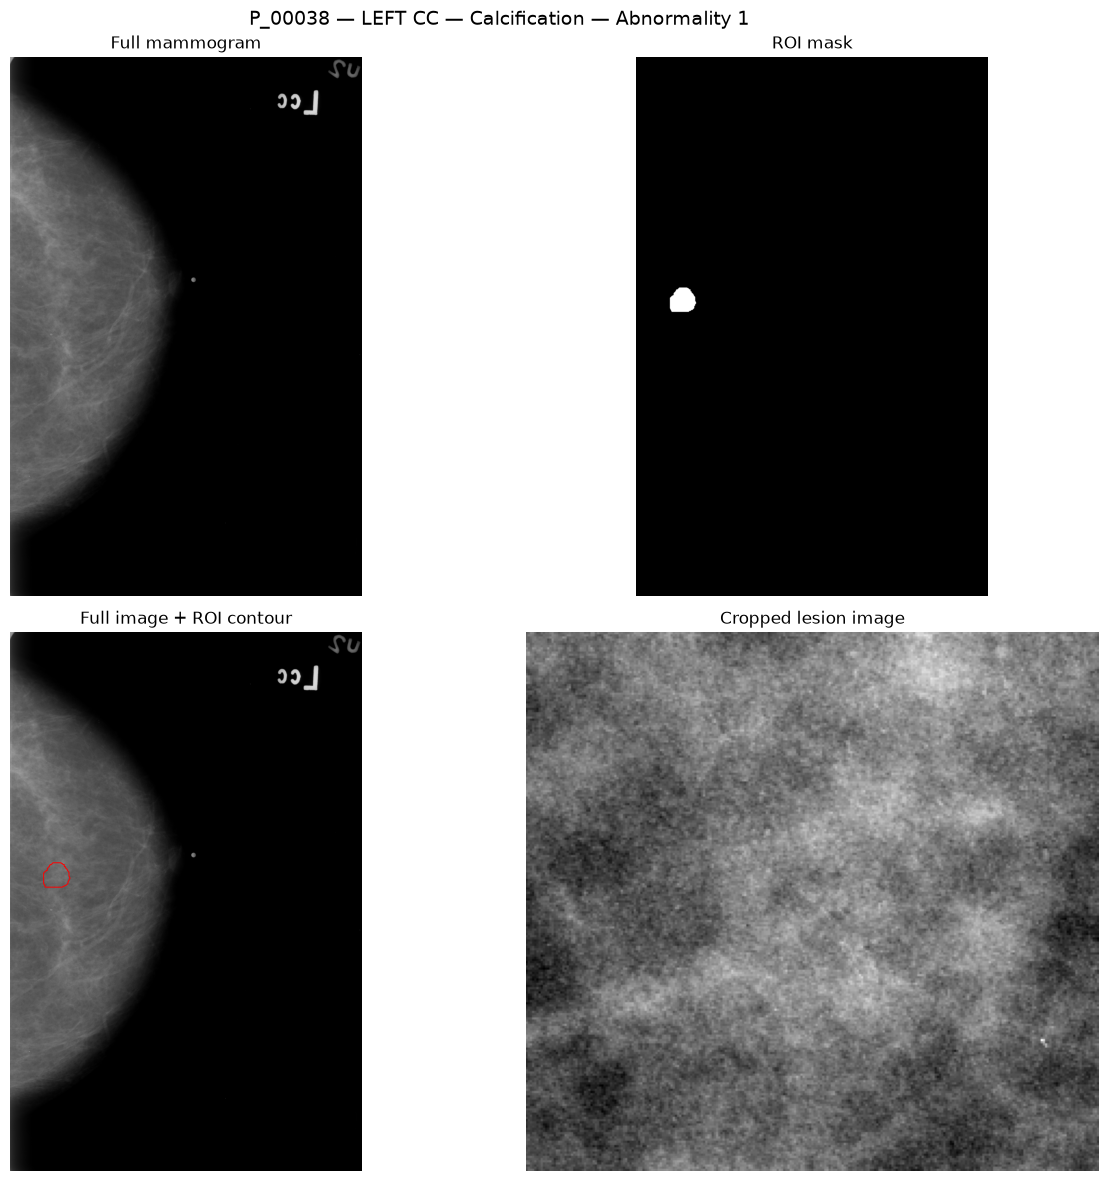

In [73]:
# NOTEBOOK 02 — STEP 9K: VISUAL VALIDATION (2x2 LAYOUT)

import matplotlib.pyplot as plt
import numpy as np

full2 = sample2_pixel_arrays["full_image"]
mask2 = sample2_pixel_arrays["roi_mask"]
crop2 = sample2_pixel_arrays["crop"]

# Xác định bounding box của mask
ys, xs = np.where(mask2 > 0)

if len(xs) == 0:
    raise ValueError("ROI mask rỗng.")

y_min, y_max = int(ys.min()), int(ys.max())
x_min, x_max = int(xs.min()), int(xs.max())

print("Mask bounding box (x_min, y_min, x_max, y_max):")
print((x_min, y_min, x_max, y_max))

print("Mask width:", x_max - x_min + 1)
print("Mask height:", y_max - y_min + 1)

# Hiển thị 4 ảnh theo bố cục 2 hàng x 2 cột
fig, axes = plt.subplots(2, 2, figsize=(14, 12))

axes[0, 0].imshow(full2, cmap="gray")
axes[0, 0].set_title("Full mammogram")
axes[0, 0].axis("off")

axes[0, 1].imshow(mask2, cmap="gray")
axes[0, 1].set_title("ROI mask")
axes[0, 1].axis("off")

axes[1, 0].imshow(full2, cmap="gray")
axes[1, 0].contour(
    mask2 > 0,
    levels=[0.5],
    colors="red",
    linewidths=0.7
)
axes[1, 0].set_title("Full image + ROI contour")
axes[1, 0].axis("off")

axes[1, 1].imshow(crop2, cmap="gray")
axes[1, 1].set_title("Cropped lesion image")
axes[1, 1].axis("off")

fig.suptitle(
    "P_00038 — LEFT CC — Calcification — Abnormality 1",
    fontsize=14
)

plt.tight_layout()
plt.show()

In [74]:
# SELECT MASS VALIDATION CANDIDATES

required_path_cols = [
    "image file path",
    "cropped image file path",
    "ROI mask file path"
]

mass_candidates = mass_test_df[
    (mass_test_df["patient_id"].astype(str) != "P_01152")
    & (mass_test_df[required_path_cols].notna().all(axis=1))
].copy()

mass_candidates = mass_candidates.sort_values(
    ["patient_id", "left or right breast", "image view", "abnormality id"]
)

print("Số ca mass ứng viên:", len(mass_candidates))

display(
    mass_candidates[
        [
            "patient_id",
            "left or right breast",
            "image view",
            "abnormality id",
            "abnormality type",
            "pathology"
        ]
    ].head(10)
)

Số ca mass ứng viên: 378


,patient_id,left or right breast,image view,abnormality id,abnormality type,pathology
0,P_00016,LEFT,CC,1,mass,MALIGNANT
1,P_00016,LEFT,MLO,1,mass,MALIGNANT
2,P_00017,LEFT,CC,1,mass,MALIGNANT
3,P_00017,LEFT,MLO,1,mass,MALIGNANT
4,P_00032,RIGHT,CC,1,mass,BENIGN
5,P_00032,RIGHT,MLO,1,mass,BENIGN
6,P_00037,RIGHT,CC,1,mass,MALIGNANT
7,P_00037,RIGHT,MLO,1,mass,MALIGNANT
8,P_00056,LEFT,MLO,1,mass,BENIGN
9,P_00066,LEFT,CC,1,mass,MALIGNANT


*Chọn P_00016 – LEFT CC – Abnormality 1 – MALIGNANT làm ca kiểm chứng thứ ba*

- Lý do: đây là ca đầu tiên trong danh sách, có đủ full image, crop và ROI mask; đồng thời giúp kiểm tra thêm trường hợp mass ác tính, bổ sung cho hai ca calcification trước đó.

In [75]:
# Truy xuất ca mass P_00016

sample3_patient = "P_00016"
sample3_breast = "LEFT"
sample3_view = "CC"
sample3_abnormality = 1

sample3_csv = mass_test_df[
    (mass_test_df["patient_id"].astype(str).str.strip() == sample3_patient)
    & (
        mass_test_df["left or right breast"]
        .astype(str).str.strip().str.upper() == sample3_breast
    )
    & (
        mass_test_df["image view"]
        .astype(str).str.strip().str.upper() == sample3_view
    )
    & (
        pd.to_numeric(
            mass_test_df["abnormality id"],
            errors="coerce"
        ) == sample3_abnormality
    )
].copy()

if len(sample3_csv) != 1:
    print("Số dòng tìm được:", len(sample3_csv))
    display(sample3_csv)
    raise ValueError("Ca mass chưa được xác định duy nhất.")

display(sample3_csv.T)

,0
patient_id,P_00016
breast_density,4
left or right breast,LEFT
image view,CC
abnormality id,1
abnormality type,mass
mass shape,IRREGULAR
mass margins,SPICULATED
assessment,5
pathology,MALIGNANT


In [76]:
# Liên kết ba DICOM theo UID

sample3_row = sample3_csv.iloc[0]

sample3_link_results = {}

for role, column in {
    "full_image": "image file path",
    "crop": "cropped image file path",
    "roi_mask": "ROI mask file path"
}.items():

    csv_path = str(sample3_row[column]).replace("\\", "/").strip()

    same_type = csv_path_index[
        csv_path_index["path_type"].astype(str).str.strip() == column
    ].copy()

    same_type["normalized_csv_path"] = (
        same_type["csv_path"]
        .astype(str)
        .str.replace("\\", "/", regex=False)
        .str.strip()
    )

    matched_path = same_type[
        same_type["normalized_csv_path"] == csv_path
    ]

    if len(matched_path) != 1:
        raise ValueError(
            f"{role}: tìm thấy {len(matched_path)} dòng sau chuẩn hóa."
        )

    path_info = matched_path.iloc[0]

    uid_matches = dicom_index[
        (dicom_index["StudyInstanceUID"].astype(str) == str(path_info["study_uid"]))
        & (dicom_index["SeriesInstanceUID"].astype(str) == str(path_info["series_uid"]))
    ].copy()

    if uid_matches.empty:
        raise ValueError(f"{role}: không tìm thấy DICOM theo UID.")

    sample3_link_results[role] = {
        "csv_path": csv_path,
        "study_uid": path_info["study_uid"],
        "series_uid": path_info["series_uid"],
        "candidates": uid_matches
    }

    print(f"\n[{role}]")
    print("Số DICOM cùng Study/Series UID:", len(uid_matches))

    display(
        uid_matches[
            ["relative_path", "SOPInstanceUID", "SeriesDescription"]
        ]
    )


[full_image]
Số DICOM cùng Study/Series UID: 1


,relative_path,SOPInstanceUID,SeriesDescription
4709,Mass-Test_P_00016_LEFT_CC\2016-10-04-30104\1-f...,1.3.6.1.4.1.9590.100.1.2.255536750111234655207...,full mammogram images



[crop]
Số DICOM cùng Study/Series UID: 2


,relative_path,SOPInstanceUID,SeriesDescription
4710,Mass-Test_P_00016_LEFT_CC_1\2016-10-04-09887\1...,1.3.6.1.4.1.9590.100.1.2.223320881412566496537...,ROI mask images
4711,Mass-Test_P_00016_LEFT_CC_1\2016-10-04-09887\1...,1.3.6.1.4.1.9590.100.1.2.256314007412155566139...,cropped images



[roi_mask]
Số DICOM cùng Study/Series UID: 2


,relative_path,SOPInstanceUID,SeriesDescription
4710,Mass-Test_P_00016_LEFT_CC_1\2016-10-04-09887\1...,1.3.6.1.4.1.9590.100.1.2.223320881412566496537...,ROI mask images
4711,Mass-Test_P_00016_LEFT_CC_1\2016-10-04-09887\1...,1.3.6.1.4.1.9590.100.1.2.256314007412155566139...,cropped images


Ca mass này còn thuận lợi hơn hai ca trước vì SeriesDescription đã phân biệt rõ cả hai 

*vai trò:*
- full_image: 1 DICOM, mô tả full mammogram images.
- roi_mask: 1 DICOM, mô tả ROI mask images.
- crop: 1 DICOM, mô tả cropped images.

In [78]:
# Chọn và đọc ba DICOM của ca mass

# 1. Full image
full3_candidates = sample3_link_results["full_image"]["candidates"]

if len(full3_candidates) != 1:
    raise ValueError("Full image không có đúng một DICOM.")

full3_dicom = full3_candidates.iloc[0]

# 2. Crop
crop3_candidates = sample3_link_results["crop"]["candidates"]

crop3_candidates = crop3_candidates[
    crop3_candidates["SeriesDescription"]
    .astype(str).str.strip().str.lower() == "cropped images"
]

if len(crop3_candidates) != 1:
    raise ValueError("Không xác định duy nhất được crop DICOM.")

crop3_dicom = crop3_candidates.iloc[0]

# 3. ROI mask
mask3_candidates = sample3_link_results["roi_mask"]["candidates"]

mask3_candidates = mask3_candidates[
    mask3_candidates["SeriesDescription"]
    .astype(str).str.strip().str.lower() == "roi mask images"
]

if len(mask3_candidates) != 1:
    raise ValueError("Không xác định duy nhất được mask DICOM.")

mask3_dicom = mask3_candidates.iloc[0]

# 4. Hiển thị ba DICOM đã chọn
sample3_dicom_paths = pd.DataFrame([
    {
        "role": "full_image",
        "relative_path": full3_dicom["relative_path"],
        "SOPInstanceUID": full3_dicom["SOPInstanceUID"]
    },
    {
        "role": "crop",
        "relative_path": crop3_dicom["relative_path"],
        "SOPInstanceUID": crop3_dicom["SOPInstanceUID"]
    },
    {
        "role": "roi_mask",
        "relative_path": mask3_dicom["relative_path"],
        "SOPInstanceUID": mask3_dicom["SOPInstanceUID"]
    }
])

display(sample3_dicom_paths)

# 5. Đọc DICOM
sample3_dicom_objects = {
    "full_image": pydicom.dcmread(full3_dicom["file_path"]),
    "crop": pydicom.dcmread(crop3_dicom["file_path"]),
    "roi_mask": pydicom.dcmread(mask3_dicom["file_path"])
}

sample3_pixel_arrays = {
    role: ds.pixel_array
    for role, ds in sample3_dicom_objects.items()
}

# 6. Kiểm tra pixel
sample3_pixel_inspection = []

for role, ds in sample3_dicom_objects.items():
    arr = sample3_pixel_arrays[role]
    values = np.unique(arr)

    sample3_pixel_inspection.append({
        "role": role,
        "shape": arr.shape,
        "dtype": str(arr.dtype),
        "BitsAllocated": getattr(ds, "BitsAllocated", None),
        "PhotometricInterpretation": getattr(
            ds, "PhotometricInterpretation", None
        ),
        "unique_value_count": len(values),
        "unique_values_preview": values[:10].tolist(),
        "zero_ratio": float(np.mean(arr == 0)),
        "nonzero_pixel_count": int(np.count_nonzero(arr))
    })

sample3_pixel_inspection_df = pd.DataFrame(sample3_pixel_inspection)

display(sample3_pixel_inspection_df)

,role,relative_path,SOPInstanceUID
0,full_image,Mass-Test_P_00016_LEFT_CC\2016-10-04-30104\1-f...,1.3.6.1.4.1.9590.100.1.2.255536750111234655207...
1,crop,Mass-Test_P_00016_LEFT_CC_1\2016-10-04-09887\1...,1.3.6.1.4.1.9590.100.1.2.256314007412155566139...
2,roi_mask,Mass-Test_P_00016_LEFT_CC_1\2016-10-04-09887\1...,1.3.6.1.4.1.9590.100.1.2.223320881412566496537...


,role,shape,dtype,BitsAllocated,PhotometricInterpretation,unique_value_count,unique_values_preview,zero_ratio,nonzero_pixel_count
0,full_image,"(4006, 1846)",uint16,16,MONOCHROME2,2968,"[0, 14, 35, 56, 77, 98, 119, 140, 161, 182]",0.698585,2228984
1,crop,"(384, 385)",uint16,16,MONOCHROME2,1478,"[21187, 21241, 21350, 21514, 21785, 21812, 220...",0.000000,147840
2,roi_mask,"(4006, 1846)",uint8,8,MONOCHROME2,2,"[0, 255]",0.989913,74597


Sample 3 — P_00016_LEFT_CC, Mass, Abnormality 1 — có các dấu hiệu dữ liệu rất tốt:
- Full mammogram và ROI mask cùng kích thước 4006 × 1846.
- ROI mask là ảnh nhị phân, chỉ có hai giá trị 0 và 255.
- Mask có 74.597 pixel khác 0, tức vùng tổn thương không rỗng.
- Crop nhỏ hơn, kích thước 384 × 385, phù hợp với vai trò ảnh cắt vùng tổn thương.

Patient: P_00016
Image view: LEFT CC
Lesion type: Mass
Abnormality ID: 1
Mask bounding box (x_min, y_min, x_max, y_max): (1341, 2588, 1685, 2931)
Bounding box width: 345
Bounding box height: 344


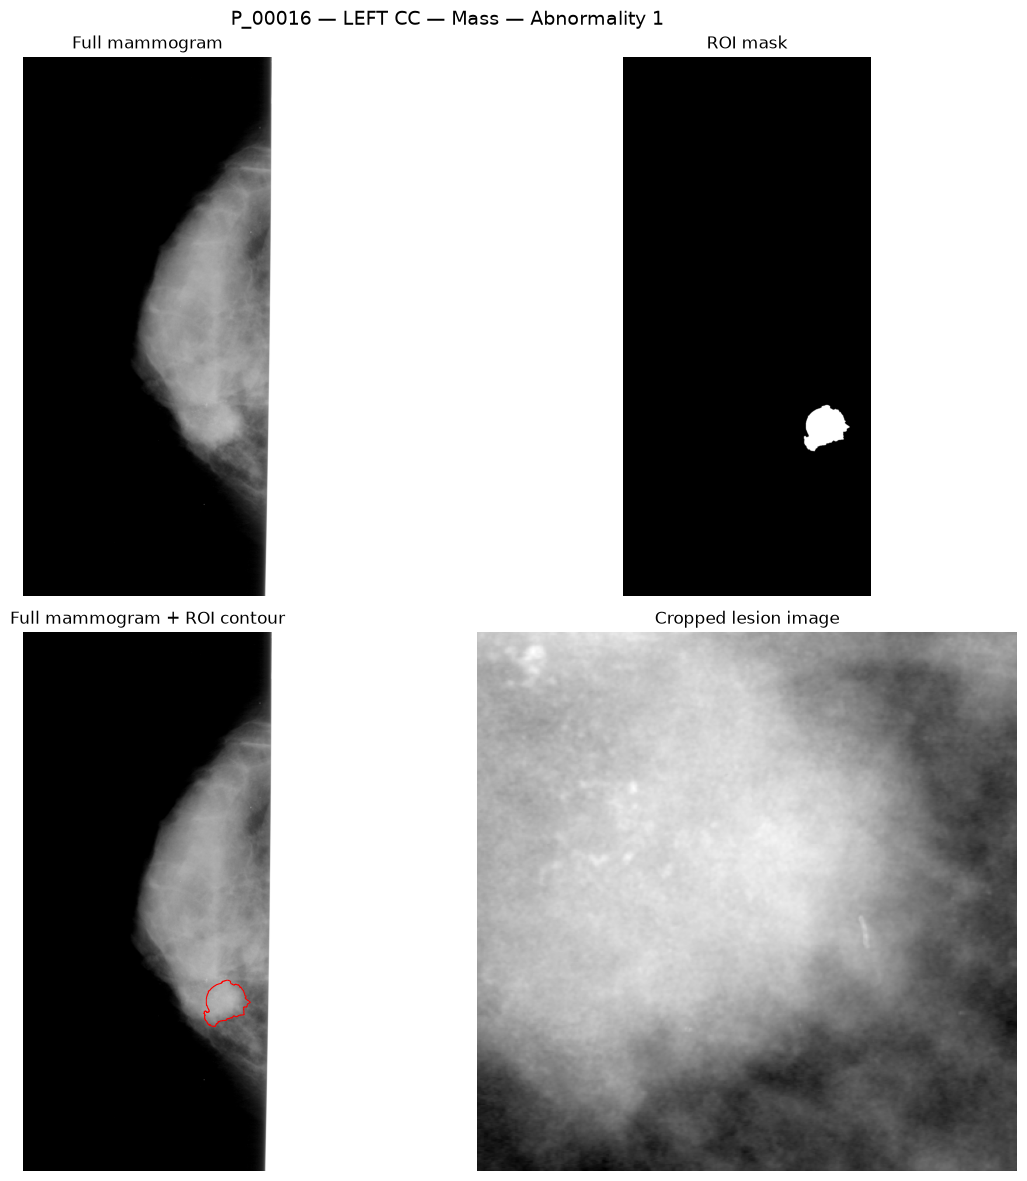

In [79]:
# Hiển thị ảnh và kiểm tra mask

import matplotlib.pyplot as plt
import numpy as np

full3 = sample3_pixel_arrays["full_image"]
mask3 = sample3_pixel_arrays["roi_mask"]
crop3 = sample3_pixel_arrays["crop"]

# 1. Tính bounding box từ ROI mask
ys, xs = np.where(mask3 > 0)

if len(xs) == 0:
    raise ValueError("ROI mask rỗng, không thể xác định bounding box.")

y_min, y_max = int(ys.min()), int(ys.max())
x_min, x_max = int(xs.min()), int(xs.max())

print("Patient: P_00016")
print("Image view: LEFT CC")
print("Lesion type: Mass")
print("Abnormality ID: 1")
print("Mask bounding box (x_min, y_min, x_max, y_max):",
      (x_min, y_min, x_max, y_max))
print("Bounding box width:", x_max - x_min + 1)
print("Bounding box height:", y_max - y_min + 1)

# 2. Hiển thị 4 hình
fig, axes = plt.subplots(2, 2, figsize=(14, 12))

axes[0, 0].imshow(full3, cmap="gray")
axes[0, 0].set_title("Full mammogram")
axes[0, 0].axis("off")

axes[0, 1].imshow(mask3, cmap="gray")
axes[0, 1].set_title("ROI mask")
axes[0, 1].axis("off")

axes[1, 0].imshow(full3, cmap="gray")
axes[1, 0].contour(
    mask3 > 0,
    levels=[0.5],
    colors="red",
    linewidths=0.7
)
axes[1, 0].set_title("Full mammogram + ROI contour")
axes[1, 0].axis("off")

axes[1, 1].imshow(crop3, cmap="gray")
axes[1, 1].set_title("Cropped lesion image")
axes[1, 1].axis("off")

fig.suptitle(
    "P_00016 — LEFT CC — Mass — Abnormality 1",
    fontsize=14
)

plt.tight_layout()
plt.show()

In [84]:
# Nạp bảng phân loại vai trò DICOM

from pathlib import Path
import pandas as pd

project_root = Path(r"C:\Breast-Cancer-CBIS-DDSM")
processed_dir = project_root / "Data" / "processed"

role_file = processed_dir / "nb02_instance_role_final.csv"

if not role_file.exists():
    raise FileNotFoundError(f"Không tìm thấy file: {role_file}")

instance_role_final = pd.read_csv(role_file)

print("Đã nạp bảng phân loại vai trò DICOM.")
print("File:", role_file)
print("Shape:", instance_role_final.shape)
print("Columns:", instance_role_final.columns.tolist())

display(instance_role_final.head(10))

Đã nạp bảng phân loại vai trò DICOM.
File: C:\Breast-Cancer-CBIS-DDSM\Data\processed\nb02_instance_role_final.csv
Shape: (10239, 16)
Columns: ['study_uid', 'series_uid', 'SOPInstanceUID', 'file_path', 'SeriesDescription', 'proposed_role', 'confidence_reason', 'review_status', 'pixel_unique_values', 'pixel_zero_ratio', 'pixel_shape', 'pixel_error', 'path_types', 'path_types_text', 'proposed_role_final', 'final_review_status']


,study_uid,series_uid,SOPInstanceUID,file_path,SeriesDescription,proposed_role,confidence_reason,review_status,pixel_unique_values,pixel_zero_ratio,pixel_shape,pixel_error,path_types,path_types_text,proposed_role_final,final_review_status
0,1.3.6.1.4.1.9590.100.1.2.859354343102033567126...,1.3.6.1.4.1.9590.100.1.2.374115997511889073021...,1.3.6.1.4.1.9590.100.1.2.289923739312470966435...,C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_d...,NaN,unverified,Chưa đủ bằng chứng,needs_review,2456.0,0.689229,"(4616, 3016)",NaN,['image file path'],['image file path'],full_image_candidate,path_context_supported
1,1.3.6.1.4.1.9590.100.1.2.384159464510350889125...,1.3.6.1.4.1.9590.100.1.2.174390361112646747718...,1.3.6.1.4.1.9590.100.1.2.265647748413262733922...,C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_d...,NaN,unverified,Chưa đủ bằng chứng,needs_review,2803.0,0.516532,"(4728, 3064)",NaN,['image file path'],['image file path'],full_image_candidate,path_context_supported
2,1.3.6.1.4.1.9590.100.1.2.177706148911820252341...,1.3.6.1.4.1.9590.100.1.2.263861248711313923336...,1.3.6.1.4.1.9590.100.1.2.170849841512906610322...,C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_d...,NaN,unverified,Chưa đủ bằng chứng,needs_review,2771.0,0.694894,"(4688, 2744)",NaN,['image file path'],['image file path'],full_image_candidate,path_context_supported
3,1.3.6.1.4.1.9590.100.1.2.328421320411501709324...,1.3.6.1.4.1.9590.100.1.2.442624602111129305133...,1.3.6.1.4.1.9590.100.1.2.157389493211595275534...,C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_d...,NaN,unverified,Chưa đủ bằng chứng,needs_review,2959.0,0.549811,"(4720, 2928)",NaN,['image file path'],['image file path'],full_image_candidate,path_context_supported
4,1.3.6.1.4.1.9590.100.1.2.696920639136398753090...,1.3.6.1.4.1.9590.100.1.2.272917492411709393015...,1.3.6.1.4.1.9590.100.1.2.356312198411853757726...,C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_d...,NaN,unverified,Chưa đủ bằng chứng,needs_review,2850.0,0.527342,"(5664, 3984)",NaN,['image file path'],['image file path'],full_image_candidate,path_context_supported
5,1.3.6.1.4.1.9590.100.1.2.142141008410911067722...,1.3.6.1.4.1.9590.100.1.2.214716350711587846302...,1.3.6.1.4.1.9590.100.1.2.170104659913848376505...,C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_d...,NaN,unverified,Chưa đủ bằng chứng,needs_review,2978.0,0.528280,"(5664, 4040)",NaN,['image file path'],['image file path'],full_image_candidate,path_context_supported
6,1.3.6.1.4.1.9590.100.1.2.171237778213286314004...,1.3.6.1.4.1.9590.100.1.2.120762895113344405411...,1.3.6.1.4.1.9590.100.1.2.359997187911651272741...,C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_d...,NaN,unverified,Chưa đủ bằng chứng,needs_review,2797.0,0.550313,"(4512, 3056)",NaN,['image file path'],['image file path'],full_image_candidate,path_context_supported
7,1.3.6.1.4.1.9590.100.1.2.183241556612565531802...,1.3.6.1.4.1.9590.100.1.2.697213209132484295098...,1.3.6.1.4.1.9590.100.1.2.644082510112116301240...,C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_d...,NaN,unverified,Chưa đủ bằng chứng,needs_review,2974.0,0.425325,"(4544, 3080)",NaN,['image file path'],['image file path'],full_image_candidate,path_context_supported
8,1.3.6.1.4.1.9590.100.1.2.151291966112198840100...,1.3.6.1.4.1.9590.100.1.2.267340905912306939309...,1.3.6.1.4.1.9590.100.1.2.255128570413023748627...,C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_d...,NaN,unverified,Chưa đủ bằng chứng,needs_review,2977.0,0.491925,"(4544, 3104)",NaN,['image file path'],['image file path'],full_image_candidate,path_context_supported
9,1.3.6.1.4.1.9590.100.1.2.365452443811764926000...,1.3.6.1.4.1.9590.100.1.2.385318920211943956428...,1.3.6.1.4.1.9590.100.1.2.145202354112146675414...,C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_d...,NaN,unverified,Chưa đủ bằng chứng,needs_review,2978.0,0.432190,"(4568, 3080)",NaN,['image file path'],['image file path'],full_image_candidate,path_context_supported


In [85]:
# Kiểm tra cấu trúc các bảng trước khi audit

tables_to_check = {
    "calc_test_df": calc_test_df,
    "calc_train_df": calc_train_df,
    "mass_test_df": mass_test_df,
    "mass_train_df": mass_train_df,
    "dicom_index": dicom_index,
    "csv_path_index": csv_path_index,
    "dicom_candidates": dicom_candidates,
    "instance_role_final": instance_role_final
}

for table_name, df in tables_to_check.items():
    print(f"\n{'=' * 75}")
    print(f"{table_name}: {df.shape[0]:,} rows × {df.shape[1]} columns")
    print(list(df.columns))

print("\n--- SAMPLE: instance_role_final ---")
display(instance_role_final.head(5))

print("\n--- SAMPLE: csv_path_index ---")
display(csv_path_index.head(5))

print("\n--- SAMPLE: dicom_index ---")
display(dicom_index.head(5))


calc_test_df: 326 rows × 14 columns
['patient_id', 'breast density', 'left or right breast', 'image view', 'abnormality id', 'abnormality type', 'calc type', 'calc distribution', 'assessment', 'pathology', 'subtlety', 'image file path', 'cropped image file path', 'ROI mask file path']

calc_train_df: 1,546 rows × 14 columns
['patient_id', 'breast density', 'left or right breast', 'image view', 'abnormality id', 'abnormality type', 'calc type', 'calc distribution', 'assessment', 'pathology', 'subtlety', 'image file path', 'cropped image file path', 'ROI mask file path']

mass_test_df: 378 rows × 14 columns
['patient_id', 'breast_density', 'left or right breast', 'image view', 'abnormality id', 'abnormality type', 'mass shape', 'mass margins', 'assessment', 'pathology', 'subtlety', 'image file path', 'cropped image file path', 'ROI mask file path']

mass_train_df: 1,318 rows × 14 columns
['patient_id', 'breast_density', 'left or right breast', 'image view', 'abnormality id', 'abnormalit

,study_uid,series_uid,SOPInstanceUID,file_path,SeriesDescription,proposed_role,confidence_reason,review_status,pixel_unique_values,pixel_zero_ratio,pixel_shape,pixel_error,path_types,path_types_text,proposed_role_final,final_review_status
0,1.3.6.1.4.1.9590.100.1.2.859354343102033567126...,1.3.6.1.4.1.9590.100.1.2.374115997511889073021...,1.3.6.1.4.1.9590.100.1.2.289923739312470966435...,C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_d...,NaN,unverified,Chưa đủ bằng chứng,needs_review,2456.0,0.689229,"(4616, 3016)",NaN,['image file path'],['image file path'],full_image_candidate,path_context_supported
1,1.3.6.1.4.1.9590.100.1.2.384159464510350889125...,1.3.6.1.4.1.9590.100.1.2.174390361112646747718...,1.3.6.1.4.1.9590.100.1.2.265647748413262733922...,C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_d...,NaN,unverified,Chưa đủ bằng chứng,needs_review,2803.0,0.516532,"(4728, 3064)",NaN,['image file path'],['image file path'],full_image_candidate,path_context_supported
2,1.3.6.1.4.1.9590.100.1.2.177706148911820252341...,1.3.6.1.4.1.9590.100.1.2.263861248711313923336...,1.3.6.1.4.1.9590.100.1.2.170849841512906610322...,C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_d...,NaN,unverified,Chưa đủ bằng chứng,needs_review,2771.0,0.694894,"(4688, 2744)",NaN,['image file path'],['image file path'],full_image_candidate,path_context_supported
3,1.3.6.1.4.1.9590.100.1.2.328421320411501709324...,1.3.6.1.4.1.9590.100.1.2.442624602111129305133...,1.3.6.1.4.1.9590.100.1.2.157389493211595275534...,C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_d...,NaN,unverified,Chưa đủ bằng chứng,needs_review,2959.0,0.549811,"(4720, 2928)",NaN,['image file path'],['image file path'],full_image_candidate,path_context_supported
4,1.3.6.1.4.1.9590.100.1.2.696920639136398753090...,1.3.6.1.4.1.9590.100.1.2.272917492411709393015...,1.3.6.1.4.1.9590.100.1.2.356312198411853757726...,C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_d...,NaN,unverified,Chưa đủ bằng chứng,needs_review,2850.0,0.527342,"(5664, 3984)",NaN,['image file path'],['image file path'],full_image_candidate,path_context_supported



--- SAMPLE: csv_path_index ---


,split,csv_row,path_type,csv_path,case_folder,study_uid,series_uid,alias_filename,path_components
0,calc_test,0,image file path,Calc-Test_P_00038_LEFT_CC/1.3.6.1.4.1.9590.100...,Calc-Test_P_00038_LEFT_CC,1.3.6.1.4.1.9590.100.1.2.859354343102033567126...,1.3.6.1.4.1.9590.100.1.2.374115997511889073021...,000000.dcm,4
1,calc_test,1,image file path,Calc-Test_P_00038_LEFT_MLO/1.3.6.1.4.1.9590.10...,Calc-Test_P_00038_LEFT_MLO,1.3.6.1.4.1.9590.100.1.2.384159464510350889125...,1.3.6.1.4.1.9590.100.1.2.174390361112646747718...,000000.dcm,4
2,calc_test,2,image file path,Calc-Test_P_00038_RIGHT_CC/1.3.6.1.4.1.9590.10...,Calc-Test_P_00038_RIGHT_CC,1.3.6.1.4.1.9590.100.1.2.177706148911820252341...,1.3.6.1.4.1.9590.100.1.2.263861248711313923336...,000000.dcm,4
3,calc_test,3,image file path,Calc-Test_P_00038_RIGHT_CC/1.3.6.1.4.1.9590.10...,Calc-Test_P_00038_RIGHT_CC,1.3.6.1.4.1.9590.100.1.2.177706148911820252341...,1.3.6.1.4.1.9590.100.1.2.263861248711313923336...,000000.dcm,4
4,calc_test,4,image file path,Calc-Test_P_00038_RIGHT_MLO/1.3.6.1.4.1.9590.1...,Calc-Test_P_00038_RIGHT_MLO,1.3.6.1.4.1.9590.100.1.2.328421320411501709324...,1.3.6.1.4.1.9590.100.1.2.442624602111129305133...,000000.dcm,4



--- SAMPLE: dicom_index ---


,file_path,relative_path,PatientID,StudyInstanceUID,SeriesInstanceUID,SOPInstanceUID,SeriesDescription
0,C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_d...,Calc-Test_P_00038_LEFT_MLO_1\2017-08-29-11739\...,Calc-Test_P_00038_LEFT_MLO_1,1.3.6.1.4.1.9590.100.1.2.291121996131431385353...,1.3.6.1.4.1.9590.100.1.2.188613955710170417803...,1.3.6.1.4.1.9590.100.1.2.173338537212637308823...,cropped images
1,C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_d...,Calc-Test_P_00038_LEFT_MLO_1\2017-08-29-11739\...,P_00038_LEFT_MLO_1.dcm,1.3.6.1.4.1.9590.100.1.2.291121996131431385353...,1.3.6.1.4.1.9590.100.1.2.188613955710170417803...,1.3.6.1.4.1.9590.100.1.2.408093737100776095386...,
2,C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_d...,Calc-Test_P_00038_RIGHT_CC_1\2017-08-29-83105\...,P_00038_RIGHT_CC_1.dcm,1.3.6.1.4.1.9590.100.1.2.200764632211227648028...,1.3.6.1.4.1.9590.100.1.2.244876997513875090239...,1.3.6.1.4.1.9590.100.1.2.410192537111852619606...,
3,C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_d...,Calc-Test_P_00038_RIGHT_CC_1\2017-08-29-83105\...,Calc-Test_P_00038_RIGHT_CC_1,1.3.6.1.4.1.9590.100.1.2.200764632211227648028...,1.3.6.1.4.1.9590.100.1.2.244876997513875090239...,1.3.6.1.4.1.9590.100.1.2.150289221513526456716...,cropped images
4,C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_d...,Calc-Test_P_00038_RIGHT_MLO_2\2017-08-29-68463...,P_00038_RIGHT_MLO_2.dcm,1.3.6.1.4.1.9590.100.1.2.573626950127809277210...,1.3.6.1.4.1.9590.100.1.2.326152312412979080929...,1.3.6.1.4.1.9590.100.1.2.327851922610094711716...,


### Thống kê tổng quan dữ liệu

| Nội dung | Số lượng |
| :--- | :---: |
| **Annotation rows từ bốn lesion CSV** | 3.568 |
| **DICOM instances trong `dicom_index`** | 10.239 |
| **Đường dẫn CSV trong `csv_path_index`** | 10.704 |
| **DICOM instances đã được phân loại vai trò trong `instance_role_final`** | 10.239 |

**Có một điểm cần chú ý**: instance_role_final có cả proposed_role_final và final_review_status. Ta sẽ dựa vào cả hai cột, không mặc định tất cả nhãn vai trò đều đã được xác minh trực quan.

In [86]:
# Thống kê vai trò DICOM trước khi nối dữ liệu

print("=== 1. FINAL ROLE DISTRIBUTION ===")

role_counts = (
    instance_role_final["proposed_role_final"]
    .fillna("missing")
    .value_counts(dropna=False)
    .rename_axis("role")
    .reset_index(name="count")
)

role_counts["percentage"] = (
    role_counts["count"] / len(instance_role_final) * 100
).round(2)

display(role_counts)

print("\n=== 2. REVIEW STATUS DISTRIBUTION ===")

review_counts = (
    instance_role_final["final_review_status"]
    .fillna("missing")
    .value_counts(dropna=False)
    .rename_axis("review_status")
    .reset_index(name="count")
)

review_counts["percentage"] = (
    review_counts["count"] / len(instance_role_final) * 100
).round(2)

display(review_counts)

print("\n=== 3. ROLE × REVIEW STATUS ===")

role_review_cross = pd.crosstab(
    instance_role_final["proposed_role_final"],
    instance_role_final["final_review_status"],
    margins=True
)

display(role_review_cross)

print("\n=== 4. UID DUPLICATE CHECK ===")

print(
    "Duplicate SOPInstanceUID:",
    instance_role_final["SOPInstanceUID"].duplicated().sum()
)

print(
    "Missing SOPInstanceUID:",
    instance_role_final["SOPInstanceUID"].isna().sum()
)

=== 1. FINAL ROLE DISTRIBUTION ===


,role,count,percentage
0,crop_candidate,3568,34.85
1,roi_mask_candidate,3568,34.85
2,full_image_candidate,3103,30.31



=== 2. REVIEW STATUS DISTRIBUTION ===


,review_status,count,percentage
0,description_supported,6801,66.42
1,path_context_supported,3103,30.31
2,inferred_needs_validation,305,2.98
3,pair_pattern_supported,30,0.29



=== 3. ROLE × REVIEW STATUS ===


final_review_status,description_supported,inferred_needs_validation,pair_pattern_supported,path_context_supported,All
proposed_role_final,,,,,
crop_candidate,3553,0,15,0,3568
full_image_candidate,0,0,0,3103,3103
roi_mask_candidate,3248,305,15,0,3568
All,6801,305,30,3103,10239



=== 4. UID DUPLICATE CHECK ===
Duplicate SOPInstanceUID: 0
Missing SOPInstanceUID: 0


### Nhận định và lưu ý quan trọng về dữ liệu

1. **3.568 crop** và **3.568 ROI mask** tương ứng với **3.568 annotation rows**. Đây là sự nhất quán về số lượng, chưa chứng minh từng cặp đã được ghép đúng.
2. **305 ROI mask** vẫn mang trạng thái `inferred_needs_validation`. Phải kiểm tra kỹ nhóm này, không được mặc định là mask hợp lệ.
3. `SOPInstanceUID` không trùng và không thiếu — rất thuận lợi để dùng UID làm khóa nhận diện từng DICOM instance.

> **Đặc biệt:** **3.103 full images** không phải thiếu so với **3.568 annotations**: nhiều annotation có thể cùng tham chiếu một ảnh gốc.

In [88]:
# Tạo bảng annotation thống nhất

# 1. Gộp bốn annotation CSV, giữ nguyên thứ tự dòng
annotation_sources = {
    "calc_test": calc_test_df,
    "calc_train": calc_train_df,
    "mass_test": mass_test_df,
    "mass_train": mass_train_df
}

annotation_parts = []

for split_name, source_df in annotation_sources.items():
    temp = source_df.copy().reset_index(drop=True)

    temp.insert(0, "csv_row", range(len(temp)))
    temp.insert(0, "split", split_name)

    annotation_parts.append(temp)

annotations_all = pd.concat(
    annotation_parts,
    ignore_index=True
)

annotations_all["annotation_id"] = (
    annotations_all["split"].astype(str)
    + "_"
    + annotations_all["csv_row"].astype(str)
)

# 2. Chuẩn hóa khóa và đường dẫn trong csv_path_index
paths_all = csv_path_index.copy()

paths_all["split"] = paths_all["split"].astype(str).str.strip()
paths_all["csv_row"] = pd.to_numeric(
    paths_all["csv_row"], errors="coerce"
)

paths_all["path_type"] = (
    paths_all["path_type"].astype(str).str.strip()
)

paths_all["csv_path"] = (
    paths_all["csv_path"]
    .fillna("")
    .astype(str)
    .str.replace("\\", "/", regex=False)
    .str.strip()
)

# 3. Kiểm tra khóa annotation có bị trùng không
annotation_key_duplicates = annotations_all.duplicated(
    subset=["split", "csv_row"]
).sum()

path_key_duplicates = paths_all.duplicated(
    subset=["split", "csv_row", "path_type"]
).sum()

print("=== ANNOTATION TABLE ===")
print("Total annotations:", len(annotations_all))
print("Duplicate annotation keys:", annotation_key_duplicates)

print("\n=== PATH INDEX ===")
print("Total path records:", len(paths_all))
print("Duplicate split-row-path_type keys:", path_key_duplicates)

# 4. Pivot ba loại đường dẫn thành các cột riêng
expected_path_types = [
    "image file path",
    "cropped image file path",
    "ROI mask file path"
]

paths_pivot = paths_all.pivot(
    index=["split", "csv_row"],
    columns="path_type",
    values=["csv_path", "study_uid", "series_uid"]
)

paths_pivot.columns = [
    f"{value}_{path_type}"
    for value, path_type in paths_pivot.columns
]

paths_pivot = paths_pivot.reset_index()

# 5. Nối đường dẫn vào annotation
annotations_linked = annotations_all.merge(
    paths_pivot,
    on=["split", "csv_row"],
    how="left",
    validate="one_to_one"
)

# 6. Kiểm tra tính đầy đủ của ba loại UID
uid_columns = [
    "study_uid_image file path",
    "series_uid_image file path",
    "study_uid_cropped image file path",
    "series_uid_cropped image file path",
    "study_uid_ROI mask file path",
    "series_uid_ROI mask file path"
]

uid_columns = [
    col for col in uid_columns
    if col in annotations_linked.columns
]

print("\n=== LINKED ANNOTATIONS ===")
print("Shape:", annotations_linked.shape)

print("\nMissing UID counts:")
display(annotations_linked[uid_columns].isna().sum())

print("\nSample:")
display(
    annotations_linked[
        [
            "annotation_id",
            "patient_id",
            "abnormality type"
        ] + uid_columns
    ].head(5)
)

=== ANNOTATION TABLE ===
Total annotations: 3568
Duplicate annotation keys: 0

=== PATH INDEX ===
Total path records: 10704
Duplicate split-row-path_type keys: 0

=== LINKED ANNOTATIONS ===
Shape: (3568, 29)

Missing UID counts:


study_uid_image file path             0
series_uid_image file path            0
study_uid_cropped image file path     0
series_uid_cropped image file path    0
study_uid_ROI mask file path          0
series_uid_ROI mask file path         0
dtype: int64


Sample:


,annotation_id,patient_id,abnormality type,study_uid_image file path,series_uid_image file path,study_uid_cropped image file path,series_uid_cropped image file path,study_uid_ROI mask file path,series_uid_ROI mask file path
0,calc_test_0,P_00038,calcification,1.3.6.1.4.1.9590.100.1.2.859354343102033567126...,1.3.6.1.4.1.9590.100.1.2.374115997511889073021...,1.3.6.1.4.1.9590.100.1.2.161465562211359959230...,1.3.6.1.4.1.9590.100.1.2.419081637812053404913...,1.3.6.1.4.1.9590.100.1.2.161465562211359959230...,1.3.6.1.4.1.9590.100.1.2.419081637812053404913...
1,calc_test_1,P_00038,calcification,1.3.6.1.4.1.9590.100.1.2.384159464510350889125...,1.3.6.1.4.1.9590.100.1.2.174390361112646747718...,1.3.6.1.4.1.9590.100.1.2.291121996131431385353...,1.3.6.1.4.1.9590.100.1.2.188613955710170417803...,1.3.6.1.4.1.9590.100.1.2.291121996131431385353...,1.3.6.1.4.1.9590.100.1.2.188613955710170417803...
2,calc_test_2,P_00038,calcification,1.3.6.1.4.1.9590.100.1.2.177706148911820252341...,1.3.6.1.4.1.9590.100.1.2.263861248711313923336...,1.3.6.1.4.1.9590.100.1.2.200764632211227648028...,1.3.6.1.4.1.9590.100.1.2.244876997513875090239...,1.3.6.1.4.1.9590.100.1.2.200764632211227648028...,1.3.6.1.4.1.9590.100.1.2.244876997513875090239...
3,calc_test_3,P_00038,calcification,1.3.6.1.4.1.9590.100.1.2.177706148911820252341...,1.3.6.1.4.1.9590.100.1.2.263861248711313923336...,1.3.6.1.4.1.9590.100.1.2.248538452013626298441...,1.3.6.1.4.1.9590.100.1.2.360550081712464813321...,1.3.6.1.4.1.9590.100.1.2.248538452013626298441...,1.3.6.1.4.1.9590.100.1.2.360550081712464813321...
4,calc_test_4,P_00038,calcification,1.3.6.1.4.1.9590.100.1.2.328421320411501709324...,1.3.6.1.4.1.9590.100.1.2.442624602111129305133...,1.3.6.1.4.1.9590.100.1.2.348569460311013218440...,1.3.6.1.4.1.9590.100.1.2.126295284812046209819...,1.3.6.1.4.1.9590.100.1.2.348569460311013218440...,1.3.6.1.4.1.9590.100.1.2.126295284812046209819...


### Kiểm tra tính toàn vẹn và nối dữ liệu

* **3.568 annotation**, không trùng khóa (`split`, `csv_row`).
* **10.704 path records**, không trùng khóa (`split`, `csv_row`, `path_type`).
* Bảng sau khi nối vẫn có đúng **3.568 dòng**.
* Cả 6 cột **Study UID** và **Series UID** của `full image`, `crop`, `ROI mask` đều không thiếu.

In [90]:
# Kiểm tra khả năng ánh xạ UID sang DICOM role

# 1. Chuẩn hóa bảng phân vai DICOM
role_lookup_source = instance_role_final.copy()

for col in ["study_uid", "series_uid", "SOPInstanceUID"]:
    role_lookup_source[col] = (
        role_lookup_source[col]
        .fillna("")
        .astype(str)
        .str.strip()
    )

role_mapping = {
    "full_image_candidate": "full_image",
    "crop_candidate": "crop",
    "roi_mask_candidate": "roi_mask"
}

role_lookup_source["role"] = (
    role_lookup_source["proposed_role_final"].map(role_mapping)
)

role_lookup_source = role_lookup_source[
    role_lookup_source["role"].notna()
    & (role_lookup_source["study_uid"] != "")
    & (role_lookup_source["series_uid"] != "")
    & (role_lookup_source["SOPInstanceUID"] != "")
].copy()


# 2. Đếm số DICOM theo UID pair và vai trò
uid_role_counts = (
    role_lookup_source
    .groupby(["study_uid", "series_uid", "role"])["SOPInstanceUID"]
    .nunique()
    .unstack(fill_value=0)
    .reset_index()
)

uid_role_counts.columns.name = None

for role in ["full_image", "crop", "roi_mask"]:
    if role not in uid_role_counts.columns:
        uid_role_counts[role] = 0


# 3. Ghép từng vai trò với đúng cột UID trong annotations_linked
# Xóa các cột kết quả cũ nếu cell đã chạy dở trước đó
old_columns = [
    "full_image_dicom_count",
    "crop_dicom_count",
    "roi_mask_dicom_count",
    "crop_roi_uid_match"
]

annotations_linked = annotations_linked.drop(
    columns=old_columns,
    errors="ignore"
)

role_path_columns = {
    "full_image": "image file path",
    "crop": "cropped image file path",
    "roi_mask": "ROI mask file path"
}

for role, path_type in role_path_columns.items():

    lookup = uid_role_counts[
        ["study_uid", "series_uid", role]
    ].rename(
        columns={
            "study_uid": f"_lookup_study_uid_{role}",
            "series_uid": f"_lookup_series_uid_{role}",
            role: f"{role}_dicom_count"
        }
    )

    annotations_linked = annotations_linked.merge(
        lookup,
        left_on=[
            f"study_uid_{path_type}",
            f"series_uid_{path_type}"
        ],
        right_on=[
            f"_lookup_study_uid_{role}",
            f"_lookup_series_uid_{role}"
        ],
        how="left",
        validate="many_to_one"
    )

    annotations_linked[f"{role}_dicom_count"] = (
        annotations_linked[f"{role}_dicom_count"]
        .fillna(0)
        .astype(int)
    )

    annotations_linked = annotations_linked.drop(
        columns=[
            f"_lookup_study_uid_{role}",
            f"_lookup_series_uid_{role}"
        ]
    )


# 4. Kiểm tra UID của crop và ROI mask có trùng nhau không
annotations_linked["crop_roi_uid_match"] = (
    annotations_linked["study_uid_cropped image file path"]
    == annotations_linked["study_uid_ROI mask file path"]
) & (
    annotations_linked["series_uid_cropped image file path"]
    == annotations_linked["series_uid_ROI mask file path"]
)


# 5. Tổng hợp số lượng DICOM ứng viên trên mỗi annotation
mapping_summary = []

for role in ["full_image", "crop", "roi_mask"]:

    count_col = f"{role}_dicom_count"

    counts = (
        annotations_linked[count_col]
        .value_counts()
        .sort_index()
    )

    for candidate_count, annotation_count in counts.items():

        mapping_summary.append({
            "role": role,
            "dicom_candidates_per_annotation": int(candidate_count),
            "annotation_count": int(annotation_count)
        })

mapping_summary_df = pd.DataFrame(mapping_summary)


# 6. Hiển thị kết quả
print("Annotations linked:", len(annotations_linked))
print("\nSố lượng DICOM ứng viên theo từng vai trò:")

display(mapping_summary_df)

print("\nKiểm tra UID crop và ROI mask:")
display(
    annotations_linked["crop_roi_uid_match"]
    .value_counts(dropna=False)
    .rename_axis("crop_roi_uid_match")
    .to_frame("annotation_count")
)

print("\n10 annotation đầu tiên:")
display(
    annotations_linked[
        [
            "annotation_id",
            "patient_id",
            "abnormality type",
            "full_image_dicom_count",
            "crop_dicom_count",
            "roi_mask_dicom_count",
            "crop_roi_uid_match"
        ]
    ].head(10)
)


Annotations linked: 3568

Số lượng DICOM ứng viên theo từng vai trò:


,role,dicom_candidates_per_annotation,annotation_count
0,full_image,1,3568
1,crop,0,1
2,crop,1,3567
3,roi_mask,0,1
4,roi_mask,1,3567



Kiểm tra UID crop và ROI mask:


,annotation_count
crop_roi_uid_match,
True,3464
False,104



10 annotation đầu tiên:


,annotation_id,patient_id,abnormality type,full_image_dicom_count,crop_dicom_count,roi_mask_dicom_count,crop_roi_uid_match
0,calc_test_0,P_00038,calcification,1,1,1,True
1,calc_test_1,P_00038,calcification,1,1,1,True
2,calc_test_2,P_00038,calcification,1,1,1,True
3,calc_test_3,P_00038,calcification,1,1,1,True
4,calc_test_4,P_00038,calcification,1,1,1,True
5,calc_test_5,P_00038,calcification,1,1,1,True
6,calc_test_6,P_00041,calcification,1,1,1,True
7,calc_test_7,P_00041,calcification,1,1,1,True
8,calc_test_8,P_00077,calcification,1,1,1,True
9,calc_test_9,P_00077,calcification,1,1,1,True


### Kết quả kiểm tra hiện tại

| Kiểm tra | Kết quả | Nhận xét |
| :--- | :--- | :--- |
| **Full image** | 3.568/3.568 có đúng 1 ứng viên | Đạt |
| **Crop** | 3.567 có 1 ứng viên; 1 có 0 | Cần kiểm tra 1 trường hợp |
| **ROI mask** | 3.567 có 1 ứng viên; 1 có 0 | Cần kiểm tra 1 trường hợp |
| **Crop và ROI cùng UID pair** | 3.464 | Khớp |
| **Crop và ROI khác UID pair** | 104 | Cần xác minh |

In [91]:
# Trích xuất các trường hợp cần kiểm tra

# 1. Lọc các annotation có crop và ROI mask khác UID pair
uid_mismatch_df = annotations_linked[
    ~annotations_linked["crop_roi_uid_match"]
].copy()

# 2. Lọc các annotation không tìm được DICOM theo từng vai trò
missing_crop_df = annotations_linked[
    annotations_linked["crop_dicom_count"] == 0
].copy()

missing_roi_df = annotations_linked[
    annotations_linked["roi_mask_dicom_count"] == 0
].copy()

# 3. Các cột cần xem để đối chiếu
inspect_columns = [
    "annotation_id",
    "patient_id",
    "left or right breast",
    "image view",
    "abnormality type",
    "full_image_dicom_count",
    "crop_dicom_count",
    "roi_mask_dicom_count",
    "study_uid_image file path",
    "series_uid_image file path",
    "study_uid_cropped image file path",
    "series_uid_cropped image file path",
    "study_uid_ROI mask file path",
    "series_uid_ROI mask file path"
]

print("Tổng số annotation UID không khớp:", len(uid_mismatch_df))
print("Số annotation thiếu crop:", len(missing_crop_df))
print("Số annotation thiếu ROI mask:", len(missing_roi_df))

print("\n--- UID MISMATCH THEO SPLIT ---")
display(
    uid_mismatch_df
    .groupby("split")
    .size()
    .rename("annotation_count")
    .to_frame()
)

print("\n--- UID MISMATCH THEO LOẠI TỔN THƯƠNG ---")
display(
    uid_mismatch_df
    .groupby("abnormality type")
    .size()
    .rename("annotation_count")
    .to_frame()
)

print("\n--- CÁC ANNOTATION UID KHÔNG KHỚP ---")
display(uid_mismatch_df[inspect_columns].head(30))

print("\n--- ANNOTATION THIẾU CROP ---")
display(missing_crop_df[inspect_columns])

print("\n--- ANNOTATION THIẾU ROI MASK ---")
display(missing_roi_df[inspect_columns])

Tổng số annotation UID không khớp: 104
Số annotation thiếu crop: 1
Số annotation thiếu ROI mask: 1

--- UID MISMATCH THEO SPLIT ---


,annotation_count
split,
calc_train,1
mass_test,11
mass_train,92



--- UID MISMATCH THEO LOẠI TỔN THƯƠNG ---


,annotation_count
abnormality type,
calcification,1
mass,103



--- CÁC ANNOTATION UID KHÔNG KHỚP ---


,annotation_id,patient_id,left or right breast,image view,abnormality type,full_image_dicom_count,crop_dicom_count,roi_mask_dicom_count,study_uid_image file path,series_uid_image file path,study_uid_cropped image file path,series_uid_cropped image file path,study_uid_ROI mask file path,series_uid_ROI mask file path
670,calc_train_344,P_00474,LEFT,MLO,calcification,1,0,0,1.3.6.1.4.1.9590.100.1.2.275365930412464771525...,1.3.6.1.4.1.9590.100.1.2.416722881411737593414...,1.3.6.1.4.1.9590.100.1.2.317367128312662574506...,1.3.6.1.4.1.9590.100.1.2.276112479100234745155...,1.3.6.1.4.1.9590.100.1.2.185043095411645186738...,1.3.6.1.4.1.9590.100.1.2.323173986211744534717...
1896,mass_test_24,P_00145,LEFT,CC,mass,1,1,1,1.3.6.1.4.1.9590.100.1.2.169030021133964770752...,1.3.6.1.4.1.9590.100.1.2.417157466613270187342...,1.3.6.1.4.1.9590.100.1.2.930426068120287343151...,1.3.6.1.4.1.9590.100.1.2.423283243012912888204...,1.3.6.1.4.1.9590.100.1.2.347201999812652029915...,1.3.6.1.4.1.9590.100.1.2.880917484135960246153...
1897,mass_test_25,P_00145,LEFT,MLO,mass,1,1,1,1.3.6.1.4.1.9590.100.1.2.402597752311106363226...,1.3.6.1.4.1.9590.100.1.2.259283265213236844915...,1.3.6.1.4.1.9590.100.1.2.246933169112193643518...,1.3.6.1.4.1.9590.100.1.2.273736527812245924738...,1.3.6.1.4.1.9590.100.1.2.166422760212419858724...,1.3.6.1.4.1.9590.100.1.2.713335130128855583295...
1913,mass_test_41,P_00192,RIGHT,CC,mass,1,1,1,1.3.6.1.4.1.9590.100.1.2.678293103126822663257...,1.3.6.1.4.1.9590.100.1.2.313748561256115510354...,1.3.6.1.4.1.9590.100.1.2.334722300310414240336...,1.3.6.1.4.1.9590.100.1.2.141816944311743098818...,1.3.6.1.4.1.9590.100.1.2.142213047812889208929...,1.3.6.1.4.1.9590.100.1.2.206133830412739740219...
1957,mass_test_85,P_00381,LEFT,CC,mass,1,1,1,1.3.6.1.4.1.9590.100.1.2.270295168510989073523...,1.3.6.1.4.1.9590.100.1.2.325293736011893421816...,1.3.6.1.4.1.9590.100.1.2.958219340117997104134...,1.3.6.1.4.1.9590.100.1.2.144126922913180325224...,1.3.6.1.4.1.9590.100.1.2.389039792713674978007...,1.3.6.1.4.1.9590.100.1.2.777951772107206553247...
1958,mass_test_86,P_00381,LEFT,MLO,mass,1,1,1,1.3.6.1.4.1.9590.100.1.2.982371808103131320285...,1.3.6.1.4.1.9590.100.1.2.272184723711385047630...,1.3.6.1.4.1.9590.100.1.2.322186691512301095327...,1.3.6.1.4.1.9590.100.1.2.373949293413399691210...,1.3.6.1.4.1.9590.100.1.2.409587981311120094123...,1.3.6.1.4.1.9590.100.1.2.347190848103380309290...
2032,mass_test_160,P_00699,RIGHT,CC,mass,1,1,1,1.3.6.1.4.1.9590.100.1.2.303934672311391817417...,1.3.6.1.4.1.9590.100.1.2.204033481911004862841...,1.3.6.1.4.1.9590.100.1.2.389186713117486838237...,1.3.6.1.4.1.9590.100.1.2.676090985126794034324...,1.3.6.1.4.1.9590.100.1.2.130363432911731469814...,1.3.6.1.4.1.9590.100.1.2.213373259211561590636...
2033,mass_test_161,P_00699,RIGHT,MLO,mass,1,1,1,1.3.6.1.4.1.9590.100.1.2.299756943812133215705...,1.3.6.1.4.1.9590.100.1.2.338795836012549040207...,1.3.6.1.4.1.9590.100.1.2.203217338812796910527...,1.3.6.1.4.1.9590.100.1.2.271119365811925830039...,1.3.6.1.4.1.9590.100.1.2.398722060713017696304...,1.3.6.1.4.1.9590.100.1.2.417648191012923677524...
2061,mass_test_189,P_00922,RIGHT,CC,mass,1,1,1,1.3.6.1.4.1.9590.100.1.2.105282391613694825127...,1.3.6.1.4.1.9590.100.1.2.350758500711977203105...,1.3.6.1.4.1.9590.100.1.2.703982581129192688186...,1.3.6.1.4.1.9590.100.1.2.116740801513320047136...,1.3.6.1.4.1.9590.100.1.2.348317584113549165317...,1.3.6.1.4.1.9590.100.1.2.168513812311307055427...
2062,mass_test_190,P_00922,RIGHT,MLO,mass,1,1,1,1.3.6.1.4.1.9590.100.1.2.307765987913830592231...,1.3.6.1.4.1.9590.100.1.2.419552524112122749501...,1.3.6.1.4.1.9590.100.1.2.229205635913700301010...,1.3.6.1.4.1.9590.100.1.2.250580549713037595829...,1.3.6.1.4.1.9590.100.1.2.179541668311923022306...,1.3.6.1.4.1.9590.100.1.2.842526526139493782181...



--- ANNOTATION THIẾU CROP ---


,annotation_id,patient_id,left or right breast,image view,abnormality type,full_image_dicom_count,crop_dicom_count,roi_mask_dicom_count,study_uid_image file path,series_uid_image file path,study_uid_cropped image file path,series_uid_cropped image file path,study_uid_ROI mask file path,series_uid_ROI mask file path
670,calc_train_344,P_00474,LEFT,MLO,calcification,1,0,0,1.3.6.1.4.1.9590.100.1.2.275365930412464771525...,1.3.6.1.4.1.9590.100.1.2.416722881411737593414...,1.3.6.1.4.1.9590.100.1.2.317367128312662574506...,1.3.6.1.4.1.9590.100.1.2.276112479100234745155...,1.3.6.1.4.1.9590.100.1.2.185043095411645186738...,1.3.6.1.4.1.9590.100.1.2.323173986211744534717...



--- ANNOTATION THIẾU ROI MASK ---


,annotation_id,patient_id,left or right breast,image view,abnormality type,full_image_dicom_count,crop_dicom_count,roi_mask_dicom_count,study_uid_image file path,series_uid_image file path,study_uid_cropped image file path,series_uid_cropped image file path,study_uid_ROI mask file path,series_uid_ROI mask file path
670,calc_train_344,P_00474,LEFT,MLO,calcification,1,0,0,1.3.6.1.4.1.9590.100.1.2.275365930412464771525...,1.3.6.1.4.1.9590.100.1.2.416722881411737593414...,1.3.6.1.4.1.9590.100.1.2.317367128312662574506...,1.3.6.1.4.1.9590.100.1.2.276112479100234745155...,1.3.6.1.4.1.9590.100.1.2.185043095411645186738...,1.3.6.1.4.1.9590.100.1.2.323173986211744534717...


### Kết quả chi tiết và phân tích lệch UID

- **103/104 trường hợp** vẫn tìm được đúng 1 DICOM crop và 1 DICOM ROI mask theo từng UID pair riêng.
- Chỉ **`calc_train_344`** (patient `P_00474`) không tìm được cả crop lẫn ROI mask trong bảng phân vai.
- **104 trường hợp** lệch UID tập trung ở **mass**: 103 trường hợp; chỉ **1 trường hợp** calcification.
- **Phân bố theo split**: `calc_train`: 1, `mass_test`: 11, `mass_train`: 92.

In [92]:
# Đối chiếu UID với DICOM thực tế

# 1. Chuẩn bị các annotation cần kiểm tra:
#    - toàn bộ 104 UID mismatch
#    - annotation thiếu crop/ROI mask
inspect_annotations = pd.concat(
    [
        uid_mismatch_df,
        missing_crop_df,
        missing_roi_df
    ],
    ignore_index=True
).drop_duplicates(subset=["annotation_id"]).copy()

# 2. Chuyển các UID trong annotation thành bảng dài
path_uid_mapping = {
    "full_image": "image file path",
    "crop": "cropped image file path",
    "roi_mask": "ROI mask file path"
}

uid_inspection_parts = []

for role, path_type in path_uid_mapping.items():

    temp = inspect_annotations[
        [
            "annotation_id",
            "patient_id",
            "abnormality type",
            "left or right breast",
            "image view",
            f"study_uid_{path_type}",
            f"series_uid_{path_type}"
        ]
    ].copy()

    temp = temp.rename(
        columns={
            f"study_uid_{path_type}": "study_uid",
            f"series_uid_{path_type}": "series_uid"
        }
    )

    temp["annotation_role"] = role
    uid_inspection_parts.append(temp)

uid_inspection = pd.concat(
    uid_inspection_parts,
    ignore_index=True
)

# 3. Chuẩn hóa UID ở bảng DICOM
dicom_role_detail = instance_role_final.copy()

for col in ["study_uid", "series_uid", "SOPInstanceUID"]:
    dicom_role_detail[col] = (
        dicom_role_detail[col]
        .fillna("")
        .astype(str)
        .str.strip()
    )

# 4. Ghép UID của annotation với DICOM thực tế
uid_inspection_result = uid_inspection.merge(
    dicom_role_detail[
        [
            "study_uid",
            "series_uid",
            "SOPInstanceUID",
            "file_path",
            "SeriesDescription",
            "proposed_role_final",
            "final_review_status"
        ]
    ],
    on=["study_uid", "series_uid"],
    how="left"
)

# 5. Ưu tiên hiển thị annotation thiếu DICOM trước,
#    sau đó một số trường hợp mass mismatch để kiểm tra
priority_ids = [
    "calc_train_344",
    "mass_test_24",
    "mass_test_25",
    "mass_train_42",
    "mass_train_43"
]

priority_detail = uid_inspection_result[
    uid_inspection_result["annotation_id"].isin(priority_ids)
].copy()

print("Số annotation được đưa vào kiểm tra:", len(inspect_annotations))
print("Số dòng UID-role:", len(uid_inspection_result))

print("\n--- CHI TIẾT UID VÀ DICOM CỦA CÁC TRƯỜNG HỢP ƯU TIÊN ---")

display(
    priority_detail[
        [
            "annotation_id",
            "patient_id",
            "annotation_role",
            "study_uid",
            "series_uid",
            "SOPInstanceUID",
            "SeriesDescription",
            "proposed_role_final",
            "final_review_status",
            "file_path"
        ]
    ].sort_values(
        ["annotation_id", "annotation_role"]
    )
)

Số annotation được đưa vào kiểm tra: 104
Số dòng UID-role: 312

--- CHI TIẾT UID VÀ DICOM CỦA CÁC TRƯỜNG HỢP ƯU TIÊN ---


,annotation_id,patient_id,annotation_role,study_uid,series_uid,SOPInstanceUID,SeriesDescription,proposed_role_final,final_review_status,file_path
104,calc_train_344,P_00474,crop,1.3.6.1.4.1.9590.100.1.2.317367128312662574506...,1.3.6.1.4.1.9590.100.1.2.276112479100234745155...,1.3.6.1.4.1.9590.100.1.2.104927815413904178511...,ROI mask images,roi_mask_candidate,description_supported,C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_d...
0,calc_train_344,P_00474,full_image,1.3.6.1.4.1.9590.100.1.2.275365930412464771525...,1.3.6.1.4.1.9590.100.1.2.416722881411737593414...,1.3.6.1.4.1.9590.100.1.2.121880258312130736701...,full mammogram images,full_image_candidate,path_context_supported,C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_d...
208,calc_train_344,P_00474,roi_mask,1.3.6.1.4.1.9590.100.1.2.185043095411645186738...,1.3.6.1.4.1.9590.100.1.2.323173986211744534717...,1.3.6.1.4.1.9590.100.1.2.292201820012592051200...,cropped images,crop_candidate,description_supported,C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_d...
105,mass_test_24,P_00145,crop,1.3.6.1.4.1.9590.100.1.2.930426068120287343151...,1.3.6.1.4.1.9590.100.1.2.423283243012912888204...,1.3.6.1.4.1.9590.100.1.2.276164156112914122010...,cropped images,crop_candidate,description_supported,C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_d...
1,mass_test_24,P_00145,full_image,1.3.6.1.4.1.9590.100.1.2.169030021133964770752...,1.3.6.1.4.1.9590.100.1.2.417157466613270187342...,1.3.6.1.4.1.9590.100.1.2.338152095313283868002...,full mammogram images,full_image_candidate,path_context_supported,C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_d...
209,mass_test_24,P_00145,roi_mask,1.3.6.1.4.1.9590.100.1.2.347201999812652029915...,1.3.6.1.4.1.9590.100.1.2.880917484135960246153...,1.3.6.1.4.1.9590.100.1.2.134294157512951452740...,ROI mask images,roi_mask_candidate,description_supported,C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_d...
106,mass_test_25,P_00145,crop,1.3.6.1.4.1.9590.100.1.2.246933169112193643518...,1.3.6.1.4.1.9590.100.1.2.273736527812245924738...,1.3.6.1.4.1.9590.100.1.2.362561806106930449418...,cropped images,crop_candidate,description_supported,C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_d...
2,mass_test_25,P_00145,full_image,1.3.6.1.4.1.9590.100.1.2.402597752311106363226...,1.3.6.1.4.1.9590.100.1.2.259283265213236844915...,1.3.6.1.4.1.9590.100.1.2.284022161512327266532...,full mammogram images,full_image_candidate,path_context_supported,C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_d...
210,mass_test_25,P_00145,roi_mask,1.3.6.1.4.1.9590.100.1.2.166422760212419858724...,1.3.6.1.4.1.9590.100.1.2.713335130128855583295...,1.3.6.1.4.1.9590.100.1.2.138697307311375637239...,ROI mask images,roi_mask_candidate,description_supported,C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_d...
116,mass_train_42,P_00059,crop,1.3.6.1.4.1.9590.100.1.2.488798681126163140146...,1.3.6.1.4.1.9590.100.1.2.116862306129239814098...,1.3.6.1.4.1.9590.100.1.2.389184866111370162184...,cropped images,crop_candidate,description_supported,C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_d...


In [94]:
# Kiểm tra UID trong CSV có đang trỏ đến DICOM bị gán ngược vai trò không

role_check = uid_inspection_result.copy()

role_check["role_match"] = (
    (
        (role_check["annotation_role"] == "crop")
        & (role_check["proposed_role_final"] == "crop_candidate")
    )
    |
    (
        (role_check["annotation_role"] == "roi_mask")
        & (role_check["proposed_role_final"] == "roi_mask_candidate")
    )
    |
    (
        (role_check["annotation_role"] == "full_image")
        & (role_check["proposed_role_final"] == "full_image_candidate")
    )
)

role_check_summary = (
    role_check[role_check["annotation_role"] != "full_image"]
    .groupby(
        ["annotation_role", "proposed_role_final", "SeriesDescription"],
        dropna=False
    )
    .size()
    .reset_index(name="dicom_count")
)

display(role_check_summary)

print("\nCác trường hợp UID trỏ đến DICOM có vai trò không khớp:")
display(
    role_check[
        (role_check["annotation_role"] != "full_image")
        & (~role_check["role_match"])
    ][
        [
            "annotation_id",
            "annotation_role",
            "SeriesDescription",
            "proposed_role_final",
            "final_review_status",
            "file_path"
        ]
    ].head(30)
)

,annotation_role,proposed_role_final,SeriesDescription,dicom_count
0,crop,crop_candidate,cropped images,103
1,crop,roi_mask_candidate,ROI mask images,1
2,roi_mask,crop_candidate,cropped images,1
3,roi_mask,roi_mask_candidate,ROI mask images,103



Các trường hợp UID trỏ đến DICOM có vai trò không khớp:


,annotation_id,annotation_role,SeriesDescription,proposed_role_final,final_review_status,file_path
104,calc_train_344,crop,ROI mask images,roi_mask_candidate,description_supported,C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_d...
208,calc_train_344,roi_mask,cropped images,crop_candidate,description_supported,C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_d...


### Thống kê đối chiếu UID Candidates

| Nhóm | Số lượng | Nhận xét |
| :--- | :---: | :--- |
| **Crop → crop_candidate** | 103 | Khớp |
| **ROI mask → roi_mask_candidate** | 103 | Khớp |
| **Crop → roi_mask_candidate** | 1 | Không khớp |
| **ROI mask → crop_candidate** | 1 | Không khớp |

- Chỉ có một annotation bất thường: calc_train_344. Hai UID của crop và ROI mask đang trỏ ngược sang hai DICOM có SeriesDescription tương ứng với vai trò đối diện. 103 trường hợp mass còn lại đều khớp theo mô tả DICOM.

In [95]:
# STEP 10H — TRUY NGƯỢC PATH CỦA CALC_TRAIN_344

target_id = "calc_train_344"

display(
    annotations_linked[
        annotations_linked["annotation_id"] == target_id
    ].T
)

display(
    csv_path_index[
        (csv_path_index["split"] == "calc_train")
        & (csv_path_index["csv_row"] == 344)
    ][
        [
            "split",
            "csv_row",
            "path_type",
            "csv_path",
            "case_folder",
            "study_uid",
            "series_uid",
            "alias_filename"
        ]
    ]
)

,670
split,calc_train
csv_row,344
patient_id,P_00474
breast density,4.0
left or right breast,LEFT
image view,MLO
abnormality id,1
abnormality type,calcification
calc type,PLEOMORPHIC
calc distribution,REGIONAL


,split,csv_row,path_type,csv_path,case_folder,study_uid,series_uid,alias_filename
1322,calc_train,344,image file path,Calc-Training_P_00474_LEFT_MLO/1.3.6.1.4.1.959...,Calc-Training_P_00474_LEFT_MLO,1.3.6.1.4.1.9590.100.1.2.275365930412464771525...,1.3.6.1.4.1.9590.100.1.2.416722881411737593414...,000000.dcm
2868,calc_train,344,cropped image file path,Calc-Training_P_00474_LEFT_MLO_1/1.3.6.1.4.1.9...,Calc-Training_P_00474_LEFT_MLO_1,1.3.6.1.4.1.9590.100.1.2.317367128312662574506...,1.3.6.1.4.1.9590.100.1.2.276112479100234745155...,000000.dcm\n
4414,calc_train,344,ROI mask file path,Calc-Training_P_00474_LEFT_MLO_1/1.3.6.1.4.1.9...,Calc-Training_P_00474_LEFT_MLO_1,1.3.6.1.4.1.9590.100.1.2.185043095411645186738...,1.3.6.1.4.1.9590.100.1.2.323173986211744534717...,000000.dcm


### Phân tích hiện tượng hoán đổi UID tại Calc-Training_P_00474_LEFT_MLO_1

* **Full Image (`image file path`):**
  * Trỏ đến một Series độc lập Có `SeriesDescription` = `full mammogram images`.

* **Cặp Crop - Mask (`cropped image file path` & `ROI mask file path`):**
  * Cùng nằm trong thư mục: `Calc-Training_P_00474_LEFT_MLO_1`.
  * Chứa **hai cặp Study/Series UID khác nhau**.

* **Bất thường phát hiện khi đối chiếu DICOM (Hiện tượng tráo đổi UID):**
  * UID ghi trong **`cropped image file path`** thực tế lại trỏ đến **ROI mask images**.
  * UID ghi trong **`ROI mask file path`** thực tế lại trỏ đến **cropped images**.

In [96]:
# STEP 10I — KIỂM TRA HEADER HAI DICOM BỊ ĐẢO VAI TRÒ

target = uid_inspection_result[
    (uid_inspection_result["annotation_id"] == "calc_train_344")
    & (uid_inspection_result["annotation_role"].isin(["crop", "roi_mask"]))
]

for _, row in target.iterrows():
    print("=" * 70)
    print("CSV role:", row["annotation_role"])
    print("Proposed DICOM role:", row["proposed_role_final"])
    print("SeriesDescription:", row["SeriesDescription"])
    print("File:", row["file_path"])

    ds = pydicom.dcmread(row["file_path"], stop_before_pixels=True)

    for tag in [
        "PatientID",
        "StudyInstanceUID",
        "SeriesInstanceUID",
        "SOPInstanceUID",
        "SeriesDescription",
        "Modality",
        "Rows",
        "Columns",
        "ImageType",
    ]:
        print(f"{tag}: {getattr(ds, tag, None)}")

CSV role: crop
Proposed DICOM role: roi_mask_candidate
SeriesDescription: ROI mask images
File: C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_ddsm\Calc-Training_P_00474_LEFT_MLO_1\2017-09-06-12715\1-ROI mask images-91565\cdcfcdcb-fb3c-4aa2-b4ed-1bf35ebf3424.dcm
PatientID: Calc-Training_P_00474_LEFT_MLO_1
StudyInstanceUID: 1.3.6.1.4.1.9590.100.1.2.317367128312662574506465519571363212715
SeriesInstanceUID: 1.3.6.1.4.1.9590.100.1.2.27611247910023474515584644283556391565
SOPInstanceUID: 1.3.6.1.4.1.9590.100.1.2.104927815413904178511149638940297820843
SeriesDescription: ROI mask images
Modality: MG
Rows: 5326
Columns: 3301
ImageType: None
CSV role: roi_mask
Proposed DICOM role: crop_candidate
SeriesDescription: cropped images
File: C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_ddsm\Calc-Training_P_00474_LEFT_MLO_1\2017-09-21-11708\1-cropped images-23803\ebc164b0-d05d-4392-a0ec-5414fc3f8191.dcm
PatientID: Calc-Training_P_00474_LEFT_MLO_1
StudyInstanceUID: 1.3.6.1.4.1.9590.100.1.2.1850430954116

### Hiện tượng hoán đổi vai trò UID và SeriesDescription thực tế

| CSV role | Study/Series UID được ánh xạ | SeriesDescription thực tế | Kích thước |
| :--- | :--- | :--- | :---: |
| **crop** | UID của Study `317367...` / Series `276112...` | `ROI mask images` | 5326 × 3301 |
| **roi_mask** | UID của Study `185043...` / Series `323173...` | `cropped images` | 1129 × 1065 |

In [98]:
# KIỂM TRA ĐẦU VÀO CHO SYSTEMATIC ROI MASK VALIDATION

import pandas as pd

# 1. Kiểm tra các bảng đầu vào
required_annotation_cols = [
    "annotation_id",
    "split",
    "csv_row",
    "patient_id",
    "abnormality type",
    "study_uid_image file path",
    "series_uid_image file path",
    "study_uid_ROI mask file path",
    "series_uid_ROI mask file path",
]

required_role_cols = [
    "study_uid",
    "series_uid",
    "SOPInstanceUID",
    "file_path",
    "SeriesDescription",
    "proposed_role_final",
    "final_review_status",
]

missing_annotation_cols = [
    col for col in required_annotation_cols
    if col not in annotations_linked.columns
]

missing_role_cols = [
    col for col in required_role_cols
    if col not in instance_role_final.columns
]

if missing_annotation_cols:
    raise KeyError(
        f"annotations_linked thiếu cột: {missing_annotation_cols}"
    )

if missing_role_cols:
    raise KeyError(
        f"instance_role_final thiếu cột: {missing_role_cols}"
    )

print("=== INPUT TABLES ===")
print("annotations_linked:", annotations_linked.shape)
print("instance_role_final:", instance_role_final.shape)

# 2. Chuẩn hóa UID để đối chiếu
role_lookup = instance_role_final.copy()

for col in ["study_uid", "series_uid", "SOPInstanceUID"]:
    role_lookup[col] = (
        role_lookup[col]
        .fillna("")
        .astype(str)
        .str.strip()
    )

annotation_check = annotations_linked.copy()

for col in [
    "study_uid_ROI mask file path",
    "series_uid_ROI mask file path",
    "study_uid_image file path",
    "series_uid_image file path",
]:
    annotation_check[col] = (
        annotation_check[col]
        .fillna("")
        .astype(str)
        .str.strip()
    )

# 3. Kiểm tra tính duy nhất của khóa UID pair trong bảng DICOM
role_pair_counts = (
    role_lookup[
        (role_lookup["study_uid"] != "")
        & (role_lookup["series_uid"] != "")
    ]
    .groupby(["study_uid", "series_uid"])
    .size()
)

print("\n=== DICOM UID-PAIR CHECK ===")
print("Số UID pair duy nhất:", len(role_pair_counts))
print("UID pair có nhiều hơn 1 DICOM instance:", (role_pair_counts > 1).sum())

# 4. Lập bảng ánh xạ ROI mask theo UID pair trong annotation
roi_lookup = role_lookup[
    role_lookup["proposed_role_final"] == "roi_mask_candidate"
].copy()

roi_pair_counts = (
    roi_lookup.groupby(["study_uid", "series_uid"])
    .size()
    .to_dict()
)

annotation_check["roi_uid_pair_count"] = [
    roi_pair_counts.get((study_uid, series_uid), 0)
    if study_uid and series_uid else 0
    for study_uid, series_uid in zip(
        annotation_check["study_uid_ROI mask file path"],
        annotation_check["series_uid_ROI mask file path"]
    )
]

print("\n=== ROI MASK RESOLUTION ===")
print(
    annotation_check["roi_uid_pair_count"]
    .value_counts()
    .sort_index()
    .rename_axis("Số DICOM ROI mask tìm được theo UID pair")
    .to_frame("Số annotation")
)

print(
    "\nTổng annotation:",
    len(annotation_check)
)

print(
    "Ánh xạ đúng 1 ROI mask:",
    (annotation_check["roi_uid_pair_count"] == 1).sum()
)

print(
    "Không tìm thấy ROI mask:",
    (annotation_check["roi_uid_pair_count"] == 0).sum()
)

print(
    "Ánh xạ nhiều hơn 1 ROI mask:",
    (annotation_check["roi_uid_pair_count"] > 1).sum()
)

# 5. Kiểm tra riêng ngoại lệ đã phát hiện
print("\n=== EXCEPTION: calc_train_344 ===")

display(
    annotation_check.loc[
        annotation_check["annotation_id"] == "calc_train_344",
        [
            "annotation_id",
            "patient_id",
            "study_uid_ROI mask file path",
            "series_uid_ROI mask file path",
            "roi_uid_pair_count",
        ]
    ]
)

print("\nCác DICOM cùng PatientID trong dicom_index:")
display(
    dicom_index.loc[
        dicom_index["PatientID"].astype(str).str.contains(
            "P_00474_LEFT_MLO_1",
            case=False,
            na=False
        ),
        [
            "PatientID",
            "StudyInstanceUID",
            "SeriesInstanceUID",
            "SOPInstanceUID",
            "SeriesDescription",
            "file_path",
        ]
    ]
)

=== INPUT TABLES ===
annotations_linked: (3568, 33)
instance_role_final: (10239, 16)

=== DICOM UID-PAIR CHECK ===
Số UID pair duy nhất: 6775
UID pair có nhiều hơn 1 DICOM instance: 3464

=== ROI MASK RESOLUTION ===
                                          Số annotation
Số DICOM ROI mask tìm được theo UID pair               
0                                                     1
1                                                  3567

Tổng annotation: 3568
Ánh xạ đúng 1 ROI mask: 3567
Không tìm thấy ROI mask: 1
Ánh xạ nhiều hơn 1 ROI mask: 0

=== EXCEPTION: calc_train_344 ===


,annotation_id,patient_id,study_uid_ROI mask file path,series_uid_ROI mask file path,roi_uid_pair_count
670,calc_train_344,P_00474,1.3.6.1.4.1.9590.100.1.2.185043095411645186738...,1.3.6.1.4.1.9590.100.1.2.323173986211744534717...,0



Các DICOM cùng PatientID trong dicom_index:


,PatientID,StudyInstanceUID,SeriesInstanceUID,SOPInstanceUID,SeriesDescription,file_path
1339,Calc-Training_P_00474_LEFT_MLO_1,1.3.6.1.4.1.9590.100.1.2.317367128312662574506...,1.3.6.1.4.1.9590.100.1.2.276112479100234745155...,1.3.6.1.4.1.9590.100.1.2.104927815413904178511...,ROI mask images,C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_d...
1340,Calc-Training_P_00474_LEFT_MLO_1,1.3.6.1.4.1.9590.100.1.2.185043095411645186738...,1.3.6.1.4.1.9590.100.1.2.323173986211744534717...,1.3.6.1.4.1.9590.100.1.2.292201820012592051200...,cropped images,C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_d...


### Điểm quan trọng:

`calc_train_344` không phải trường hợp thiếu DICOM. DICOM vẫn tồn tại trong `dicom_index`, nhưng hai UID pair đang bị gán ngược vai trò so với `SeriesDescription`:

| Vai trò trong CSV | SeriesDescription thực tế |
| :--- | :--- |
| **`ROI mask file path`** | `cropped images` |
| **UID pair còn lại của cùng ca** | `ROI mask images` |

- Ngoài ra, 3464 UID pair có nhiều hơn một DICOM instance là thống kê trên toàn bộ DICOM index, không có nghĩa 3.464 annotation bị ánh xạ mơ hồ. Riêng truy vấn ROI mask hiện tại cho thấy không có annotation nào ánh xạ nhiều hơn một ROI mask.

In [99]:
# RESOLVE ROI MASK FILE PATHS

import pandas as pd

# Chuẩn hóa UID để tránh sai khác do kiểu dữ liệu hoặc khoảng trắng
def normalize_uid(value):
    if pd.isna(value):
        return None
    value = str(value).strip()
    return value if value else None


# 1. Tạo bảng ROI mask candidates từ instance_role_final
roi_candidates = instance_role_final.loc[
    instance_role_final["proposed_role_final"].eq("roi_mask_candidate")
].copy()

roi_candidates["study_uid_norm"] = (
    roi_candidates["study_uid"].apply(normalize_uid)
)
roi_candidates["series_uid_norm"] = (
    roi_candidates["series_uid"].apply(normalize_uid)
)

# Giữ các trường cần thiết
roi_candidates = roi_candidates[
    [
        "study_uid_norm",
        "series_uid_norm",
        "SOPInstanceUID",
        "file_path",
        "SeriesDescription",
        "final_review_status",
    ]
].copy()

# Kiểm tra số candidate theo UID pair
roi_candidate_counts = (
    roi_candidates.groupby(
        ["study_uid_norm", "series_uid_norm"],
        dropna=False
    ).size()
)

print("=== ROI CANDIDATE TABLE ===")
print("Tổng ROI mask candidates:", len(roi_candidates))
print("UID pair duy nhất:", len(roi_candidate_counts))
print(
    "UID pair có nhiều candidate:",
    int((roi_candidate_counts > 1).sum())
)


# 2. Tạo bảng annotation mới, không sửa annotations_linked
roi_resolution = annotations_linked.copy()

roi_resolution["roi_study_uid_norm"] = (
    roi_resolution["study_uid_ROI mask file path"]
    .apply(normalize_uid)
)
roi_resolution["roi_series_uid_norm"] = (
    roi_resolution["series_uid_ROI mask file path"]
    .apply(normalize_uid)
)

# Ánh xạ theo UID pair
roi_lookup = (
    roi_candidates
    .drop_duplicates(
        ["study_uid_norm", "series_uid_norm"]
    )
    .set_index(["study_uid_norm", "series_uid_norm"])
)

roi_resolution["roi_mask_file_path_resolved"] = [
    roi_lookup.loc[(study_uid, series_uid), "file_path"]
    if (study_uid, series_uid) in roi_lookup.index
    else None
    for study_uid, series_uid in zip(
        roi_resolution["roi_study_uid_norm"],
        roi_resolution["roi_series_uid_norm"]
    )
]

roi_resolution["roi_mask_sop_uid_resolved"] = [
    roi_lookup.loc[(study_uid, series_uid), "SOPInstanceUID"]
    if (study_uid, series_uid) in roi_lookup.index
    else None
    for study_uid, series_uid in zip(
        roi_resolution["roi_study_uid_norm"],
        roi_resolution["roi_series_uid_norm"]
    )
]

roi_resolution["roi_mask_resolution_method"] = "uid_pair"


# 3. Xử lý ngoại lệ đã xác định: calc_train_344
exception_id = "calc_train_344"

exception_dicom = dicom_index.loc[
    dicom_index["PatientID"].eq(
        "Calc-Training_P_00474_LEFT_MLO_1"
    )
    & dicom_index["SeriesDescription"].eq("ROI mask images")
].copy()

print("\n=== EXCEPTION CHECK ===")
print("Số ROI mask DICOM tìm được cho calc_train_344:", len(exception_dicom))

if len(exception_dicom) == 1:
    exception_row = exception_dicom.iloc[0]

    exception_mask = (
        roi_resolution["annotation_id"].eq(exception_id)
    )

    roi_resolution.loc[
        exception_mask, "roi_mask_file_path_resolved"
    ] = exception_row["file_path"]

    roi_resolution.loc[
        exception_mask, "roi_mask_sop_uid_resolved"
    ] = exception_row["SOPInstanceUID"]

    roi_resolution.loc[
        exception_mask, "roi_mask_resolution_method"
    ] = "verified_series_description_exception"

elif len(exception_dicom) == 0:
    print("[WARNING] Không tìm thấy ROI mask DICOM cho ngoại lệ.")

else:
    print("[WARNING] Có nhiều ROI mask DICOM cho ngoại lệ; không tự chọn.")


# 4. Tổng hợp kết quả ánh xạ
print("\n=== FINAL ROI MASK RESOLUTION ===")
print("Tổng annotation:", len(roi_resolution))
print(
    "Đã có đường dẫn ROI mask:",
    int(roi_resolution["roi_mask_file_path_resolved"].notna().sum())
)
print(
    "Chưa có đường dẫn ROI mask:",
    int(roi_resolution["roi_mask_file_path_resolved"].isna().sum())
)

print("\nPhương thức ánh xạ:")
display(
    roi_resolution["roi_mask_resolution_method"]
    .value_counts(dropna=False)
    .rename_axis("resolution_method")
    .to_frame("count")
)

print("\nCác annotation chưa tìm được ROI mask:")
display(
    roi_resolution.loc[
        roi_resolution["roi_mask_file_path_resolved"].isna(),
        ["annotation_id", "patient_id", "split"]
    ]
)

print("\nKiểm tra ngoại lệ calc_train_344:")
display(
    roi_resolution.loc[
        roi_resolution["annotation_id"].eq(exception_id),
        [
            "annotation_id",
            "roi_mask_file_path_resolved",
            "roi_mask_sop_uid_resolved",
            "roi_mask_resolution_method",
        ]
    ]
)

=== ROI CANDIDATE TABLE ===
Tổng ROI mask candidates: 3568
UID pair duy nhất: 3568
UID pair có nhiều candidate: 0

=== EXCEPTION CHECK ===
Số ROI mask DICOM tìm được cho calc_train_344: 1

=== FINAL ROI MASK RESOLUTION ===
Tổng annotation: 3568
Đã có đường dẫn ROI mask: 3568
Chưa có đường dẫn ROI mask: 0

Phương thức ánh xạ:


,count
resolution_method,
uid_pair,3567
verified_series_description_exception,1



Các annotation chưa tìm được ROI mask:


,annotation_id,patient_id,split



Kiểm tra ngoại lệ calc_train_344:


,annotation_id,roi_mask_file_path_resolved,roi_mask_sop_uid_resolved,roi_mask_resolution_method
670,calc_train_344,C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_d...,1.3.6.1.4.1.9590.100.1.2.104927815413904178511...,verified_series_description_exception


In [100]:
# Kiểm tra và ánh xạ ảnh full mammogram

# 1. Chuẩn hóa UID trong DICOM index
dicom_full_lookup = dicom_index.copy()

dicom_full_lookup["study_uid_norm"] = (
    dicom_full_lookup["StudyInstanceUID"].apply(normalize_uid)
)
dicom_full_lookup["series_uid_norm"] = (
    dicom_full_lookup["SeriesInstanceUID"].apply(normalize_uid)
)

# 2. Tạo lookup theo cặp Study UID + Series UID
full_lookup = (
    dicom_full_lookup
    .drop_duplicates(["study_uid_norm", "series_uid_norm"])
    .set_index(["study_uid_norm", "series_uid_norm"])
)

# 3. Tạo bảng kiểm tra mới
roi_resolution["image_study_uid_norm"] = (
    roi_resolution["study_uid_image file path"].apply(normalize_uid)
)
roi_resolution["image_series_uid_norm"] = (
    roi_resolution["series_uid_image file path"].apply(normalize_uid)
)

roi_resolution["full_image_file_path_resolved"] = [
    full_lookup.loc[(study_uid, series_uid), "file_path"]
    if (study_uid, series_uid) in full_lookup.index
    else None
    for study_uid, series_uid in zip(
        roi_resolution["image_study_uid_norm"],
        roi_resolution["image_series_uid_norm"]
    )
]

# 4. Thống kê
print("=== FULL IMAGE RESOLUTION ===")
print("Tổng annotation:", len(roi_resolution))
print(
    "Tìm được full image:",
    int(roi_resolution["full_image_file_path_resolved"].notna().sum())
)
print(
    "Không tìm được full image:",
    int(roi_resolution["full_image_file_path_resolved"].isna().sum())
)

print("\nCác annotation chưa tìm được full image:")
display(
    roi_resolution.loc[
        roi_resolution["full_image_file_path_resolved"].isna(),
        ["annotation_id", "patient_id", "split"]
    ]
)

# 5. Kiểm tra riêng ngoại lệ
print("\n=== EXCEPTION CHECK ===")
display(
    roi_resolution.loc[
        roi_resolution["annotation_id"].eq("calc_train_344"),
        [
            "annotation_id",
            "full_image_file_path_resolved",
            "roi_mask_file_path_resolved",
            "roi_mask_resolution_method",
        ]
    ]
)

=== FULL IMAGE RESOLUTION ===
Tổng annotation: 3568
Tìm được full image: 3568
Không tìm được full image: 0

Các annotation chưa tìm được full image:


,annotation_id,patient_id,split



=== EXCEPTION CHECK ===


,annotation_id,full_image_file_path_resolved,roi_mask_file_path_resolved,roi_mask_resolution_method
670,calc_train_344,C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_d...,C:\Breast-Cancer-CBIS-DDSM\Data\rawdata\cbis_d...,verified_series_description_exception


In [101]:
# Systematic ROI mask pixel audit

import numpy as np
import pandas as pd
import pydicom
from pathlib import Path

try:
    from scipy import ndimage
    SCIPY_AVAILABLE = True
except ImportError:
    SCIPY_AVAILABLE = False

validation_records = []

total = len(roi_resolution)

for idx, row in roi_resolution.reset_index(drop=True).iterrows():

    record = {
        "annotation_id": row["annotation_id"],
        "patient_id": row["patient_id"],
        "split": row["split"],
        "abnormality_type": row["abnormality type"],
        "roi_mask_file_path": row["roi_mask_file_path_resolved"],
        "full_image_file_path": row["full_image_file_path_resolved"],
        "resolution_method": row["roi_mask_resolution_method"],
        "mask_read_status": "not_started",
        "full_header_status": "not_started",
        "mask_shape": None,
        "full_image_shape": None,
        "shape_match": False,
        "mask_dtype": None,
        "unique_value_count": None,
        "unique_values_sample": None,
        "is_empty": None,
        "nonzero_pixel_count": None,
        "mask_area_ratio": None,
        "connected_components": None,
        "bbox_x_min": None,
        "bbox_y_min": None,
        "bbox_x_max": None,
        "bbox_y_max": None,
        "mask_quality_status": "not_evaluated",
        "error_message": None,
    }

    try:
        # A. Đọc ROI mask và giải mã pixel
        mask_path = row["roi_mask_file_path_resolved"]

        if not mask_path or not Path(mask_path).is_file():
            raise FileNotFoundError("ROI mask file không tồn tại")

        mask_ds = pydicom.dcmread(str(mask_path))
        mask = mask_ds.pixel_array

        record["mask_read_status"] = "success"
        record["mask_shape"] = tuple(mask.shape)
        record["mask_dtype"] = str(mask.dtype)

        # B. Kiểm tra full image header
        full_path = row["full_image_file_path_resolved"]

        if not full_path or not Path(full_path).is_file():
            raise FileNotFoundError("Full image file không tồn tại")

        full_ds = pydicom.dcmread(
            str(full_path),
            stop_before_pixels=True
        )

        full_shape = (
            int(full_ds.Rows),
            int(full_ds.Columns)
        )

        record["full_image_shape"] = full_shape
        record["full_header_status"] = "success"

        # C. Kiểm tra mask 2D
        if mask.ndim != 2:
            record["mask_quality_status"] = "non_2d_mask"
            record["error_message"] = (
                f"Mask có {mask.ndim} chiều, không phải ảnh 2D"
            )
            validation_records.append(record)
            continue

        # D. Kiểm tra giá trị pixel và vùng foreground
        unique_values = np.unique(mask)

        record["unique_value_count"] = len(unique_values)
        record["unique_values_sample"] = str(
            unique_values[:20].tolist()
        )

        foreground = mask > 0
        nonzero_count = int(np.count_nonzero(foreground))

        record["nonzero_pixel_count"] = nonzero_count
        record["is_empty"] = nonzero_count == 0

        # E. Kiểm tra kích thước
        shape_match = tuple(mask.shape) == full_shape
        record["shape_match"] = shape_match

        if shape_match:
            record["mask_area_ratio"] = (
                nonzero_count / (full_shape[0] * full_shape[1])
            )

        # F. Connected components và bounding box
        if nonzero_count > 0:

            y_coords, x_coords = np.where(foreground)

            record["bbox_x_min"] = int(x_coords.min())
            record["bbox_y_min"] = int(y_coords.min())
            record["bbox_x_max"] = int(x_coords.max()) + 1
            record["bbox_y_max"] = int(y_coords.max()) + 1

            if SCIPY_AVAILABLE:
                _, component_count = ndimage.label(foreground)
                record["connected_components"] = int(component_count)

        else:
            record["connected_components"] = 0

        # G. Gán trạng thái chất lượng sơ bộ
        if nonzero_count == 0:
            status = "empty_mask"

        elif not shape_match:
            status = "shape_mismatch"

        elif not np.isin(unique_values, [0, 1, 255]).all():
            status = "non_binary_values"

        else:
            status = "structurally_valid"

        record["mask_quality_status"] = status

    except Exception as e:
        record["mask_quality_status"] = "read_or_validation_error"
        record["error_message"] = (
            f"{type(e).__name__}: {str(e)[:500]}"
        )

    validation_records.append(record)

    if (idx + 1) % 200 == 0 or (idx + 1) == total:
        print(f"Đã kiểm tra: {idx + 1}/{total}")

# Tạo kết quả
roi_mask_validation = pd.DataFrame(validation_records)

print("\n=== SYSTEMATIC ROI MASK AUDIT ===")
print("Tổng annotation:", len(roi_mask_validation))
print(
    "Đọc mask thành công:",
    int(roi_mask_validation["mask_read_status"].eq("success").sum())
)
print(
    "Đọc full image header thành công:",
    int(roi_mask_validation["full_header_status"].eq("success").sum())
)

print("\n=== MASK QUALITY STATUS ===")
display(
    roi_mask_validation["mask_quality_status"]
    .value_counts(dropna=False)
    .rename_axis("status")
    .to_frame("count")
)

print("\n=== SHAPE CONSISTENCY ===")
display(
    roi_mask_validation["shape_match"]
    .value_counts(dropna=False)
    .rename_axis("shape_match")
    .to_frame("count")
)

print("\n=== MASK VALUE SUMMARY ===")
display(
    roi_mask_validation["unique_value_count"]
    .value_counts(dropna=False)
    .sort_index()
    .rename_axis("unique_value_count")
    .to_frame("count")
)

print("\n=== EMPTY MASKS ===")
print(int(roi_mask_validation["is_empty"].eq(True).sum()))

print("\n=== CONNECTED COMPONENT SUMMARY ===")
display(
    roi_mask_validation["connected_components"]
    .describe()
    .to_frame("value")
)

print("\n=== EXCEPTIONS ===")
roi_mask_exceptions = roi_mask_validation.loc[
    roi_mask_validation["mask_quality_status"].ne("structurally_valid")
].copy()

print("Số annotation cần xem xét:", len(roi_mask_exceptions))

display(
    roi_mask_exceptions[
        [
            "annotation_id",
            "patient_id",
            "mask_quality_status",
            "mask_shape",
            "full_image_shape",
            "unique_values_sample",
            "nonzero_pixel_count",
            "error_message",
        ]
    ].head(30)
)

Đã kiểm tra: 200/3568
Đã kiểm tra: 400/3568
Đã kiểm tra: 600/3568
Đã kiểm tra: 800/3568
Đã kiểm tra: 1000/3568
Đã kiểm tra: 1200/3568
Đã kiểm tra: 1400/3568
Đã kiểm tra: 1600/3568
Đã kiểm tra: 1800/3568
Đã kiểm tra: 2000/3568
Đã kiểm tra: 2200/3568
Đã kiểm tra: 2400/3568
Đã kiểm tra: 2600/3568
Đã kiểm tra: 2800/3568
Đã kiểm tra: 3000/3568
Đã kiểm tra: 3200/3568
Đã kiểm tra: 3400/3568
Đã kiểm tra: 3568/3568

=== SYSTEMATIC ROI MASK AUDIT ===
Tổng annotation: 3568
Đọc mask thành công: 3568
Đọc full image header thành công: 3568

=== MASK QUALITY STATUS ===


,count
status,
structurally_valid,3488
shape_mismatch,80



=== SHAPE CONSISTENCY ===


,count
shape_match,
True,3488
False,80



=== MASK VALUE SUMMARY ===


,count
unique_value_count,
2,3568



=== EMPTY MASKS ===
0

=== CONNECTED COMPONENT SUMMARY ===


,value
count,3568.000000
mean,6.551850
std,8.585238
min,1.000000
25%,1.000000
50%,1.000000
75%,10.000000
max,118.000000



=== EXCEPTIONS ===
Số annotation cần xem xét: 80


,annotation_id,patient_id,mask_quality_status,mask_shape,full_image_shape,unique_values_sample,nonzero_pixel_count,error_message
62,calc_test_62,P_00353,shape_mismatch,"(4688, 3088)","(4624, 3056)","[0, 255]",22989,None
63,calc_test_63,P_00353,shape_mismatch,"(4624, 3080)","(4640, 3072)","[0, 255]",25917,None
1896,mass_test_24,P_00145,shape_mismatch,"(4386, 1789)","(5041, 2056)","[0, 255]",69541,None
1897,mass_test_25,P_00145,shape_mismatch,"(4373, 2155)","(5026, 2476)","[0, 255]",61557,None
1956,mass_test_84,P_00379,shape_mismatch,"(4686, 2820)","(5386, 3241)","[0, 255]",75593,None
1957,mass_test_85,P_00381,shape_mismatch,"(4621, 2781)","(5311, 3196)","[0, 255]",24760,None
1958,mass_test_86,P_00381,shape_mismatch,"(4686, 3186)","(5386, 3661)","[0, 255]",23486,None
2032,mass_test_160,P_00699,shape_mismatch,"(4530, 2925)","(5206, 3361)","[0, 255]",28209,None
2033,mass_test_161,P_00699,shape_mismatch,"(4556, 3277)","(5236, 3766)","[0, 255]",13150,None
2061,mass_test_189,P_00922,shape_mismatch,"(4595, 2155)","(5281, 2476)","[0, 255]",100765,None


In [102]:
# Phân tích 80 trường hợp lệch kích thước

shape_mismatch_df = roi_mask_validation.loc[
    roi_mask_validation["mask_quality_status"].eq("shape_mismatch")
].copy()

# Tách chiều cao và chiều rộng
shape_mismatch_df["mask_height"] = (
    shape_mismatch_df["mask_shape"].apply(lambda x: x[0])
)
shape_mismatch_df["mask_width"] = (
    shape_mismatch_df["mask_shape"].apply(lambda x: x[1])
)

shape_mismatch_df["full_height"] = (
    shape_mismatch_df["full_image_shape"].apply(lambda x: x[0])
)
shape_mismatch_df["full_width"] = (
    shape_mismatch_df["full_image_shape"].apply(lambda x: x[1])
)

# Tỷ lệ kích thước full image / mask
shape_mismatch_df["height_scale"] = (
    shape_mismatch_df["full_height"] /
    shape_mismatch_df["mask_height"]
)

shape_mismatch_df["width_scale"] = (
    shape_mismatch_df["full_width"] /
    shape_mismatch_df["mask_width"]
)

shape_mismatch_df["area_scale"] = (
    shape_mismatch_df["full_height"] *
    shape_mismatch_df["full_width"] /
    (
        shape_mismatch_df["mask_height"] *
        shape_mismatch_df["mask_width"]
    )
)

# Chênh lệch kích thước
shape_mismatch_df["height_difference"] = (
    shape_mismatch_df["full_height"] -
    shape_mismatch_df["mask_height"]
)

shape_mismatch_df["width_difference"] = (
    shape_mismatch_df["full_width"] -
    shape_mismatch_df["mask_width"]
)

print("=== MISMATCH OVERVIEW ===")
print("Tổng trường hợp:", len(shape_mismatch_df))

print("\n=== BY ABNORMALITY TYPE ===")
display(
    shape_mismatch_df["abnormality_type"]
    .value_counts(dropna=False)
    .to_frame("count")
)

print("\n=== BY SPLIT ===")
display(
    shape_mismatch_df["split"]
    .value_counts(dropna=False)
    .to_frame("count")
)

print("\n=== HEIGHT SCALE ===")
display(shape_mismatch_df["height_scale"].describe().to_frame("value"))

print("\n=== WIDTH SCALE ===")
display(shape_mismatch_df["width_scale"].describe().to_frame("value"))

print("\n=== AREA SCALE ===")
display(shape_mismatch_df["area_scale"].describe().to_frame("value"))

print("\n=== HEIGHT/WIDTH DIFFERENCES ===")
display(
    shape_mismatch_df[
        ["height_difference", "width_difference"]
    ].describe()
)

print("\n=== MOST COMMON SHAPE PAIRS ===")
display(
    shape_mismatch_df.groupby(
        ["mask_shape", "full_image_shape"],
        dropna=False
    ).size()
    .sort_values(ascending=False)
    .head(20)
    .rename("count")
    .to_frame()
)

print("\n=== ALL 80 MISMATCH CASES ===")
display(
    shape_mismatch_df[
        [
            "annotation_id",
            "patient_id",
            "split",
            "abnormality_type",
            "mask_shape",
            "full_image_shape",
            "height_scale",
            "width_scale",
            "area_scale",
            "nonzero_pixel_count",
            "mask_area_ratio",
        ]
    ].sort_values(["abnormality_type", "patient_id"])
)

=== MISMATCH OVERVIEW ===
Tổng trường hợp: 80

=== BY ABNORMALITY TYPE ===


,count
abnormality_type,
mass,78
calcification,2



=== BY SPLIT ===


,count
split,
mass_train,65
mass_test,13
calc_test,2



=== HEIGHT SCALE ===


...

,height_difference,width_difference
count,80.00000,80.000000
mean,673.52500,381.950000
std,117.60091,86.905288
min,-64.00000,-32.000000
25%,678.00000,344.500000
50%,688.00000,393.500000
75%,700.00000,440.000000
max,842.00000,495.000000



=== MOST COMMON SHAPE PAIRS ===


,,count
mask_shape,full_image_shape,
"(4686, 2807)","(5386, 3226)",2
"(4582, 2403)","(5266, 2761)",2
"(4608, 2233)","(5296, 2566)",2
"(4686, 2820)","(5386, 3241)",2
"(4686, 2990)","(5386, 3436)",2
"(4373, 2155)","(5026, 2476)",1
"(4373, 1854)","(5026, 2131)",1
"(4360, 2259)","(5011, 2596)",1
"(4073, 1920)","(4681, 2206)",1



=== ALL 80 MISMATCH CASES ===


,annotation_id,patient_id,split,abnormality_type,mask_shape,full_image_shape,height_scale,width_scale,area_scale,nonzero_pixel_count,mask_area_ratio
62,calc_test_62,P_00353,calc_test,calcification,"(4688, 3088)","(4624, 3056)",0.986348,0.989637,0.976127,22989,NaN
63,calc_test_63,P_00353,calc_test,calcification,"(4624, 3080)","(4640, 3072)",1.003460,0.997403,1.000854,25917,NaN
2292,mass_train_42,P_00059,mass_train,mass,"(4686, 3133)","(5386, 3601)",1.149381,1.149378,1.321073,29929,NaN
2293,mass_train_43,P_00059,mass_train,mass,"(4686, 3016)","(5386, 3466)",1.149381,1.149204,1.320874,30826,NaN
2343,mass_train_93,P_00108,mass_train,mass,"(4686, 2951)","(5386, 3391)",1.149381,1.149102,1.320756,18065,NaN
...,...,...,...,...,...,...,...,...,...,...,...
3563,mass_train_1313,P_02033,mass_train,mass,"(4478, 2390)","(5146, 2746)",1.149174,1.148954,1.320348,57918,NaN
3564,mass_train_1314,P_02079,mass_train,mass,"(4608, 2964)","(5296, 3406)",1.149306,1.149123,1.320693,75028,NaN
3565,mass_train_1315,P_02079,mass_train,mass,"(4543, 3003)","(5221, 3451)",1.149241,1.149184,1.320689,67222,NaN
3566,mass_train_1316,P_02092,mass_train,mass,"(4556, 2585)","(5236, 2971)",1.149254,1.149323,1.320864,42206,NaN


- 78/80 trường hợp là mass, chủ yếu ở  (65 ca).mass_train
- Phần lớn có tỷ lệ kích thước gần như cố định: full image lớn hơn mask khoảng 1,149 lần ở cả chiều cao và chiều rộng.
- Hai trường hợp calcification có tỷ lệ gần 1, nhưng kích thước vẫn lệch nhẹ.
- Có một số trường hợp ngoại lệ khiến tỷ lệ thấp nhất xuống dưới 1; vì vậy không thể áp dụng một hệ số chung cho cả 80 khoảng.

In [104]:
# Đối chiếu metadata DICOM của các cặp mismatch

import pandas as pd
import pydicom

# Chọn các ca đại diện
selected_ids = [
    "calc_test_62",
    "calc_test_63",
    "mass_test_24",
    "mass_train_42",
    "mass_train_93",
]

# Thêm trường hợp có tỷ lệ height_scale nhỏ nhất và lớn nhất
for col in ["height_scale", "width_scale"]:
    for idx in [
        shape_mismatch_df[col].idxmin(),
        shape_mismatch_df[col].idxmax(),
    ]:
        selected_ids.append(
            shape_mismatch_df.loc[idx, "annotation_id"]
        )

selected_ids = list(dict.fromkeys(selected_ids))

header_records = []

def get_dicom_header_info(path, annotation_id, image_role):
    try:
        ds = pydicom.dcmread(str(path), stop_before_pixels=True)

        return {
            "annotation_id": annotation_id,
            "image_role": image_role,
            "read_status": "success",
            "PatientID": str(getattr(ds, "PatientID", None)),
            "SeriesDescription": str(
                getattr(ds, "SeriesDescription", None)
            ),
            "Rows": getattr(ds, "Rows", None),
            "Columns": getattr(ds, "Columns", None),
            "PixelSpacing": str(getattr(ds, "PixelSpacing", None)),
            "ImagerPixelSpacing": str(
                getattr(ds, "ImagerPixelSpacing", None)
            ),
            "PixelAspectRatio": str(
                getattr(ds, "PixelAspectRatio", None)
            ),
            "ImageType": str(getattr(ds, "ImageType", None)),
            "PhotometricInterpretation": str(
                getattr(ds, "PhotometricInterpretation", None)
            ),
            "BitsAllocated": getattr(ds, "BitsAllocated", None),
            "BitsStored": getattr(ds, "BitsStored", None),
            "Modality": str(getattr(ds, "Modality", None)),
            "error": None,
        }

    except Exception as e:
        return {
            "annotation_id": annotation_id,
            "image_role": image_role,
            "read_status": "error",
            "error": f"{type(e).__name__}: {str(e)[:300]}",
        }


for annotation_id in selected_ids:

    row = roi_resolution.loc[
        roi_resolution["annotation_id"].eq(annotation_id)
    ].iloc[0]

    header_records.append(
        get_dicom_header_info(
            row["full_image_file_path_resolved"],
            annotation_id,
            "full_image",
        )
    )

    header_records.append(
        get_dicom_header_info(
            row["roi_mask_file_path_resolved"],
            annotation_id,
            "roi_mask",
        )
    )

dicom_header_comparison = pd.DataFrame(header_records)

print("=== SELECTED ANNOTATIONS ===")
display(
    shape_mismatch_df.loc[
        shape_mismatch_df["annotation_id"].isin(selected_ids),
        [
            "annotation_id",
            "abnormality_type",
            "mask_shape",
            "full_image_shape",
            "height_scale",
            "width_scale",
        ],
    ]
)

print("\n=== DICOM HEADER COMPARISON ===")
display(
    dicom_header_comparison.sort_values(
        ["annotation_id", "image_role"]
    ).reset_index(drop=True)
)

=== SELECTED ANNOTATIONS ===


,annotation_id,abnormality_type,mask_shape,full_image_shape,height_scale,width_scale
62,calc_test_62,calcification,"(4688, 3088)","(4624, 3056)",0.986348,0.989637
63,calc_test_63,calcification,"(4624, 3080)","(4640, 3072)",1.003460,0.997403
1896,mass_test_24,mass,"(4386, 1789)","(5041, 2056)",1.149339,1.149245
2292,mass_train_42,mass,"(4686, 3133)","(5386, 3601)",1.149381,1.149378
2343,mass_train_93,mass,"(4686, 2951)","(5386, 3391)",1.149381,1.149102
2548,mass_train_298,mass,"(4373, 1854)","(5026, 2131)",1.149325,1.149407
2724,mass_train_474,mass,"(4451, 2063)","(5116, 2371)",1.149405,1.149297



=== DICOM HEADER COMPARISON ===


,annotation_id,image_role,read_status,PatientID,SeriesDescription,Rows,Columns,PixelSpacing,ImagerPixelSpacing,PixelAspectRatio,ImageType,PhotometricInterpretation,BitsAllocated,BitsStored,Modality,error
0,calc_test_62,full_image,success,P_00353_LEFT_CC.dcm,None,4624,3056,None,None,None,None,MONOCHROME2,16,16,MG,None
1,calc_test_62,roi_mask,success,P_00353_LEFT_CC_2.dcm,None,4688,3088,None,None,None,None,MONOCHROME2,8,8,MG,None
2,calc_test_63,full_image,success,P_00353_LEFT_MLO.dcm,None,4640,3072,None,None,None,None,MONOCHROME2,16,16,MG,None
3,calc_test_63,roi_mask,success,P_00353_LEFT_MLO_2.dcm,None,4624,3080,None,None,None,None,MONOCHROME2,8,8,MG,None
4,mass_test_24,full_image,success,Mass-Test_P_00145_LEFT_CC,full mammogram images,5041,2056,None,None,None,None,MONOCHROME2,16,16,MG,None
5,mass_test_24,roi_mask,success,Mass-Test_P_00145_LEFT_CC_1,ROI mask images,4386,1789,None,None,None,None,MONOCHROME2,8,8,MG,None
6,mass_train_298,full_image,success,Mass-Training_P_00423_RIGHT_CC,full mammogram images,5026,2131,None,None,None,None,MONOCHROME2,16,16,MG,None
7,mass_train_298,roi_mask,success,Mass-Training_P_00423_RIGHT_CC_1,ROI mask images,4373,1854,None,None,None,None,MONOCHROME2,8,8,MG,None
8,mass_train_42,full_image,success,Mass-Training_P_00059_LEFT_CC,full mammogram images,5386,3601,None,None,None,None,MONOCHROME2,16,16,MG,None
9,mass_train_42,roi_mask,success,Mass-Training_P_00059_LEFT_CC_1,ROI mask images,4686,3133,None,None,None,None,MONOCHROME2,8,8,MG,None



=== mass_train_42 ===
Full image shape: (5386, 3601)
Mask shape: (4686, 3133)
Same shape: False


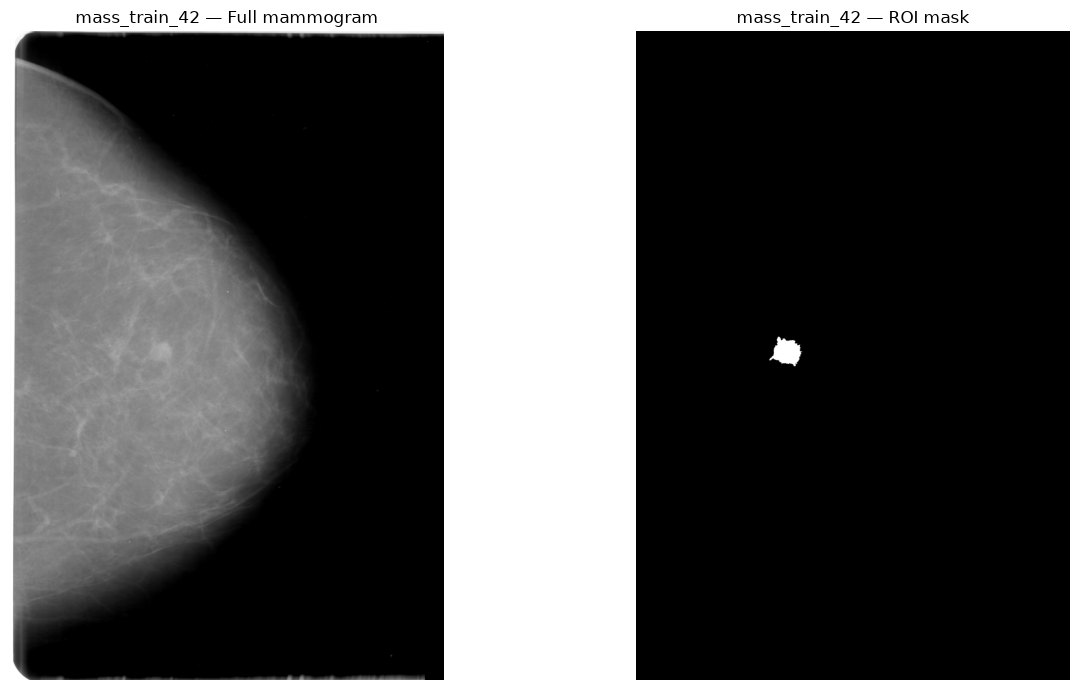


=== calc_test_62 ===
Full image shape: (4624, 3056)
Mask shape: (4688, 3088)
Same shape: False


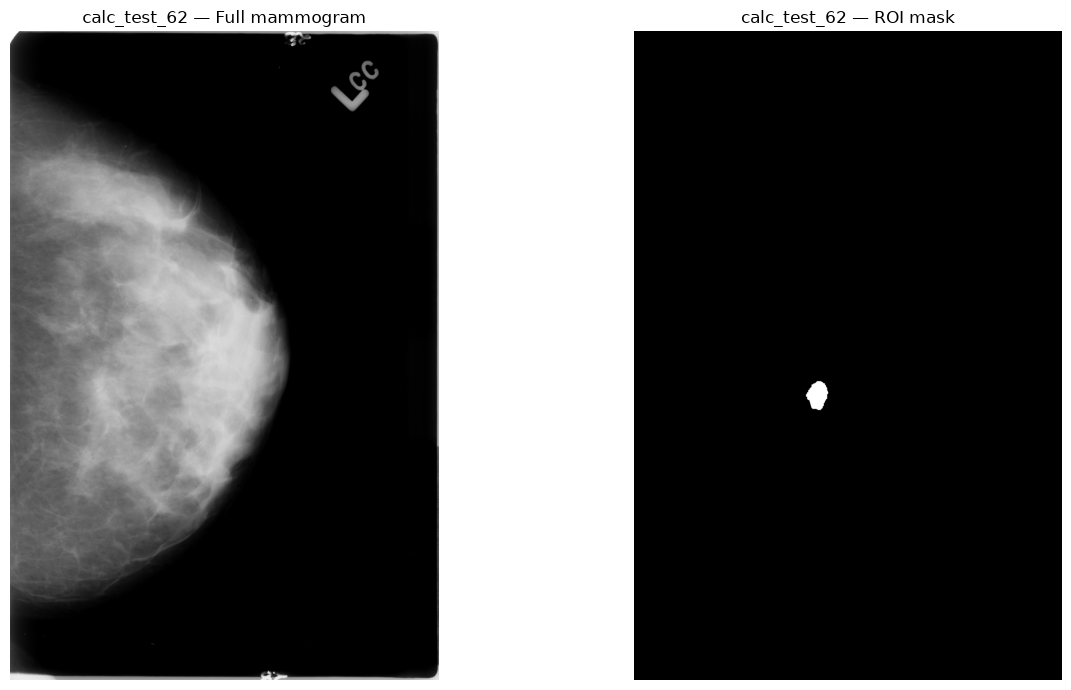

In [105]:
# Visual inspection hai trường hợp mismatch

import matplotlib.pyplot as plt
import numpy as np
import pydicom

selected_visual_ids = ["mass_train_42", "calc_test_62"]

for annotation_id in selected_visual_ids:

    row = roi_resolution.loc[
        roi_resolution["annotation_id"].eq(annotation_id)
    ].iloc[0]

    full_ds = pydicom.dcmread(
        str(row["full_image_file_path_resolved"])
    )
    mask_ds = pydicom.dcmread(
        str(row["roi_mask_file_path_resolved"])
    )

    full_img = full_ds.pixel_array
    mask_img = mask_ds.pixel_array

    print(f"\n=== {annotation_id} ===")
    print("Full image shape:", full_img.shape)
    print("Mask shape:", mask_img.shape)
    print("Same shape:", full_img.shape == mask_img.shape)

    fig, axes = plt.subplots(1, 2, figsize=(14, 7))

    axes[0].imshow(full_img, cmap="gray")
    axes[0].set_title(f"{annotation_id} — Full mammogram")
    axes[0].axis("off")

    axes[1].imshow(mask_img, cmap="gray")
    axes[1].set_title(f"{annotation_id} — ROI mask")
    axes[1].axis("off")

    plt.tight_layout()
    plt.show()

In [107]:
# STEP 11.8 — FINALIZE ROI MASK VALIDATION
import ast

# 1. KIỂM TRA ĐẦU VÀO

if "roi_mask_validation" not in globals():
    raise NameError("Không tìm thấy roi_mask_validation. Hãy chạy STEP 11.4 trước.")

if len(roi_mask_validation) != 3568:
    raise ValueError(
        f"Số annotation không đúng kỳ vọng: {len(roi_mask_validation)}"
    )

validation_final = roi_mask_validation.copy()

# 2. BỔ SUNG CÁC CHỈ SỐ VÀ CỜ KIỂM ĐỊNH

def parse_unique_values(value):
    """Đọc danh sách giá trị pixel đã lưu dưới dạng chuỗi."""
    if pd.isna(value):
        return None

    try:
        parsed = ast.literal_eval(value)
        return parsed if isinstance(parsed, list) else None
    except (ValueError, SyntaxError):
        return None


def calculate_foreground_fraction(row):
    """Tỷ lệ pixel foreground trên chính ROI mask."""
    shape = row["mask_shape"]
    count = row["nonzero_pixel_count"]

    if not isinstance(shape, tuple) or len(shape) != 2:
        return np.nan

    if pd.isna(count):
        return np.nan

    total_pixels = int(shape[0]) * int(shape[1])

    if total_pixels <= 0:
        return np.nan

    return int(count) / total_pixels


validation_final["mask_foreground_fraction"] = (
    validation_final.apply(calculate_foreground_fraction, axis=1)
)

validation_final["mask_values_binary"] = (
    validation_final["unique_values_sample"]
    .apply(parse_unique_values)
    .apply(
        lambda values:
        all(v in [0, 1, 255] for v in values)
        if values is not None else False
    )
)

# Bounding box được tính trên ma trận ROI mask.
validation_final["bbox_coordinate_space"] = "roi_mask_pixel_coordinates"

# Chỉ đánh dấu đủ điều kiện xem xét sử dụng trực tiếp trên full image
# khi mask hợp lệ về cấu trúc và có cùng kích thước.
validation_final["bbox_full_image_coordinate_eligible"] = (
    validation_final["mask_quality_status"].eq("structurally_valid")
    & validation_final["shape_match"].eq(True)
)

# Ghi chú riêng cho trường hợp không cùng kích thước.
validation_final["coordinate_note"] = np.where(
    validation_final["shape_match"],
    "Same matrix shape; spatial alignment still requires dataset-level validation",
    "Shape mismatch; do not transfer bbox to full-image coordinates"
)

# 3. TẠO BẢNG EXCEPTIONS

roi_mask_exceptions_final = validation_final.loc[
    validation_final["mask_quality_status"].ne("structurally_valid")
].copy()

# 4. TỔNG HỢP SUMMARY

summary_records = []

def add_summary(section, metric, category, count=None, value=None):
    summary_records.append({
        "section": section,
        "metric": metric,
        "category": category,
        "count": count,
        "value": value
    })


total_annotations = len(validation_final)

add_summary(
    "overall", "total_annotations", "all",
    count=total_annotations
)

# Trạng thái đọc file
for status, count in validation_final["mask_read_status"].value_counts(
    dropna=False
).items():
    add_summary("file_read", "mask_read_status", str(status), count=int(count))

for status, count in validation_final["full_header_status"].value_counts(
    dropna=False
).items():
    add_summary("file_read", "full_header_status", str(status), count=int(count))

# Trạng thái chất lượng
for status, count in validation_final["mask_quality_status"].value_counts(
    dropna=False
).items():
    add_summary("mask_quality", "mask_quality_status", str(status), count=int(count))

# Shape consistency
for status, count in validation_final["shape_match"].value_counts(
    dropna=False
).items():
    add_summary("shape", "shape_match", str(status), count=int(count))

# Giá trị pixel
for status, count in validation_final["mask_values_binary"].value_counts(
    dropna=False
).items():
    add_summary("pixel_values", "mask_values_binary", str(status), count=int(count))

# Mask rỗng
add_summary(
    "mask_content",
    "empty_masks",
    "is_empty_true",
    count=int(validation_final["is_empty"].eq(True).sum())
)

# Connected components
component_stats = validation_final["connected_components"].describe()

for stat_name, value in component_stats.items():
    add_summary(
        "connected_components",
        str(stat_name),
        "all_available_masks",
        value=float(value)
    )

# Tỷ lệ foreground trên ma trận mask
foreground_stats = validation_final["mask_foreground_fraction"].describe()

for stat_name, value in foreground_stats.items():
    add_summary(
        "foreground_fraction",
        str(stat_name),
        "all_available_masks",
        value=float(value)
    )

# Phân bố theo abnormality và split
for column in ["abnormality_type", "split"]:
    grouped = (
        validation_final
        .groupby([column, "mask_quality_status"], dropna=False)
        .size()
        .reset_index(name="count")
    )

    for _, item in grouped.iterrows():
        add_summary(
            f"breakdown_by_{column}",
            "mask_quality_status",
            str(item[column]) + " | " + str(item["mask_quality_status"]),
            count=int(item["count"])
        )

roi_mask_validation_summary = pd.DataFrame(summary_records)

# 5. KIỂM TRA LOGIC TRƯỚC KHI LƯU

status_counts = validation_final["mask_quality_status"].value_counts()

assert total_annotations == 3568
assert int(validation_final["mask_read_status"].eq("success").sum()) == 3568
assert int(validation_final["full_header_status"].eq("success").sum()) == 3568
assert int(validation_final["is_empty"].eq(True).sum()) == 0
assert int(validation_final["shape_match"].eq(False).sum()) == 80
assert int(status_counts.get("structurally_valid", 0)) == 3488
assert len(roi_mask_exceptions_final) == 80

# Không cho phép bbox của 80 trường hợp mismatch được đánh dấu
# đủ điều kiện sử dụng trực tiếp trên full image.
mismatch_rows = validation_final["shape_match"].eq(False)

assert not validation_final.loc[
    mismatch_rows,
    "bbox_full_image_coordinate_eligible"
].any()

# 6. XUẤT BA FILE

PROJECT_ROOT = Path(r"C:\Breast-Cancer-CBIS-DDSM")
OUTPUT_DIR = PROJECT_ROOT / "Data" / "processed"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

validation_path = OUTPUT_DIR / "nb02_roi_mask_validation.csv"
summary_path = OUTPUT_DIR / "nb02_roi_mask_validation_summary.csv"
exceptions_path = OUTPUT_DIR / "nb02_roi_mask_exceptions.csv"

validation_final.to_csv(
    validation_path, index=False, encoding="utf-8-sig"
)

roi_mask_validation_summary.to_csv(
    summary_path, index=False, encoding="utf-8-sig"
)

roi_mask_exceptions_final.to_csv(
    exceptions_path, index=False, encoding="utf-8-sig"
)

# 7. ĐỌC LẠI VÀ KIỂM TRA FILE ĐẦU RA

output_checks = []

for file_path, expected_rows in [
    (validation_path, 3568),
    (summary_path, len(roi_mask_validation_summary)),
    (exceptions_path, 80)
]:
    if not file_path.is_file():
        raise FileNotFoundError(file_path)

    check_df = pd.read_csv(file_path)

    output_checks.append({
        "file": file_path.name,
        "exists": file_path.is_file(),
        "expected_rows": expected_rows,
        "actual_rows": len(check_df),
        "columns": len(check_df.columns),
        "size_kb": round(file_path.stat().st_size / 1024, 2),
        "row_count_match": len(check_df) == expected_rows
    })

output_check_df = pd.DataFrame(output_checks)

if not output_check_df["row_count_match"].all():
    raise AssertionError("Có file đầu ra không khớp số dòng kỳ vọng.")

print("=== STEP 11.8 — FINAL VALIDATION ===")
print("Tổng annotation:", total_annotations)

print("\n=== MASK QUALITY ===")
display(
    validation_final["mask_quality_status"]
    .value_counts()
    .rename_axis("status")
    .to_frame("count")
)

print("\n=== EXCEPTIONS BY ABNORMALITY ===")
display(
    roi_mask_exceptions_final
    .groupby(["abnormality_type", "mask_quality_status"])
    .size()
    .rename("count")
    .to_frame()
)

print("\n=== OUTPUT FILE CHECK ===")
display(output_check_df)

print("\nĐã lưu tại:", OUTPUT_DIR)

=== STEP 11.8 — FINAL VALIDATION ===
Tổng annotation: 3568

=== MASK QUALITY ===


,count
status,
structurally_valid,3488
shape_mismatch,80



=== EXCEPTIONS BY ABNORMALITY ===


,,count
abnormality_type,mask_quality_status,
calcification,shape_mismatch,2
mass,shape_mismatch,78



=== OUTPUT FILE CHECK ===


,file,exists,expected_rows,actual_rows,columns,size_kb,row_count_match
0,nb02_roi_mask_validation.csv,True,3568,3568,30,2304.32,True
1,nb02_roi_mask_validation_summary.csv,True,36,36,5,2.23,True
2,nb02_roi_mask_exceptions.csv,True,80,80,30,49.25,True



Đã lưu tại: C:\Breast-Cancer-CBIS-DDSM\Data\processed


# Notebook 02 — Data Quality and Linkage

## 1. Tổng quan dữ liệu

- 4 bảng annotation: **3,568 dòng**
  - Calcification: 326 test, 1,546 train.
  - Mass: 378 test, 1,318 train.
- Metadata: **6,775 dòng**.
- DICOM index: **10,239 ảnh**.
- Không phát hiện duplicate rows chính xác trong các bảng annotation và index chính đã kiểm tra.
- Có missing values trong một số bảng; không tự động xóa hoặc điền trong Notebook 02.

## 2. Kết quả kiểm tra chính

### Annotation – DICOM linkage

- Phân giải được full image, cropped image và ROI mask cho **3,568/3,568 annotation** sau khi xử lý ngoại lệ `calc_train_344`.
- Có **104 annotation** có UID pair giữa crop và ROI khác nhau; không mặc định đây là lỗi.
- Việc liên kết sử dụng StudyInstanceUID, SeriesInstanceUID kết hợp SeriesDescription và ngữ cảnh thư mục.

### DICOM role classification

| Vai trò | Số lượng |
|---|---:|
| Full image | 3,103 |
| Cropped image | 3,568 |
| ROI mask | 3,568 |

Có 305 ROI mask được phân loại dựa trên suy luận heuristic và cần lưu ý khi sử dụng.

### Patient leakage

- Calcification train/test: 0 bệnh nhân overlap.
- Mass train/test: 0 bệnh nhân overlap.
- Khi kết hợp hai nhóm: **31 bệnh nhân overlap**.

Nếu xây dựng mô hình chung cho mass và calcification, cần chia lại dữ liệu theo PatientID.

### ROI mask validation

| Trạng thái | Số lượng |
|---|---:|
| structurally_valid | 3,488 |
| shape_mismatch | 80 |
| Tổng | 3,568 |

- 3,568/3,568 mask đọc thành công.
- Tất cả mask có 2 giá trị pixel; không có mask rỗng.
- 80 trường hợp mismatch gồm 78 mass và 2 calcification.
- Chưa đủ căn cứ xác định phép biến đổi không gian giữa các mask mismatch và full image.

**Lưu ý:** Không tự động resize mask hoặc chuyển bounding box của 80 trường hợp mismatch sang hệ tọa độ full image.

## 3. File kết quả

Các file được lưu tại `Data/processed`:

- `nb02_patient_split_overlap.csv`
- `nb02_csv_dicom_linkage.csv`
- `nb02_linkage_summary.csv`
- `nb02_linkage_review.csv`
- `nb02_table_quality_summary.csv`
- `nb02_data_quality_report.txt`
- `nb02_instance_role_proposals.csv`
- `nb02_instance_role_review.csv`
- `nb02_instance_role_final.csv`
- `nb02_roi_mask_validation.csv`
- `nb02_roi_mask_validation_summary.csv`
- `nb02_roi_mask_exceptions.csv`

## 4. Kết luận và chuyển tiếp

**Notebook 02 — COMPLETED.**

Đã hoàn thành kiểm tra chất lượng dữ liệu, liên kết annotation–DICOM, phân loại vai trò ảnh, patient leakage và validation ROI mask.

Notebook 03 tiếp tục với việc xây dựng annotation thống nhất và kiểm tra hệ tọa độ bounding box. Cần xác minh quan hệ giữa full image, cropped image và ROI mask trước khi chuyển đổi tọa độ hoặc sử dụng các trường hợp shape mismatch.